# Practicum_REVISION — BMC Public Health revision

Copy of `Practicum_FINAL_CLEANED.ipynb` (the original is untouched). Data, train/test split (636 / 159, stratified,
seed 42) and hyperparameter search spaces are unchanged. Run top-to-bottom with **Restart & Run All**.

**How to read this notebook**
- **Part A (sections 0–16)** is the original pipeline. Lines changed for the revision carry an inline tag
  (`[REV-0.x]`, `[R1.x]`, `[REV-cleanup]`) that says what changed and what it was before.
- **Part B** contains new cells only, one per reviewer item, each headed `# R…` / `# REV-…`.
- Every file is written as `rev_*` in `CSV_DIR` / `IMG_DIR`; no output of the original notebook is overwritten.

**Changes to the original pipeline (Part A)**
| Tag | Change |
|---|---|
| REV-0.1 | Bug fix: XGBoost `scale_pos_weight` was dropped when finalising tuned params (models trained unweighted even when the best trial was weighted). `finalize_xgb_params` now rebuilds it in `tune_xgb_params_auc`, `tune_xgb_params_sens`, `build_oof_xgb_at_spec`. Every fitted model's class weighting is logged (`WEIGHT_LOG`). |
| REV-0.2 | One M1–M5 model set (`final_models_xgb/cat`, AUC-tuned, refit on all 636 training rows) drives Fig 4/5, the PR/ROC and AP/AUC figures and all stage tables. Threshold per model: spec ≥ TARGET_SPEC (0.70 since REV-1.0) on pooled 5-fold OOF predictions within train; applied unchanged to test. Test-set 95% CIs at the fixed threshold: AUROC/AP/Brier 2,000-bootstrap (resample test rows); Sens/Spec/PPV/NPV exact Clopper–Pearson (REV-0.8). Every table also reports the no-skill ("Null") Brier = Brier of predicting the training TB prevalence for everyone (REV-0.7). Replaces `eval_stage_cat/xgb`, which re-tuned a second model set. |
| REV-1.0 | **Primary operating point changed from specificity ≥ 0.80 to ≥ 0.70** (WHO triage target product profile: sensitivity ≥ 90 %, specificity ≥ 70 %): `TARGET_SPEC` and the `threshold_at_spec` default = 0.70. Thresholds of every fitted model are recomputed (max sensitivity s.t. specificity ≥ 0.70 on pooled 5-fold training OOF predictions; highest-specificity point if none qualifies) and applied unchanged to test. The fitted AUC-tuned models (M1–M5, full-feature, top-k, resampled) do not depend on the target and are unchanged. The nested-CV full-feature comparison (Table 2 / Fig 2) re-tunes at ≥ 0.70 and reports the mean fold threshold. Specificity sweep now 0.70–0.90. |
| REV-0.9 | "Brier (recal.)" column: logistic (Platt) recalibration of each model fitted on its TRAINING out-of-fold predictions, applied unchanged to test. Only Brier/calibration use it; AUROC, AP, threshold and Sens/Spec/PPV/NPV stay on the raw scale. Added because several M1–M3 models stop after very few trees (CatBoost) or are shifted by class weights (XGBoost), giving raw probabilities no better than the no-skill reference (see REV-0.7). |
| REV-0.8 | Sens/Spec/PPV/NPV CIs exact Clopper–Pearson (percentile bootstrap collapsed to a point at 0 % / 100 %); Table 1 uses 2 decimals for small-valued variables; R1.2b summary wording follows the p-value. |
| REV-0.4 | Single seed (42) for tuning, CV folds, RFE, final fits, bootstrap and the noise column (were 42/123/165/42+fold/789). |
| REV-cleanup | Removed duplicated definitions, a superseded Table 1 cell and a debug cell; fixed outputs that overwrote each other and variables that shadowed `y`/`df`/`rng`; the specificity-target sweep reuses the primary-target nested-CV run. |
| REV-0.6 | **Outcome leakage fix:** `tb_history_composite` included the chart-review item "recently diagnosed with TB?" (Yes in 130/176 TB cases, 0/619 non-cases). Replaced everywhere by `tb_history_prior` = interview item "Have you ever had TB in the past?" ("Don't know" → No). |
| R1.3 (hook) | `apply_resampler` hook in tuning and OOF helpers; inactive except in the R1.3 cell. |
| R1.5 | Figure 5 (5 × 3 SHAP grid): bold panel labels A–C, "ATB" display text → "TB disease", 300 dpi. |
| R3.1 | Section 16 rewritten: bacteriologically confirmed TB vs no TB; clinician-diagnosed-only cases excluded; original split kept. |

**New analyses (Part B)**
| Cell | Content | Main outputs |
|---|---|---|
| REV-0.3 | Table 1 (n = 795), outcome composition, HIV prevalence | `rev_table1_analytic_sample.csv`, `rev_outcome_detail_counts.csv`, `rev_hiv_counts.csv` |
| REV-0.6 | TB-history leakage check; M1–M5 re-run with the original composite (supplementary) | `rev_tbhistory_leakage_check.csv`, `rev_tbhistory_original_composite_sensitivity.csv` |
| REV-1.1 | Test sens/spec by specificity target (full-feature, M5); WHO triage TPP check for M5 | `rev_test_sens_spec_by_spec_target_fullfeature_M5.csv`, `rev_who_tpp_check_M5.csv` |
| REV-0.7 | Probability diagnostics (trees, prediction spread, Brier skill, calibration) | `rev_probability_diagnostics.csv` |
| R1.4 | Apparent vs CV vs test; paired bootstrap ΔAUC | `rev_train_cv_test_metrics.csv`, `rev_paired_bootstrap_auc_tests.csv` |
| R1.2a | Top-10 / top-15 one-step SHAP models | `rev_topk_models.csv` |
| R1.2b | QFT vs TB history | `rev_qft_tbhistory_*` |
| R1.3 | Over/undersampling sensitivity, calibration | `rev_resampling_sensitivity.csv`, `rev_calibration_resampling_sensitivity.png` |
| R2.5–2.7 | Age groups, age ≥ 15, QFT-excluded, subgroups | `rev_age_group_counts.csv`, `rev_age15plus_sensitivity.csv`, `rev_qft_excluded_sensitivity.csv`, `rev_subgroup_performance_oof795.csv` |
| R3.2 | Participants without CXR | `rev_cxr_included_vs_excluded.csv`, `rev_all_eligible_M1M2_vs_cxr_restricted.csv`, `rev_noCXR_holdout_M1M2.csv` |
| REV-0.1 | Class-weighting audit (last cell; covers every model fitted above) | `rev_class_weighting_audit*.csv` |


## Part A — Original pipeline (revised in place; see tags in the code)

In [1]:
# =============== 0) IMPORTS & GLOBAL CONFIG ===============

# ---- Standard library
import os, json, tempfile, logging

# ---- Core scientific stack
import numpy as np
import pandas as pd

# ---- Plotting
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# ---- Statistics
from scipy.stats import chi2_contingency, fisher_exact, ttest_ind

# ---- Scikit-learn
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_curve, roc_auc_score, average_precision_score, precision_recall_curve,
    brier_score_loss, confusion_matrix
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin  # for model wrappers

# ---- Gradient-boosting libs
from catboost import CatBoostClassifier
from xgboost import DMatrix, train as xgb_train

# ---- Hyperparameter tuning
import optuna
from optuna.samplers import TPESampler

# ---- Pandas categorical dtype helpers
from pandas.api.types import CategoricalDtype as CatDType

# ---- Plot style (set once here)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

# ---- Silence Optuna console output
optuna.logging.set_verbosity(optuna.logging.ERROR)  # or optuna.logging.CRITICAL
try:
    optuna.logging.disable_default_handler()
    optuna.logging.disable_propagation()
except Exception:
    pass

# Belt-and-suspenders via stdlib logging
logging.getLogger("optuna").setLevel(logging.ERROR)
logging.getLogger("optuna").propagate = False


# ---------- PATHS ----------
BASE_DIR = "/Users/hbattey/Desktop/Rodwell"
IMG_DIR  = f"{BASE_DIR}/Output/Images"
CSV_DIR  = f"{BASE_DIR}/Output/csv"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(CSV_DIR, exist_ok=True)

# ---------- GLOBAL CONFIG ----------
# seeds
split_seed           = 42
params_seed          = 42   # [REV-0.4] single seed everywhere (was 123)
random_feature_seed  = 42   # [REV-0.4] single seed everywhere (was 789)

# nested-CV / tuning
TARGET_SPEC = 0.70  # [REV-1.0] primary operating point = WHO triage TPP (sens >= 0.90, spec >= 0.70); was 0.80
N_OUTER     = 5
N_INNER     = 3
N_TRIALS    = 30
RANDOM_STATE = split_seed

# permutation-importance repeats (keep one value used everywhere)
N_PI_REPEATS = 200  # was sometimes 50 — use one value consistently

# single, canonical name for the random/noise feature
RAND_NAME = "rand_noise"

# pretty-name mapping (extend as needed)
rename_dict = {
    "Score": "qXR Score",
    "lived_with_another_tb": "History of contact with TB disease case",  # [R1.5] was "...ATB case"
    "tb_history_prior": "Prior TB disease (self-report)",  # [R1.5]/[REV-0.6] was "ATB History"
    "CBC_LYM_freq": "LYM", "CBC_NEU_freq": "NEU",
    "QFT_result_composite": "QFT result",
    "age": "Age", "bmi": "BMI", "gender": "Sex", "bcg": "BCG vax",
    "diabetes": "Diabetes", "race_collapsed": "Race", "asthma": "Asthma",
    "night_sweats": "Night sweats", "weight_loss": "Weight loss",
    "shortness_of_breath": "Shortness breath", "persistent_cough": "Persistent cough",
    "cough_blood": "Hemoptysis", "fatigue": "Fatigue", "fever": "Fever",
    "lung_nodules": "Nodules", "lung_cavities": "Cavities", "lung_infiltrates": "Infiltrates",
    "imaging_tb": "Provider CXR interpret", "lymph_nodes": "Lymphadenopathy",
    "CBC_HCT": "HCT", "CBC_PCT": "PCT", "CBC_PLT": "PLT", "CBC_MCV": "MCV",
    "CBC_MCH": "MCH", "CBC_RBC": "RBC", "CBC_PDW": "PDW", "CBC_RDW_SD": "RDW_SD",
    "CBC_WBC": "WBC", "CBC_MPV": "MPV", "CBC_MCHC": "MCHC", "CBC_P_LCR": "P_LCR",
    "CBC_RDW_CV": "RDW_CV", "pleural_effusion": "Pleural effusion", "CBC_HGB": "HGB",
    RAND_NAME: "Random noise (control)"
}


In [2]:
# =============== 1) LOAD, CLEAN, SPLIT, RANDOM CONTROL ===============
file_path = r"/Users/hbattey/Desktop/Rodwell/Datasets/Checkpoints/Pakistan_imputed_minimal.xlsx"
df0 = pd.read_excel(file_path)

# Add TB_status_detailed from the master dataset for a sensitivity check.
master_tb_file = r"/Users/hbattey/Desktop/Rodwell/Datasets/TB_Antigen_Clinical_Data_Master_v3.0-08.30.24.xlsx"
master_tb = pd.read_excel(master_tb_file, sheet_name="Dataset",
                          usecols=["record_id", "TB_status_detailed", "tb_history_foreign_interview"])  # [REV-0.6]
df0 = df0.merge(master_tb, on="record_id", how="left", validate="one_to_one")

# [REV-0.6] TB history. The original tb_history_composite also counts the baseline chart-review item "Has the
# patient recently been diagnosed with TB?", which is Yes for 130/176 TB cases and 0/619 non-cases, i.e. it
# encodes the outcome. Use the interview item "Have you ever had TB in the past?" instead ("Don't know" -> No,
# as for household contact), in the same column position. The original is kept only for the REV-0.6 check.
_tbh_pos = df0.columns.get_loc("tb_history_composite")
df0.insert(_tbh_pos, "tb_history_prior",
           df0["tb_history_foreign_interview"].map({"Yes": "Yes", "No": "No", "Don't know": "No"}))
assert df0["tb_history_prior"].notna().all()
TB_HISTORY_ORIGINAL = df0.pop("tb_history_composite")
df0 = df0.drop(columns=["tb_history_foreign_interview"])

df0["TB_status_detailed"] = df0["TB_status_detailed"].astype("string").str.strip()
missing_details = df0["TB_status_detailed"].isna().sum()
if missing_details:
    print(f"WARNING: {missing_details} records missing TB_status_detailed after merge")

# Alternative outcome definitions for sensitivity:
# - bacteriologically confirmed ATB only
# - inclusive ATB that also includes clinician diagnosis
# Keep these as analysis flags but do not use in downstream modeling features.
df0["TB_status_bac_only"] = np.where(
    df0["TB_status_detailed"] == "ATB-bacteriologically confirmed", 1, 0
)
df0["TB_status_including_clinician"] = np.where(
    df0["TB_status_detailed"].isin([
        "ATB-bacteriologically confirmed",
        "ATB-clinician diagnosed at baseline",
    ]),
    1,
    0,
)
df0["TB_status_clinician_only"] = np.where(
    df0["TB_status_detailed"] == "ATB-clinician diagnosed at baseline", 1, 0
)

# Ensure binary target is 0/1
if df0["TB_status"].dtype == object:
    df0["TB_status"] = df0["TB_status"].map({"atb": 1, "non_atb": 0})
df0["TB_status"] = df0["TB_status"].astype(int)

print("TB_status_detailed counts:")
print(df0["TB_status_detailed"].value_counts(dropna=False))
print("Original TB_status atb count:", df0["TB_status"].sum())
print("Bacteriologic-only ATB count:", df0["TB_status_bac_only"].sum())
print("Inclusive ATB count:", df0["TB_status_including_clinician"].sum())
print("Clinician-diagnosed only count:", df0["TB_status_clinician_only"].sum())
print(pd.crosstab(
    df0["TB_status"],
    df0["TB_status_including_clinician"],
    rownames=["original"],
    colnames=["incl_clinician"],
))

# Features / target
# Drop the new outcome flags from the feature matrix so they are not used as predictors.
drop_cols = [
    "record_id",
    "TB_status",
    "TB_status_detailed",
    "TB_status_bac_only",
    "TB_status_including_clinician",
    "TB_status_clinician_only",
]
X = df0.drop(columns=drop_cols)
y = df0["TB_status"].astype(int)

# Detect categorical columns (object/bool/category)
cat_cols_all = X.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

# Split (stratified)
feature_train, feature_test, target_train, target_test = train_test_split(
    X, y, test_size=0.20, random_state=split_seed, stratify=y
)

# ---------- RANDOM CONTROL FEATURE ----------
# RAND_NAME and random_feature_seed are set once in cell 0 ([REV-cleanup]: duplicates removed here).
# The noise column is injected later ONLY for the permutation-importance refit (PI-only).

# Make sure cat list never contains RAND_NAME
if RAND_NAME in cat_cols_all:
    cat_cols_all = [c for c in cat_cols_all if c != RAND_NAME]

print(f"Train n={len(feature_train)} | Test n={len(feature_test)} | Pos rate={target_train.mean():.3f}")

TB_status_detailed counts:
TB_status_detailed
LTBI                                   323
NTBI                                   267
ATB-bacteriologically confirmed        162
Not Active TB-QFT Indeterminate         29
ATB-clinician diagnosed at baseline     14
Name: count, dtype: Int64
Original TB_status atb count: 176
Bacteriologic-only ATB count: 162
Inclusive ATB count: 176
Clinician-diagnosed only count: 14
incl_clinician    0    1
original                
0               619    0
1                 0  176
Train n=636 | Test n=159 | Pos rate=0.222


In [3]:
# =============== 2) CATEGORICAL CANON & ALIGNMENT ===============
# Infer cats from TRAIN unless user provided CATS
CATS = [c for c in cat_cols_all if c in feature_train.columns]
if not CATS:
    CATS = feature_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# --- NEW: per-fold categorical helpers ---
def build_cat_dtypes_from_train(X_tr: pd.DataFrame, cats: list[str]) -> dict[str, CatDType]:
    dt_map = {}
    for c in cats:
        if c not in X_tr.columns:
            continue
        s0 = X_tr[c]
        if not isinstance(s0.dtype, pd.CategoricalDtype):
            s0 = s0.astype("category")
        cats_ = s0.cat.categories.tolist()
        if "__OTHER__" not in cats_:
            cats_.append("__OTHER__")
        dt_map[c] = CatDType(categories=cats_, ordered=False)
    return dt_map

def align_categoricals_with(dt_map: dict[str, CatDType], df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    for c, dt in dt_map.items():
        if c not in out.columns:
            continue
        s = out[c]
        if not isinstance(s.dtype, pd.CategoricalDtype):
            s = s.astype("category")
        dt_cats = list(dt.categories)
        if "__OTHER__" in dt_cats and "__OTHER__" not in s.cat.categories:
            s = s.cat.add_categories(["__OTHER__"])
        # send unseen levels to __OTHER__
        if "__OTHER__" in dt_cats:
            s = s.where(s.isin(dt_cats), "__OTHER__")
        s = s.cat.set_categories(dt_cats)
        out[c] = s
    return out

# --- For global train/test split (not CV) we still need a base map ---
_CAT_DTYPES = build_cat_dtypes_from_train(feature_train, CATS)

def align_categoricals(df: pd.DataFrame) -> pd.DataFrame:
    return align_categoricals_with(_CAT_DTYPES, df)

# Apply alignment + freeze column order
feature_train = align_categoricals(feature_train)
feature_test  = align_categoricals(feature_test)
feature_test  = feature_test.reindex(columns=feature_train.columns)

# Class imbalance scalar
neg, pos  = (target_train == 0).sum(), (target_train == 1).sum()
SCALE_POS = float(neg / pos) if pos > 0 else 1.0


In [4]:
# =============== 3) SHARED HELPERS ===============
def as_proba(p):
    p = np.asarray(p)
    if p.ndim == 2 and p.shape[1] == 2:
        p = p[:, 1]
    if np.nanmax(p) > 1.0 or np.nanmin(p) < 0.0:
        rng = float(np.nanmax(p) - np.nanmin(p))
        if rng > 1.5:  # logits-ish
            p = 1.0 / (1.0 + np.exp(-p))
        p = np.clip(p, 0.0, 1.0)
    return p.astype(float)

def threshold_at_spec(y_val, p_val, target_spec=0.70):  # [REV-1.0] default was 0.80
    """
    Pick a decision threshold that achieves specificity ≥ target_spec.
    Among feasible points, maximize recall; tie-break by higher specificity.
    Avoids the 'inf' threshold from sklearn. Returns (thr, recall, specificity).
    """
    y_val = np.asarray(y_val).astype(int)
    p_val = as_proba(p_val)

    fpr, tpr, thr = roc_curve(y_val, p_val)

    # Drop the first (inf) threshold to avoid "predict all negatives"
    fpr, tpr, thr = fpr[1:], tpr[1:], thr[1:]

    spec = 1.0 - fpr
    feas_idx = np.flatnonzero(spec >= float(target_spec))

    if feas_idx.size:
        # Primary: max recall; secondary: higher specificity
        best_local = np.argmax(tpr[feas_idx] + 1e-6 * spec[feas_idx])
        idx = int(feas_idx[best_local])
    else:
        # If target is unattainable, pick the point with highest specificity
        idx = int(np.argmax(spec))

    # roc_curve defines positives as (score > thr). If your code uses (>= thr),
    # nudge threshold down by one ULP so (p >= thr_use) ≈ (p > thr_orig).
    thr_use = np.nextafter(float(thr[idx]), -np.inf)

    return float(thr_use), float(tpr[idx]), float(spec[idx])



def sens_spec_ppv_npv(y_true, probs, thr):
    preds = (as_proba(probs) >= float(thr)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    sens = tp/(tp+fn) if (tp+fn) else 0.0
    spec = tn/(tn+fp) if (tn+fp) else 0.0
    ppv  = tp/(tp+fp) if (tp+fp) else 0.0
    npv  = tn/(tn+fn) if (tn+fn) else 0.0
    return sens, spec, ppv, npv

def safe_train_val_split(X_tr_full, y_tr_full, test_size=0.20, min_per_class_val=2, seed=RANDOM_STATE):
    # Try shrinking val size until both classes appear, but NEVER return train as val
    for ts in [test_size, 0.20, 0.15, 0.10]:
        try:
            X_tr, X_val, y_tr, y_val = train_test_split(
                X_tr_full, y_tr_full,
                test_size=ts,
                stratify=y_tr_full if y_tr_full.nunique() > 1 else None,
                random_state=seed, shuffle=True
            )
            vc = y_val.value_counts()
            if vc.get(0, 0) >= min_per_class_val and vc.get(1, 0) >= min_per_class_val:
                return X_tr, X_val, y_tr, y_val, False
        except Exception:
            continue

    # fallback: at least return disjoint train/val
    idx = np.arange(len(y_tr_full))
    rng = np.random.default_rng(seed)
    rng.shuffle(idx)
    cut = max(1, int(0.1 * len(idx)))
    val_idx = idx[:cut]
    tr_idx  = idx[cut:]
    return (
        X_tr_full.iloc[tr_idx],
        X_tr_full.iloc[val_idx],
        y_tr_full.iloc[tr_idx],
        y_tr_full.iloc[val_idx],
        True
    )
    
def mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full, y_tr_full, cats, n_inner, seed, target_spec):
    skf_inner = StratifiedKFold(n_splits=max(2, n_inner), shuffle=True, random_state=seed)
    recalls = []
    for it, iv in skf_inner.split(X_tr_full, y_tr_full):
        Xt, Xv = X_tr_full.iloc[it].copy(), X_tr_full.iloc[iv].copy()
        yt, yv = y_tr_full.iloc[it],       y_tr_full.iloc[iv]

        # *** Build per-inner-fold category map from Xt (train of inner fold) ***
        dt_map = build_cat_dtypes_from_train(Xt, cats)

        # Split Xt into train/val and align ALL with dt_map (no peeking)
        X_tr, X_val, y_tr, y_val, _ = safe_train_val_split(Xt, yt, test_size=0.2, seed=seed)
        X_tr  = align_categoricals_with(dt_map, X_tr)
        X_val = align_categoricals_with(dt_map, X_val)
        Xv    = align_categoricals_with(dt_map, Xv)

        model = model_maker()
        if isinstance(model, CatBoostClassifier):
            cat_idx_tr = [X_tr.columns.get_loc(c) for c in cats if c in X_tr.columns]
            model.fit(
                X_tr, y_tr,
                eval_set=(X_val, y_val),
                cat_features=cat_idx_tr if len(cat_idx_tr) else None,
                early_stopping_rounds=80,
                verbose=False
            )
            p_val = as_proba(model.predict_proba(X_val))
            thr, sens_at_thr, _ = threshold_at_spec(y_val, p_val, target_spec)
            p_v  = as_proba(model.predict_proba(Xv))
        elif isinstance(model, dict):  # XGB params
            dtr  = DMatrix(X_tr,  label=y_tr,  enable_categorical=True)
            dval = DMatrix(X_val, label=y_val, enable_categorical=True)
            dv   = DMatrix(Xv,    label=yv,    enable_categorical=True)
            booster = xgb_train(model, dtr, num_boost_round=2000,
                                evals=[(dval,"val")], early_stopping_rounds=80, verbose_eval=False)
            p_val = as_proba(booster.predict(dval))
            thr, sens_at_thr, _ = threshold_at_spec(y_val, p_val, target_spec)
            p_v  = as_proba(booster.predict(dv))
        else:
            raise ValueError("model_maker must return CatBoostClassifier or XGBoost params dict")

        sens, _, _, _ = sens_spec_ppv_npv(yv, p_v, thr)
        if np.isnan(sens) or np.isinf(sens):
            sens = float(sens_at_thr)
        recalls.append(float(sens))

    return float(np.mean(recalls)) if len(recalls) else 0.0

def finalize_xgb_params(best_params: dict, *, seed: int, scale_pos: float | None = None) -> dict:
    p = dict(best_params)
    # [REV-0.1] study.best_params holds use_weights / w_mult but not scale_pos_weight (that is computed
    # inside suggest()), so rebuild it here; previously final XGB models silently trained unweighted.
    if "use_weights" in p:
        if scale_pos is None:
            raise ValueError("scale_pos is required when best_params carries use_weights")
        use_weights = p.pop("use_weights")
        w_mult      = p.pop("w_mult", 1.0)
        p["scale_pos_weight"] = float(scale_pos) * float(w_mult) if use_weights else 1.0
    else:
        p.pop("w_mult", None)
    p.setdefault("objective", "binary:logistic")
    p.setdefault("eval_metric", "auc")
    p.setdefault("tree_method", "hist")
    p.setdefault("seed", int(seed))
    return p

def finalize_cat_params(best_params: dict, *, scale_pos: float, seed: int, iterations: int) -> dict:
    p = dict(best_params)
    use_weights = p.pop("use_weights", False)
    w_mult      = p.pop("w_mult", 1.0)
    bt = p.get("bootstrap_type", "Bayesian")
    if bt == "Bayesian":
        p.pop("subsample", None)
    else:
        p.pop("bagging_temperature", None)
    if use_weights:
        p["class_weights"] = [1.0, float(w_mult) * float(scale_pos)]
    p.update(
        iterations=int(iterations),
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=int(seed),
        verbose=0,
    )
    return p

# [REV-0.1] Record the class weighting each fitted model actually ends up with.
WEIGHT_LOG = []
WEIGHT_CONTEXT = "main"

def log_weighting(source, algo, params):
    if algo == "XGB":
        spw = float(params.get("scale_pos_weight", 1.0))
        weighted, detail = (spw != 1.0), f"scale_pos_weight={spw:.3f}"
    else:
        cw = params.get("class_weights")
        weighted = cw is not None and float(cw[1]) != float(cw[0])
        detail = f"class_weights=[{float(cw[0]):.3f}, {float(cw[1]):.3f}]" if cw is not None else "class_weights=None"
    WEIGHT_LOG.append(dict(Outcome=WEIGHT_CONTEXT, Source=source, Algo=algo,
                           Weighted=bool(weighted), Detail=detail))

# [R1.3] Optional resampling of TRAINING data only (inner-train folds, OOF-threshold training folds,
# final refit). None = off; only the R1.3 sensitivity cell sets it.
RESAMPLER = None

def apply_resampler(X_tr, y_tr):
    return (X_tr, y_tr) if RESAMPLER is None else RESAMPLER(X_tr, y_tr)


In [5]:
# =============== 4) TUNING HELPERS (AUC & SENS) ===============
def tune_cat_params_auc(X_tr_full, y_tr_full, feats, seed, n_inner=N_INNER, n_trials=N_TRIALS):
    def objective(trial):
        params = dict(
            iterations=2000,
            learning_rate=trial.suggest_float("learning_rate", 0.05, 0.10),
            depth=trial.suggest_int("depth", 3, 7),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
            rsm=trial.suggest_float("rsm", 0.70, 0.95),
            min_data_in_leaf=trial.suggest_int("min_data_in_leaf", 1, 32),
            loss_function="Logloss", eval_metric="AUC",
            random_seed=seed, verbose=0
        )
        bt = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"])
        params["bootstrap_type"] = bt
        if bt == "Bayesian":
            params["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.0, 1.0)
        else:
            params["subsample"] = trial.suggest_float("subsample", 0.70, 0.95)
        use_weights = trial.suggest_categorical("use_weights", [True, False])
        w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
        if use_weights:
            params["class_weights"] = [1.0, w_mult * SCALE_POS]

        inner = StratifiedKFold(n_splits=n_inner, shuffle=True, random_state=seed)
        aucs, rounds = [], []
        for it, iv in inner.split(X_tr_full, y_tr_full):
            Xt, Xv = X_tr_full.iloc[it][feats].copy(), X_tr_full.iloc[iv][feats].copy()
            yt, yv = y_tr_full.iloc[it], y_tr_full.iloc[iv]

            # *** per-inner-fold categorical map ***
            dt_map = build_cat_dtypes_from_train(Xt, CATS)
            Xt = align_categoricals_with(dt_map, Xt)
            Xv = align_categoricals_with(dt_map, Xv)
            Xt, yt = apply_resampler(Xt, yt)  # [R1.3] inner-train fold only; Xv stays untouched

            cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
            m = CatBoostClassifier(**params)
            m.fit(Xt, yt, eval_set=(Xv, yv), cat_features=cat_idx if len(cat_idx) else None,
                  early_stopping_rounds=80, verbose=False)
            aucs.append(roc_auc_score(yv, m.predict_proba(Xv)[:,1]))
            rounds.append(int(m.get_best_iteration() or params["iterations"]))
        trial.set_user_attr("best_rounds", int(np.median(rounds)))
        return float(np.mean(aucs))

    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    params_final = finalize_cat_params(
        best_params=study.best_params.copy(),
        scale_pos=SCALE_POS, seed=seed,
        iterations=study.best_trial.user_attrs.get("best_rounds", 1200)
    )
    return params_final, study


def tune_xgb_params_auc(X_tr_full, y_tr_full, feats, seed, n_inner=N_INNER, n_trials=N_TRIALS):
    def suggest(trial):
        use_weights = trial.suggest_categorical("use_weights", [True, False])
        w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
        spw         = (SCALE_POS * w_mult) if use_weights else 1.0
        return {
            "learning_rate":     trial.suggest_float("learning_rate", 0.05, 0.10),
            "max_depth":         trial.suggest_int("max_depth", 3, 7),
            "subsample":         trial.suggest_float("subsample", 0.70, 0.95),
            "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.70, 0.95),
            "min_child_weight":  trial.suggest_int("min_child_weight", 1, 10),
            "lambda":            trial.suggest_float("lambda", 1.0, 10.0),
            "alpha":             trial.suggest_float("alpha", 0.0, 10.0),
            "gamma":             trial.suggest_float("gamma", 0.0, 5.0),
            "scale_pos_weight":  float(spw),
            "objective": "binary:logistic",
            "eval_metric": "auc",
            "tree_method": "hist",
            "seed": seed
        }

    def objective(trial):
        params = suggest(trial)
        inner = StratifiedKFold(n_splits=n_inner, shuffle=True, random_state=seed)
        aucs, rounds = [], []
        for it, iv in inner.split(X_tr_full, y_tr_full):
            Xt, Xv = X_tr_full.iloc[it][feats].copy(), X_tr_full.iloc[iv][feats].copy()
            yt, yv = y_tr_full.iloc[it], y_tr_full.iloc[iv]

            # *** per-inner-fold categorical map ***
            dt_map = build_cat_dtypes_from_train(Xt, CATS)
            Xt = align_categoricals_with(dt_map, Xt)
            Xv = align_categoricals_with(dt_map, Xv)
            Xt, yt = apply_resampler(Xt, yt)  # [R1.3] inner-train fold only; Xv stays untouched

            dtr  = DMatrix(Xt, label=yt, enable_categorical=True)
            dval = DMatrix(Xv, label=yv, enable_categorical=True)
            m = xgb_train(params, dtr, num_boost_round=2000,
                          evals=[(dval,"val")], early_stopping_rounds=80, verbose_eval=False)
            aucs.append(roc_auc_score(yv, m.predict(dval)))
            rounds.append(int(m.best_iteration or 0) + 1)
        trial.set_user_attr("best_rounds", int(np.median(rounds)))
        return float(np.mean(aucs))

    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    best = finalize_xgb_params(study.best_params.copy(), seed=seed, scale_pos=SCALE_POS)  # [REV-0.1]
    best_rounds = int(study.best_trial.user_attrs.get("best_rounds", 800))
    return (best, best_rounds), study

def tune_cat_params_sens(X_tr_full, y_tr_full, feats, seed, target_spec=TARGET_SPEC):
    def objective(trial):
        params = dict(
            iterations=2000,
            learning_rate=trial.suggest_float("learning_rate", 0.05, 0.10),
            depth=trial.suggest_int("depth", 3, 7),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
            rsm=trial.suggest_float("rsm", 0.70, 0.95),
            min_data_in_leaf=trial.suggest_int("min_data_in_leaf", 1, 32),
            loss_function="Logloss", eval_metric="AUC",
            random_seed=seed, verbose=0
        )
        bt = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"])
        params["bootstrap_type"] = bt
        if bt == "Bayesian":
            params["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.0, 1.0)
        else:
            params["subsample"] = trial.suggest_float("subsample", 0.70, 0.95)
        use_weights = trial.suggest_categorical("use_weights", [True, False])
        w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
        if use_weights:
            params["class_weights"] = [1.0, w_mult * SCALE_POS]
        def model_maker(): return CatBoostClassifier(**finalize_cat_params(params, scale_pos=SCALE_POS, seed=seed, iterations=2000))
        return mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full[feats], y_tr_full, CATS, N_INNER, seed, target_spec)
    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.optimize(objective, n_trials=N_TRIALS)
    params_final = finalize_cat_params(study.best_params.copy(), scale_pos=SCALE_POS, seed=seed, iterations=2000)
    return params_final, study

def tune_xgb_params_sens(X_tr_full, y_tr_full, feats, seed, target_spec=TARGET_SPEC):
    def suggest(trial):
        use_weights = trial.suggest_categorical("use_weights", [True, False])
        w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
        spw         = (SCALE_POS * w_mult) if use_weights else 1.0
        return finalize_xgb_params({
            "learning_rate":     trial.suggest_float("learning_rate", 0.05, 0.10),
            "max_depth":         trial.suggest_int("max_depth", 3, 7),
            "subsample":         trial.suggest_float("subsample", 0.70, 0.95),
            "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.70, 0.95),
            "min_child_weight":  trial.suggest_int("min_child_weight", 1, 10),
            "lambda":            trial.suggest_float("lambda", 1.0, 10.0),
            "alpha":             trial.suggest_float("alpha", 0.0, 10.0),
            "gamma":             trial.suggest_float("gamma", 0.0, 5.0),
            "scale_pos_weight":  float(spw),
        }, seed=seed)
    def objective(trial):
        params = suggest(trial)
        def model_maker(): return params
        return mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full[feats], y_tr_full, CATS, N_INNER, seed, target_spec)
    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.optimize(objective, n_trials=N_TRIALS)
    return finalize_xgb_params(study.best_params.copy(), seed=seed, scale_pos=SCALE_POS), study  # [REV-0.1]


In [6]:
# =============== 5) TRAIN FINAL MODELS FOR PI (AUC-TUNED) ===============
# Strategy:
# 1) TUNE on CLEAN features (no random).
# 2) REFIT models with the best params on a copy of training data AUGMENTED with RAND_NAME,
#    used ONLY for permutation-importance (PI).

# CLEAN training frame (no random)
X_train_clean = feature_train.copy()
y_train_all   = target_train.astype(int).copy()

# ---- Tune CatBoost on CLEAN features using AUROC ----
cat_feats_clean = list(X_train_clean.columns)
cat_params_final, study_cat = tune_cat_params_auc(
    X_train_clean, y_train_all, cat_feats_clean, seed=params_seed
)

# ---- Tune XGBoost on CLEAN features using AUROC ----
xgb_feats_clean = list(X_train_clean.columns)
(xgb_params_final, xgb_rounds), study_xgb = tune_xgb_params_auc(
    X_train_clean, y_train_all, xgb_feats_clean, seed=params_seed
)

# ---------- PI-ONLY REFIT with RANDOM FEATURE ----------
# Create a copy augmented with the random control column for PI only
X_train_pi = X_train_clean.copy()
if RAND_NAME not in X_train_pi.columns:
    X_train_pi[RAND_NAME] = np.random.default_rng(random_feature_seed).random(len(X_train_pi))

# Fit CatBoost for PI
cat_idx_pi = [X_train_pi.columns.get_loc(c) for c in CATS if c in X_train_pi.columns]
est_cat = CatBoostClassifier(**cat_params_final)
est_cat.fit(
    align_categoricals(X_train_pi), y_train_all,
    cat_features=cat_idx_pi if len(cat_idx_pi) else None,
    verbose=False
)

# Fit XGBoost for PI
dtr_pi = DMatrix(align_categoricals(X_train_pi), label=y_train_all, enable_categorical=True)
est_xgb = xgb_train(xgb_params_final, dtr_pi, num_boost_round=xgb_rounds, verbose_eval=False)

# Store explicit feature names for stability in PI
est_xgb.feature_names_ = list(X_train_pi.columns)

# Save “best” param snapshots (for fairness table later)
xgb_best_params  = dict(xgb_params_final)
xgb_best_rounds  = int(xgb_rounds)
cat_best_params  = dict(cat_params_final)
cat_best_rounds  = int(est_cat.get_best_iteration() or cat_params_final.get("iterations", 2000))

log_weighting("PI refit (full train)", "XGB", xgb_params_final)  # [REV-0.1]
log_weighting("PI refit (full train)", "CAT", cat_params_final)
print("Final models (PI-only refit) trained for permutation importance.")


Final models (PI-only refit) trained for permutation importance.


In [7]:
# =============== 6) OOF BUILDERS (SPEC-ALIGNED) + RUN ===============
def build_oof_catboost_at_spec(X, y, cats, target_spec, n_outer=N_OUTER, seed=RANDOM_STATE):
    skf = StratifiedKFold(n_splits=max(2, n_outer), shuffle=True, random_state=seed)
    y_true_all, p_all, fold_ids, fold_thresholds = [], [], [], {}
    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        X_tr_full, y_tr_full = X.iloc[tr_idx].copy(), y.iloc[tr_idx]
        X_te,      y_te      = X.iloc[te_idx].copy(),  y.iloc[te_idx]
        neg_f = int((y_tr_full == 0).sum()); pos_f = int((y_tr_full == 1).sum())
        SCALE_POS_FOLD = (neg_f / pos_f) if pos_f > 0 else 1.0

        # *** per-outer-fold category map from training data only ***
        dt_map_outer = build_cat_dtypes_from_train(X_tr_full, cats)

        def objective(trial):
            params = dict(
                iterations=2000,
                learning_rate=trial.suggest_float("learning_rate", 0.05, 0.10),
                depth=trial.suggest_int("depth", 3, 7),
                l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
                rsm=trial.suggest_float("rsm", 0.70, 0.95),
                min_data_in_leaf=trial.suggest_int("min_data_in_leaf", 1, 32),
                loss_function="Logloss",
                eval_metric="AUC",
                random_seed=seed,
                verbose=0
            )
            bt = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"])
            params["bootstrap_type"] = bt
            if bt == "Bayesian":
                params["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.0, 1.0)
            else:
                params["subsample"] = trial.suggest_float("subsample", 0.70, 0.95)
            use_weights = trial.suggest_categorical("use_weights", [True, False])
            w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
            if use_weights:
                params["class_weights"] = [1.0, w_mult * SCALE_POS_FOLD]

            # inner-CV recall uses per-inner-fold maps (handled inside mean_recall...)
            def model_maker(): return CatBoostClassifier(**params)
            return mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full, y_tr_full, cats, N_INNER, seed, target_spec)

        study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
        study.optimize(objective, n_trials=N_TRIALS)
        params_final = finalize_cat_params(study.best_params.copy(), scale_pos=SCALE_POS_FOLD, seed=seed, iterations=2000)
        log_weighting(f"Nested-CV OOF spec={target_spec:.2f} fold {fold}", "CAT", params_final)  # [REV-0.1]

        # Final model fit within outer fold: align using dt_map_outer ONLY
        X_tr, X_val, y_tr, y_val, _ = safe_train_val_split(X_tr_full, y_tr_full, seed=seed)
        X_tr  = align_categoricals_with(dt_map_outer, X_tr)
        X_val = align_categoricals_with(dt_map_outer, X_val)
        X_te2 = align_categoricals_with(dt_map_outer, X_te)

        cat_idx_tr = [X_tr.columns.get_loc(c) for c in cats if c in X_tr.columns]
        m = CatBoostClassifier(**params_final)
        m.fit(X_tr, y_tr, eval_set=(X_val, y_val), cat_features=cat_idx_tr if len(cat_idx_tr) else None,
              early_stopping_rounds=80, verbose=False)
        p_val = as_proba(m.predict_proba(X_val))
        thr, _, _ = threshold_at_spec(y_val, p_val, target_spec)
        p_te = as_proba(m.predict_proba(X_te2))

        y_true_all.append(y_te.values); p_all.append(p_te)
        fold_ids.append(np.full_like(y_te.values, fill_value=fold))
        fold_thresholds[fold] = thr

    return dict(y_true=np.concatenate(y_true_all), probs=np.concatenate(p_all),
                fold_ids=np.concatenate(fold_ids), fold_thresholds=fold_thresholds)


def build_oof_xgb_at_spec(X, y, cats, target_spec, n_outer=N_OUTER, seed=RANDOM_STATE):
    skf = StratifiedKFold(n_splits=max(2, n_outer), shuffle=True, random_state=seed)
    y_true_all, p_all, fold_ids, fold_thresholds = [], [], [], {}
    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        X_tr_full, y_tr_full = X.iloc[tr_idx].copy(), y.iloc[tr_idx]
        X_te,      y_te      = X.iloc[te_idx].copy(),  y.iloc[te_idx]
        neg_f = int((y_tr_full == 0).sum()); pos_f = int((y_tr_full == 1).sum())
        SCALE_POS_FOLD = (neg_f / pos_f) if pos_f > 0 else 1.0

        # *** per-outer-fold category map from training data only ***
        dt_map_outer = build_cat_dtypes_from_train(X_tr_full, cats)

        def suggest_params(trial):
            use_weights = trial.suggest_categorical("use_weights", [True, False])
            w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
            spw         = (SCALE_POS_FOLD * w_mult) if use_weights else 1.0
            return finalize_xgb_params({
                "learning_rate":     trial.suggest_float("learning_rate", 0.05, 0.10),
                "max_depth":         trial.suggest_int("max_depth", 3, 7),
                "subsample":         trial.suggest_float("subsample", 0.70, 0.95),
                "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.70, 0.95),
                "min_child_weight":  trial.suggest_int("min_child_weight", 1, 10),
                "lambda":            trial.suggest_float("lambda", 1.0, 10.0),
                "alpha":             trial.suggest_float("alpha", 0.0, 10.0),
                "gamma":             trial.suggest_float("gamma", 0.0, 5.0),
                "scale_pos_weight":  float(spw),
            }, seed=seed)

        def objective(trial):
            params = suggest_params(trial)
            # inner-CV recall uses per-inner-fold maps (handled inside mean_recall...)
            def model_maker(): return params
            return mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full, y_tr_full, cats, N_INNER, seed, target_spec)

        study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
        study.optimize(objective, n_trials=N_TRIALS)
        best = finalize_xgb_params(study.best_params.copy(), seed=seed, scale_pos=SCALE_POS_FOLD)  # [REV-0.1]
        log_weighting(f"Nested-CV OOF spec={target_spec:.2f} fold {fold}", "XGB", best)

        # Final model fit within outer fold: align using dt_map_outer ONLY
        X_tr, X_val, y_tr, y_val, _ = safe_train_val_split(X_tr_full, y_tr_full, seed=seed)
        X_tr  = align_categoricals_with(dt_map_outer, X_tr)
        X_val = align_categoricals_with(dt_map_outer, X_val)
        X_te2 = align_categoricals_with(dt_map_outer, X_te)

        dtr  = DMatrix(X_tr,  label=y_tr,  enable_categorical=True)
        dval = DMatrix(X_val, label=y_val, enable_categorical=True)
        dte  = DMatrix(X_te2, label=y_te,  enable_categorical=True)

        booster = xgb_train(best, dtr, num_boost_round=2000, evals=[(dval,"val")],
                            early_stopping_rounds=80, verbose_eval=False)
        p_val = as_proba(booster.predict(dval))
        thr, _, _ = threshold_at_spec(y_val, p_val, target_spec)
        p_te = as_proba(booster.predict(dte))

        y_true_all.append(y_te.values); p_all.append(p_te)
        fold_ids.append(np.full_like(y_te.values, fill_value=fold))
        fold_thresholds[fold] = thr

    return dict(y_true=np.concatenate(y_true_all), probs=np.concatenate(p_all),
                fold_ids=np.concatenate(fold_ids), fold_thresholds=fold_thresholds)

# --- Run OOF once at TARGET_SPEC (CLEAN features — no random control) ---
feats_full = [c for c in feature_train.columns if c != RAND_NAME]
X_for_oof  = align_categoricals(feature_train[feats_full].copy())
y_for_oof  = target_train.astype(int)

oof_cat = build_oof_catboost_at_spec(X_for_oof, y_for_oof, CATS, TARGET_SPEC, n_outer=N_OUTER, seed=RANDOM_STATE)
oof_xgb = build_oof_xgb_at_spec(X_for_oof, y_for_oof, CATS, TARGET_SPEC, n_outer=N_OUTER, seed=RANDOM_STATE)

def quick_report(name, pack):
    y_true, probs = pack["y_true"], pack["probs"]
    print(f"[{name}] OOF AUROC={roc_auc_score(y_true, probs):.3f}  "
          f"AP={average_precision_score(y_true, probs):.3f}  "
          f"Brier={brier_score_loss(y_true, probs):.3f}  "
          f"n={len(y_true)}  folds={len(set(pack['fold_ids']))}  "
          f"mean_thr={np.mean(list(pack['fold_thresholds'].values())):.3f}")

quick_report("CatBoost", oof_cat)
quick_report("XGBoost",  oof_xgb)


[CatBoost] OOF AUROC=0.855  AP=0.655  Brier=0.137  n=636  folds=5  mean_thr=0.331
[XGBoost] OOF AUROC=0.894  AP=0.745  Brier=0.103  n=636  folds=5  mean_thr=0.294


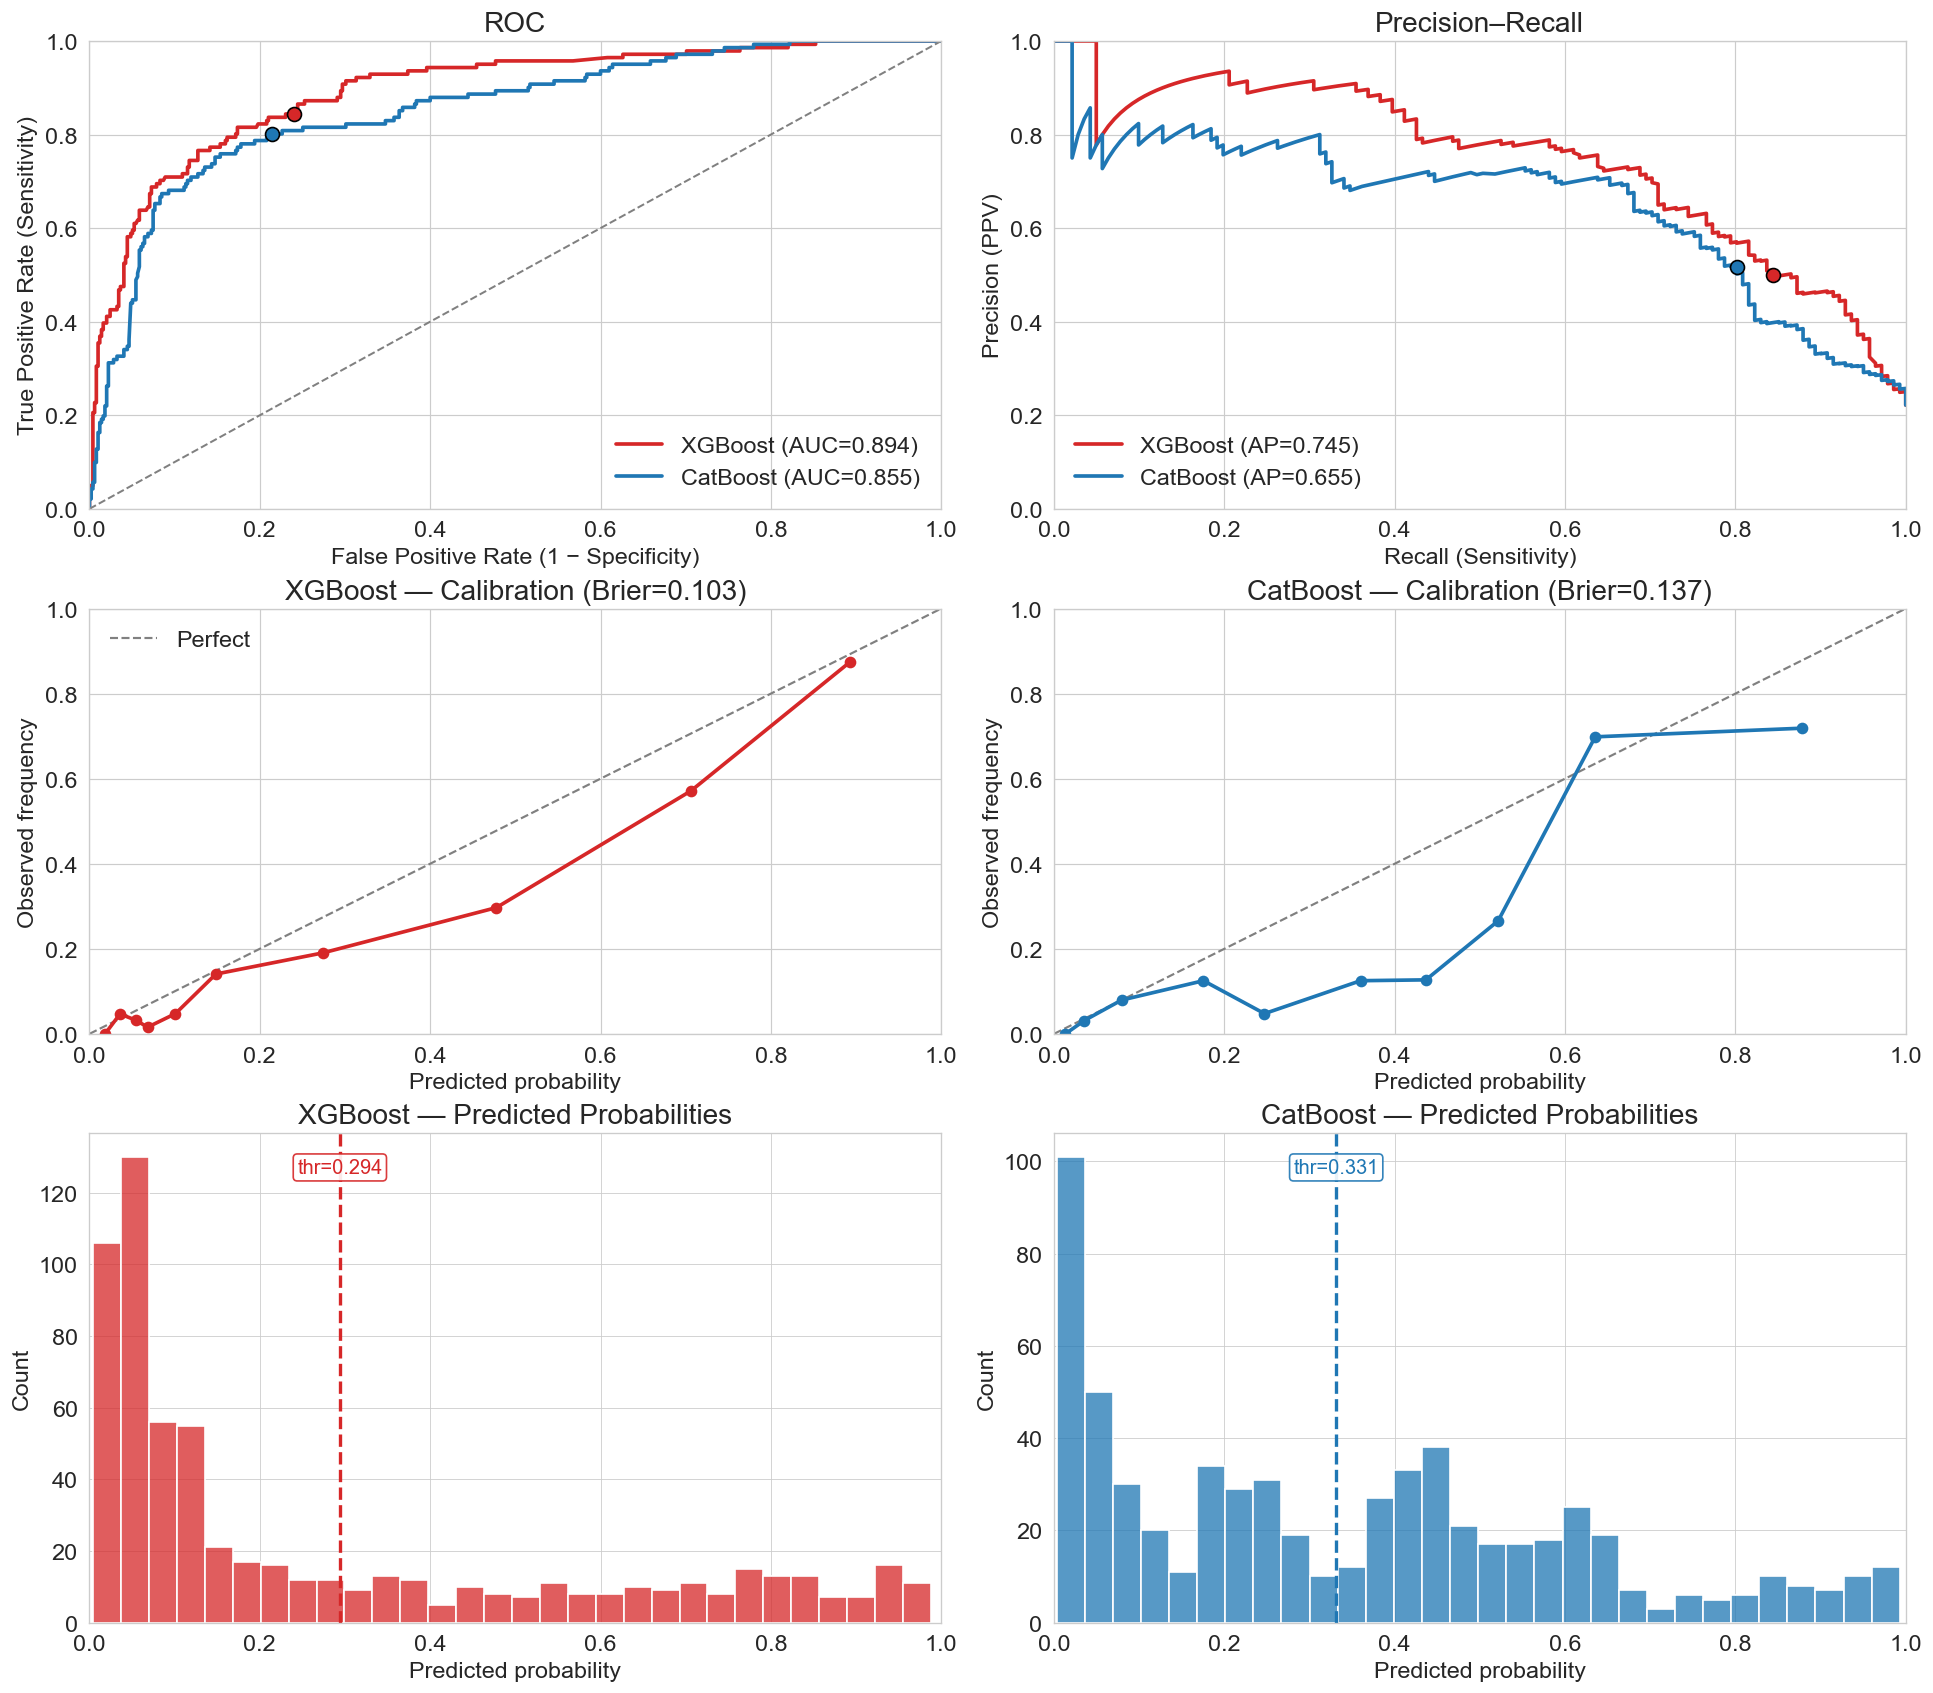

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_fig_ROC_PR_Calibration_Hists_XGB_left_CAT_right.png


In [8]:
# =============== FIGURE 2: ROC (AUC) | PR (AP) | Calibration | Prob Histograms ===============

mpl.rcParams.update({"font.size": 14})  # bump up all text globally

def calib_data(y_true, probs, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    probs  = as_proba(probs)
    n_bins = min(10, max(3, n_bins))
    prob_true, prob_pred = calibration_curve(y_true, probs, n_bins=n_bins, strategy="quantile")
    brier = brier_score_loss(y_true, probs)
    return prob_true, prob_pred, brier

def pooled_operating_point_pr(y_true, probs, fold_ids, fold_thresholds):
    thr_vec = np.array([fold_thresholds[int(f)] for f in fold_ids])
    preds = (as_proba(probs) >= thr_vec).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0,1]).ravel()
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    return precision, recall

def pooled_operating_point_roc(y_true, probs, fold_ids, fold_thresholds):
    thr_vec = np.array([fold_thresholds[int(f)] for f in fold_ids])
    preds = (as_proba(probs) >= thr_vec).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0,1]).ravel()
    tpr = tp / (tp + fn) if (tp + fn) else 0.0
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    return fpr, tpr

def ensure_oof_dict(name, d):
    need = {"y_true","probs","fold_ids","fold_thresholds"}
    assert isinstance(d, dict) and need.issubset(d.keys()), f"{name} missing keys {need}"
    d["y_true"]  = np.asarray(d["y_true"]).astype(int)
    d["probs"]   = as_proba(d["probs"])
    d["fold_ids"]= np.asarray(d["fold_ids"]).astype(int)
    return d

oof_cat = ensure_oof_dict("oof_cat", oof_cat)
oof_xgb = ensure_oof_dict("oof_xgb", oof_xgb)

# Put XGBoost first (left), CatBoost second (right)
model_order = ["XGBoost", "CatBoost"]
oofs   = {"XGBoost": oof_xgb, "CatBoost": oof_cat}
colors = {"XGBoost": "tab:red", "CatBoost": "tab:blue"}
mean_thresholds = {k: float(np.mean(list(v["fold_thresholds"].values()))) for k, v in oofs.items()}

# Precompute metrics
calib, ap_vals, auc_vals = {}, {}, {}
for name in model_order:
    y = oofs[name]["y_true"]; p = oofs[name]["probs"]
    calib[name] = calib_data(y, p, n_bins=10)
    ap_vals[name]  = average_precision_score(y, p)
    auc_vals[name] = roc_auc_score(y, p)

# ---------- Layout: 3 rows x 2 cols ----------
fig = plt.figure(figsize=(16, 14), constrained_layout=True)
gs = gridspec.GridSpec(3, 2, figure=fig, height_ratios=[1.1, 1.0, 1.15])

# ===== Top-left: ROC (AUC) =====
ax_roc = plt.subplot(gs[0, 0])
for name in model_order:
    y_true = oofs[name]["y_true"]; probs = oofs[name]["probs"]
    fpr, tpr, _ = roc_curve(y_true, probs)
    auc = auc_vals[name]
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", linewidth=2.2, color=colors[name])
    fpr_op, tpr_op = pooled_operating_point_roc(y_true, probs, oofs[name]["fold_ids"], oofs[name]["fold_thresholds"])
    ax_roc.scatter(fpr_op, tpr_op, color=colors[name], edgecolor="black", s=70, zorder=5)
ax_roc.plot([0,1],[0,1], linestyle="--", color="gray", linewidth=1.2)
ax_roc.set_xlabel("False Positive Rate (1 − Specificity)")
ax_roc.set_ylabel("True Positive Rate (Sensitivity)")
ax_roc.set_title("ROC")
ax_roc.set_xlim(0, 1); ax_roc.set_ylim(0, 1)
ax_roc.legend(frameon=False, loc="lower right"); ax_roc.grid(True, linewidth=0.7)

# ===== Top-right: PR (AP) =====
ax_pr = plt.subplot(gs[0, 1])
for name in model_order:
    y_true = oofs[name]["y_true"]; probs = oofs[name]["probs"]
    prec, rec, _ = precision_recall_curve(y_true, probs)
    ap = ap_vals[name]
    ax_pr.plot(rec, prec, label=f"{name} (AP={ap:.3f})", linewidth=2.2, color=colors[name])
    pr_op, rc_op = pooled_operating_point_pr(y_true, probs, oofs[name]["fold_ids"], oofs[name]["fold_thresholds"])
    ax_pr.scatter(rc_op, pr_op, color=colors[name], edgecolor="black", s=70, zorder=5)
ax_pr.set_xlabel("Recall (Sensitivity)"); ax_pr.set_ylabel("Precision (PPV)")
ax_pr.set_title("Precision–Recall")
ax_pr.set_xlim(0, 1); ax_pr.set_ylim(0, 1)
ax_pr.legend(frameon=False, loc="lower left"); ax_pr.grid(True, linewidth=0.7)

# ===== Middle row: Calibration curves =====
axes_cal = [plt.subplot(gs[1, 0]), plt.subplot(gs[1, 1])]
for ax, name in zip(axes_cal, model_order):
    pt, pp, brier = calib[name]
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1.3, label="Perfect")
    ax.plot(pp, pt, marker="o", markersize=6, linewidth=2.2, color=colors[name])
    ax.set_title(f"{name} — Calibration (Brier={brier:.3f})")
    ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, linewidth=0.7)
axes_cal[0].legend(frameon=False, loc="upper left")

# ===== Bottom row: Probability histograms =====
axes_hist = [plt.subplot(gs[2, 0]), plt.subplot(gs[2, 1])]
for ax, name in zip(axes_hist, model_order):
    p = oofs[name]["probs"]
    sns.histplot(p, bins=30, ax=ax, color=colors[name], kde=False)
    ax.set_title(f"{name} — Predicted Probabilities")
    ax.set_xlabel("Predicted probability"); ax.set_ylabel("Count")
    ax.set_xlim(0, 1); ax.grid(True, linewidth=0.5)
    thr = mean_thresholds[name]
    ax.axvline(thr, color=colors[name], linestyle="--", linewidth=2)
    ymin, ymax = ax.get_ylim()
    ax.text(thr, ymax - 0.05*(ymax - ymin), f"thr={thr:.3f}",
            color=colors[name], ha="center", va="top", fontsize=12,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=colors[name], alpha=0.9))

out_path = f"{IMG_DIR}/rev_fig_ROC_PR_Calibration_Hists_XGB_left_CAT_right.png"
os.makedirs(os.path.dirname(out_path), exist_ok=True)
plt.savefig(out_path, dpi=300, bbox_inches="tight"); plt.show()
print("Saved:", out_path)


In [9]:
# =============== 8) TABLE 2: METRICS (POOLED THR) ===============
def pooled_metrics(y, p, fids, thr_map):
    y = np.asarray(y).astype(int); p = as_proba(p); fids = np.asarray(fids).astype(int)
    thr_vec = np.array([thr_map[int(fi)] for fi in fids])
    preds = (p >= thr_vec).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, preds, labels=[0,1]).ravel()
    sens = tp/(tp+fn) if (tp+fn) else 0.0
    spec = tn/(tn+fp) if (tn+fp) else 0.0
    ppv  = tp/(tp+fp) if (tp+fp) else 0.0
    npv  = tn/(tn+fn) if (tn+fn) else 0.0
    return sens, spec, ppv, npv

def bootstrap_ci_pooled(y, p, fids, thr_map, B=2000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y); buckets = {k: [] for k in ["Sens","Spec","PPV","NPV","AUC","PRAUC","Brier"]}
    y = np.asarray(y).astype(int); p = as_proba(p); fids = np.asarray(fids).astype(int)
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        sens, spec, ppv, npv = pooled_metrics(y[idx], p[idx], fids[idx], thr_map)
        buckets["Sens"].append(sens); buckets["Spec"].append(spec)
        buckets["PPV"].append(ppv);   buckets["NPV"].append(npv)
        buckets["AUC"].append(roc_auc_score(y[idx], p[idx]))
        buckets["PRAUC"].append(average_precision_score(y[idx], p[idx]))
        buckets["Brier"].append(brier_score_loss(y[idx], p[idx]))
    out = {k: (np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in buckets.items()}
    return out

def row(mean, lo, hi, d=3): return f"{mean:.{d}f} ({lo:.{d}f}, {hi:.{d}f})"

models = {"CatBoost": oof_cat, "XGBoost": oof_xgb}
summary_fmt = {}
for name, pack in models.items():
    y, p, fids, thr_map = pack["y_true"], pack["probs"], pack["fold_ids"], pack["fold_thresholds"]
    sens, spec, ppv, npv = pooled_metrics(y, p, fids, thr_map)
    boot = bootstrap_ci_pooled(y, p, fids, thr_map, B=2000, seed=RANDOM_STATE)  # [REV-0.4] single seed (was 123)
    summary_fmt[name] = {
        "Sens":  row(sens, *boot["Sens"][1:3]),
        "Spec":  row(spec, *boot["Spec"][1:3]),
        "PPV":   row(ppv,  *boot["PPV"][1:3]),
        "NPV":   row(npv,  *boot["NPV"][1:3]),
        "AUC":   row(roc_auc_score(y,p), *boot["AUC"][1:3]),
        "PRAUC": row(average_precision_score(y,p), *boot["PRAUC"][1:3]),
        "Brier": row(brier_score_loss(y,p), *boot["Brier"][1:3]),
        # [REV-1.0] mean of the 5 per-fold thresholds (range)
        "Mean fold threshold": f"{np.mean(list(thr_map.values())):.3f} ({min(thr_map.values()):.3f}–{max(thr_map.values()):.3f})",
    }

summary_df = pd.DataFrame(summary_fmt)[["CatBoost","XGBoost"]]
print(f"\n=== OOF summary with 95% CIs — pooled, fold-wise thresholds at spec >= {TARGET_SPEC:.2f} ===")
print(summary_df)

out_csv = f"{CSV_DIR}/rev_fig2_summary_metrics_XGB_vs_CAT_bootstrap_pooled.csv"
summary_df.to_csv(out_csv); print("Saved:", out_csv)



=== OOF summary with 95% CIs — pooled, fold-wise thresholds at spec >= 0.70 ===
                                 CatBoost               XGBoost
Sens                 0.801 (0.734, 0.864)  0.844 (0.782, 0.900)
Spec                 0.786 (0.750, 0.820)  0.760 (0.720, 0.796)
PPV                  0.516 (0.449, 0.579)  0.500 (0.436, 0.562)
NPV                  0.933 (0.909, 0.955)  0.945 (0.921, 0.965)
AUC                  0.855 (0.817, 0.888)  0.894 (0.862, 0.922)
PRAUC                0.655 (0.571, 0.741)  0.745 (0.674, 0.815)
Brier                0.137 (0.123, 0.152)  0.103 (0.089, 0.119)
Mean fold threshold   0.331 (0.087–0.589)   0.294 (0.102–0.532)
Saved: /Users/hbattey/Desktop/Rodwell/Output/csv/rev_fig2_summary_metrics_XGB_vs_CAT_bootstrap_pooled.csv


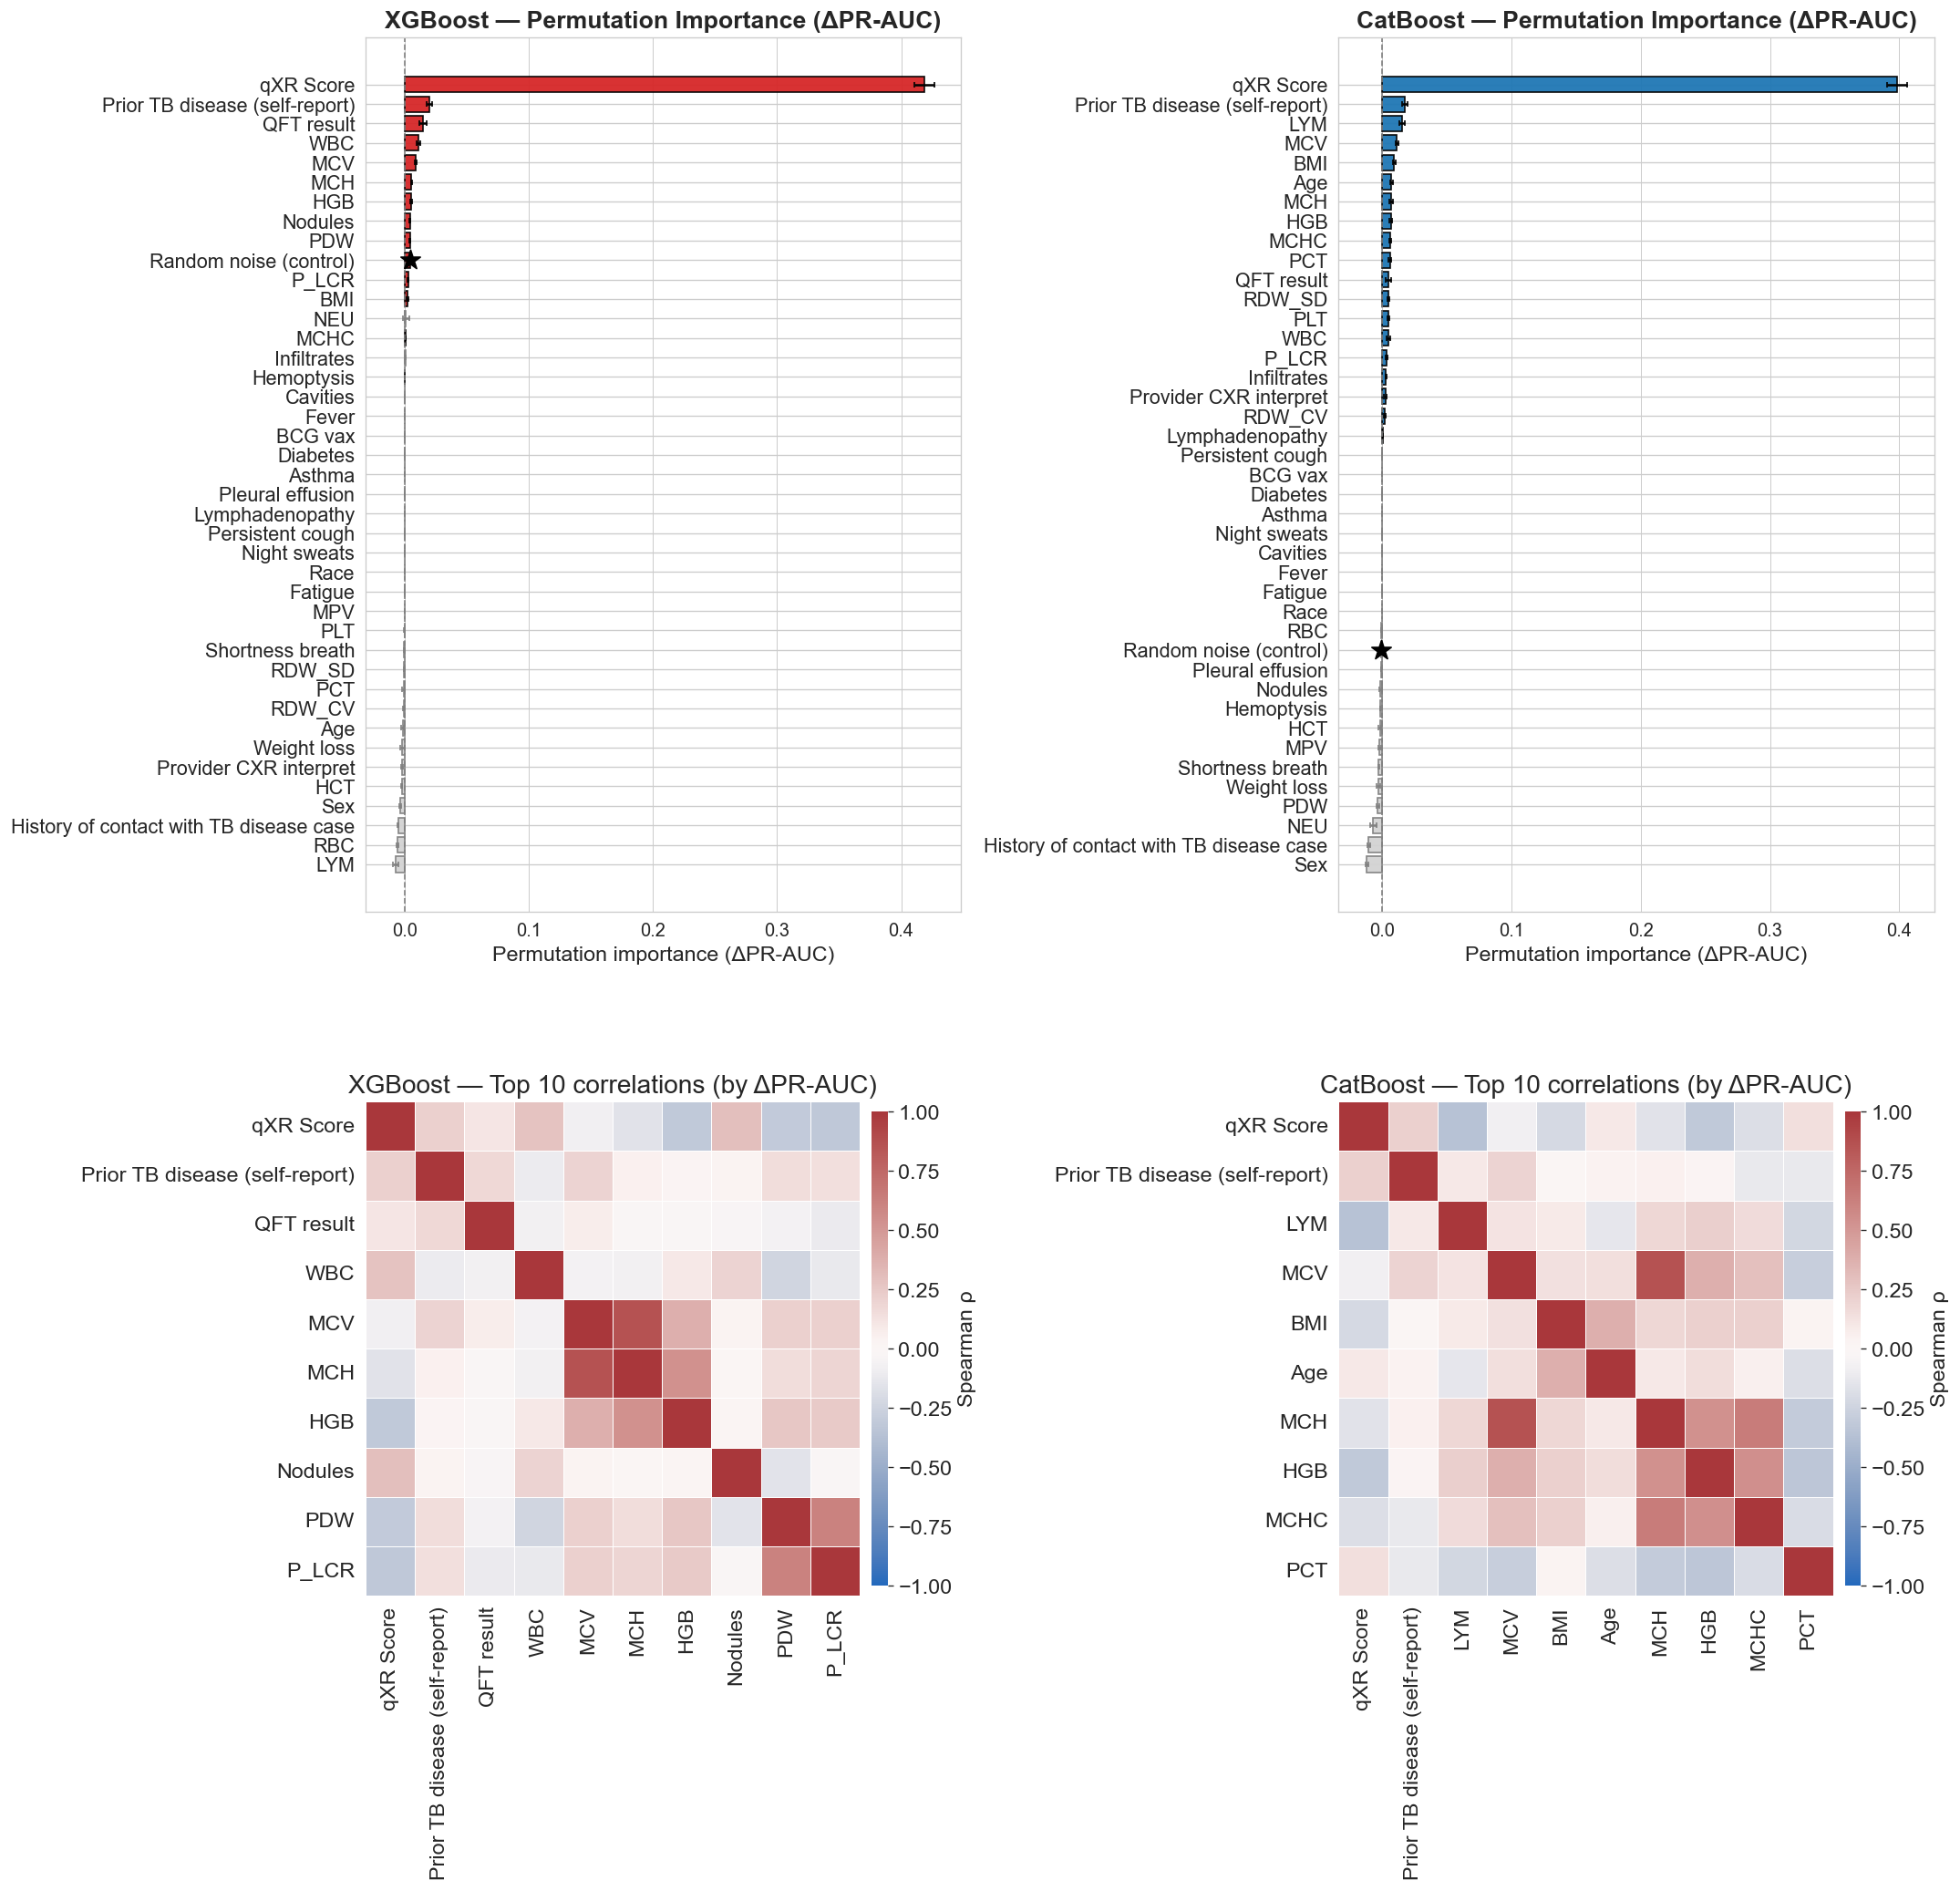

Saved figure (ΔPR-AUC): /Users/hbattey/Desktop/Rodwell/Output/Images/rev_perm_importance_PR-AUCprimary_with_corr_XGB_left_CAT_right.png


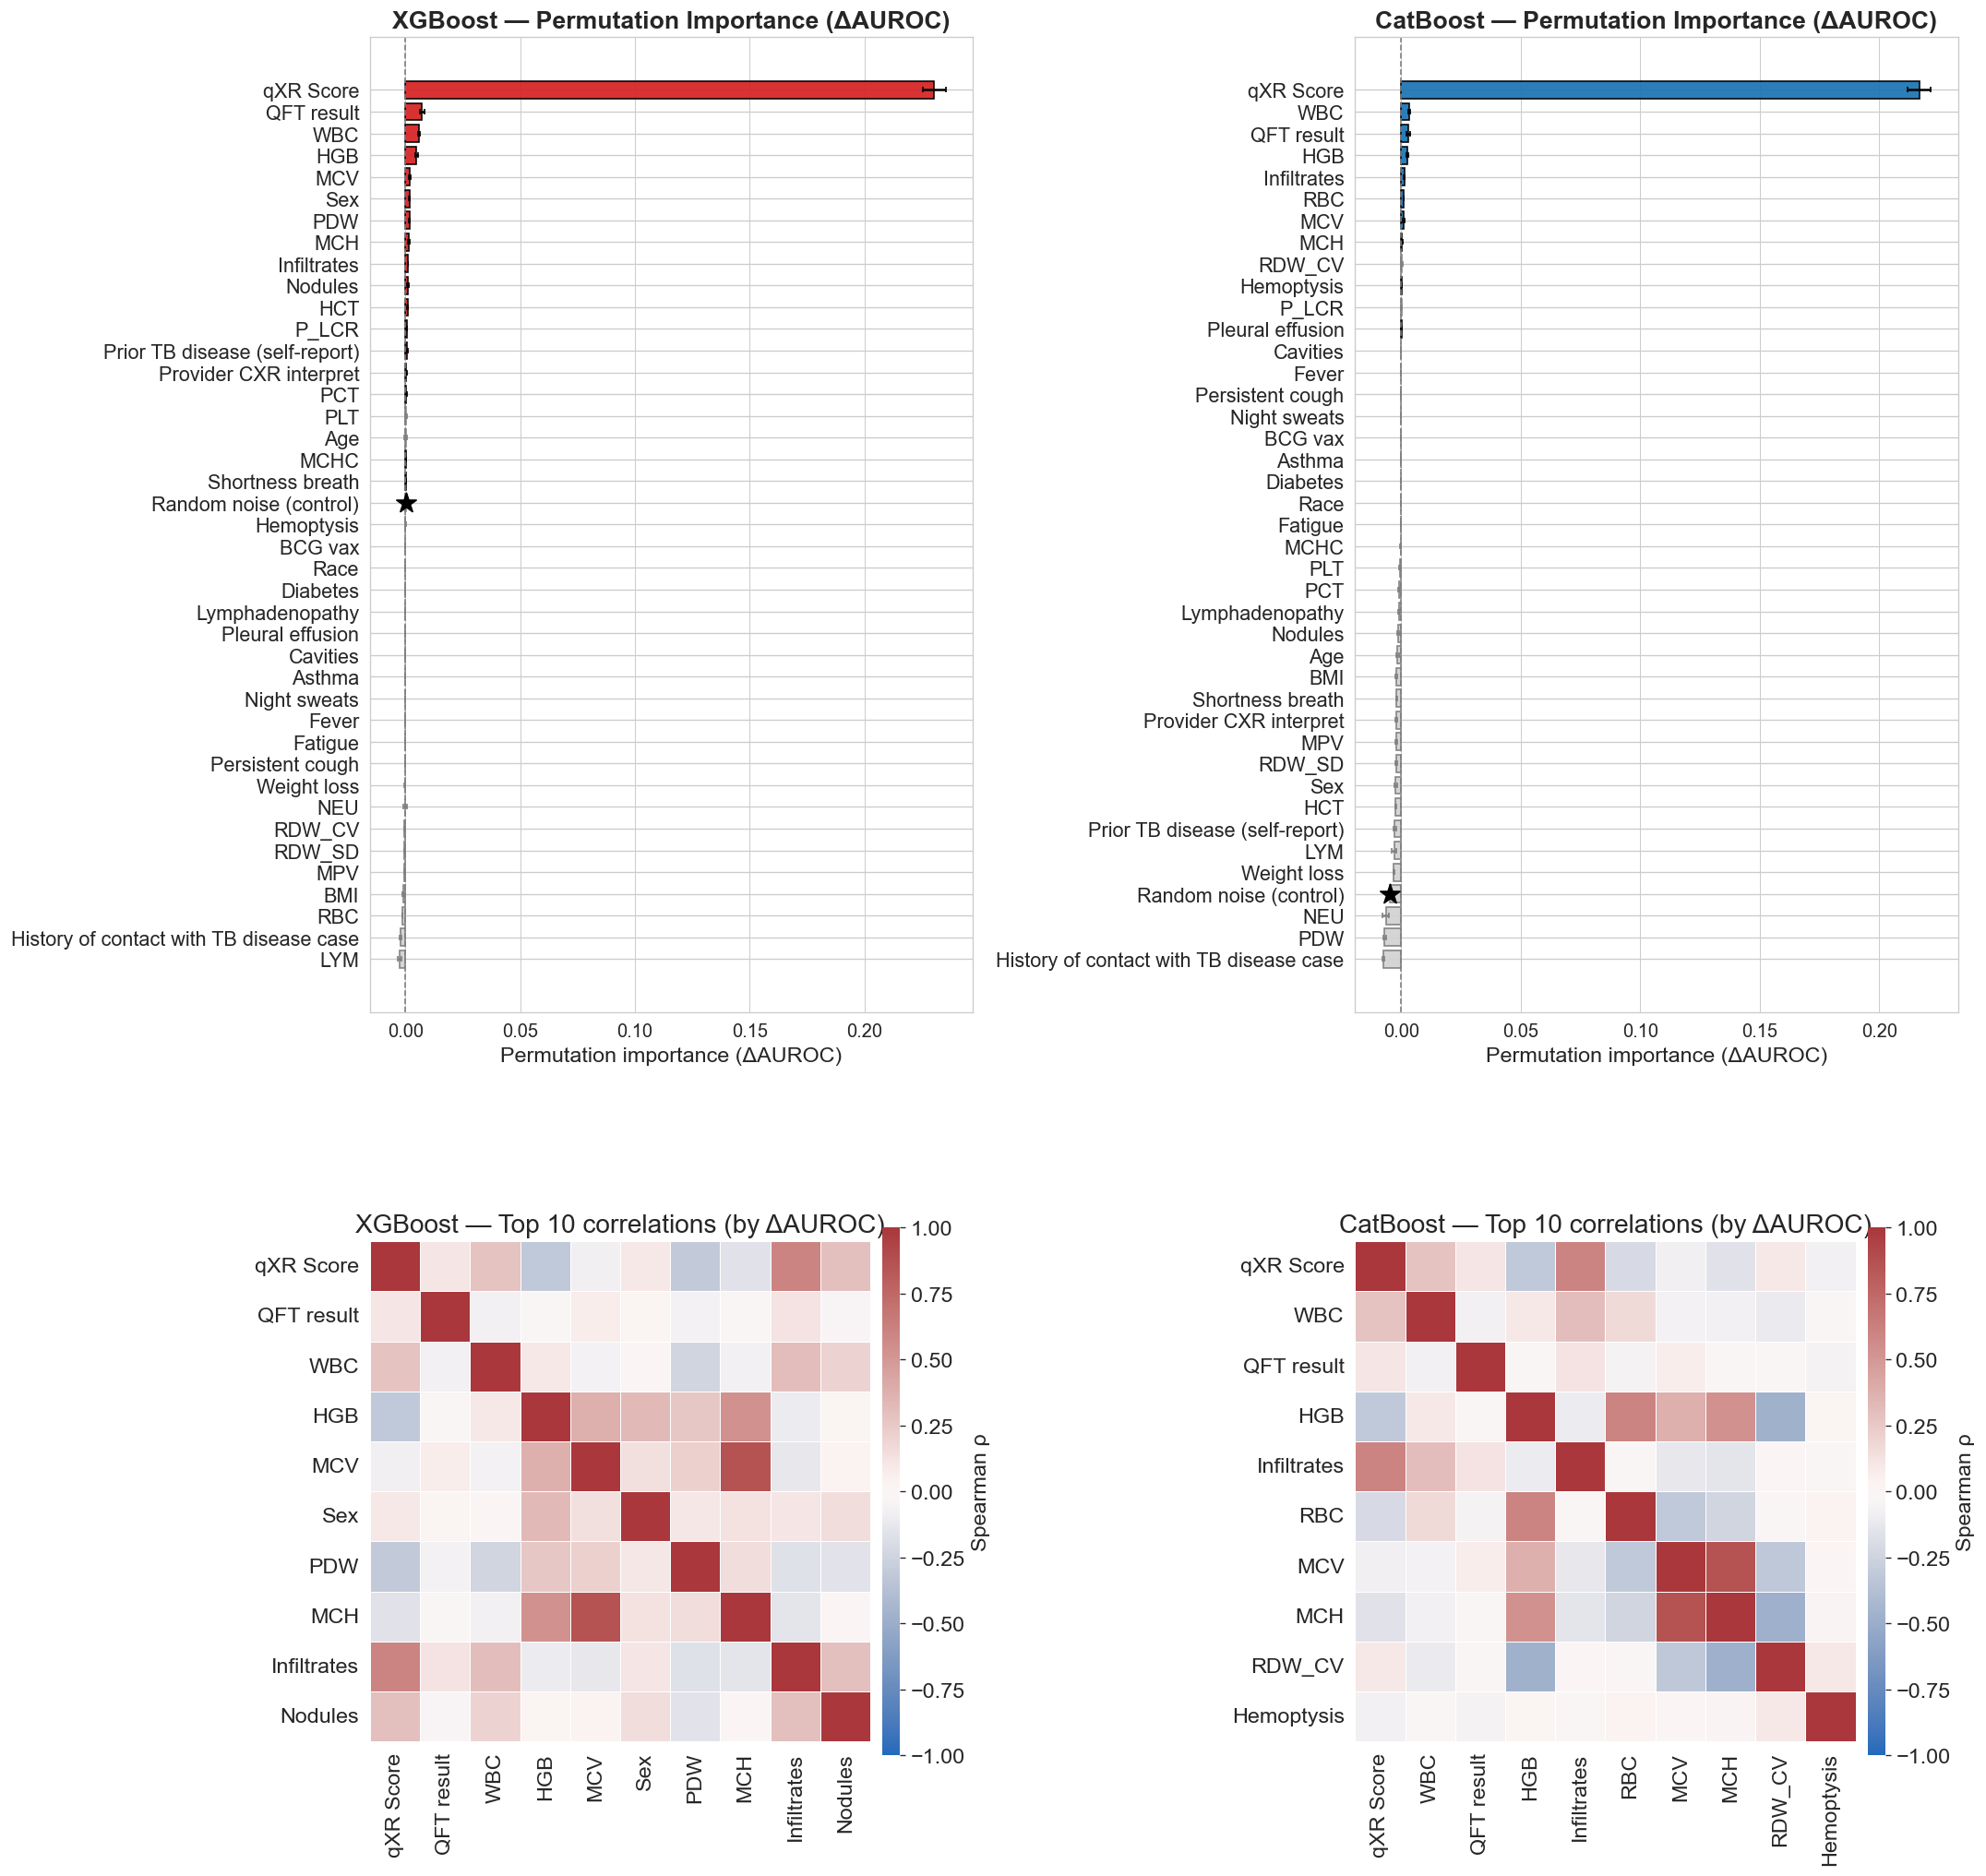

Saved figure (ΔAUROC): /Users/hbattey/Desktop/Rodwell/Output/Images/rev_perm_importance_AUROC_sensitivity_with_corr_XGB_left_CAT_right.png
XGBoost (ΔPR-AUC): rand_noise ranked 10/41 by ΔPR_AUC_mean
CatBoost (ΔPR-AUC): rand_noise ranked 30/41 by ΔPR_AUC_mean
XGBoost (ΔAUROC): rand_noise ranked 20/41 by ΔAUROC_mean
CatBoost (ΔAUROC): rand_noise ranked 38/41 by ΔAUROC_mean


In [10]:
# =============== FIG 3: Permutation Importance (PR-AUC primary; AUROC sensitivity) + CORR ===============

mpl.rcParams.update({"font.size": 14})

# -------- Build PI test frame (align + base) --------
X_test_base = align_categoricals(feature_test.copy())
y_test      = target_test.astype(int).copy()

# Ensure the single chosen random control exists in TEST matrices used for PI
if RAND_NAME not in X_test_base.columns:
    X_test_base[RAND_NAME] = np.random.default_rng(random_feature_seed).random(len(X_test_base))

# -------- Model-required columns & alignment --------
def required_cols_for_xgb(booster):
    req = getattr(booster, "feature_names_", None)
    if req is None:
        raise ValueError("XGB booster missing feature_names_; ensure set after training.")
    return list(req)

def required_cols_for_cat(model, fallback_cols):
    req = getattr(model, "feature_names_", None)
    return list(req) if (req is not None and len(req) > 0) else list(fallback_cols)

req_xgb = required_cols_for_xgb(est_xgb)
req_cat = required_cols_for_cat(est_cat, fallback_cols=X_train_pi.columns)

def align_to_model(df, required_cols, model_name):
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        # recreate any missing RAND_NAME (noise) or fill with 0/median for others
        df2 = df.copy()
        rng = np.random.default_rng(random_feature_seed)
        for c in missing:
            if c == RAND_NAME or str(c).lower().startswith(("rand","random")):
                df2[c] = rng.random(len(df2))
            else:
                vals = pd.to_numeric(X_train_pi[c], errors="coerce") if c in X_train_pi.columns else pd.Series([], dtype=float)
                fill = float(np.nanmedian(vals)) if len(vals) and vals.notna().any() else 0.0
                df2[c] = fill
        df = df2
        # re-check
        missing2 = [c for c in required_cols if c not in df.columns]
        if missing2:
            raise ValueError(f"[{model_name}] Missing columns even after fix: {missing2}")
    return df.reindex(columns=required_cols)

# Align to model-required columns
X_test_xgb = align_to_model(X_test_base, req_xgb, "XGBoost")
X_test_cat = align_to_model(X_test_base, req_cat, "CatBoost")

# Build PI matrices: include RAND_NAME even if not in required cols (starred in plots)
X_pi_xgb = X_test_xgb.copy()
X_pi_cat = X_test_cat.copy()
if RAND_NAME not in X_pi_xgb.columns:
    X_pi_xgb[RAND_NAME] = X_test_base[RAND_NAME].values
if RAND_NAME not in X_pi_cat.columns:
    X_pi_cat[RAND_NAME] = X_test_base[RAND_NAME].values

STAR_FEATURES = {RAND_NAME}

# -------- sklearn-compatible wrappers (must implement fit) --------
class XGBBoosterWrapper(BaseEstimator, ClassifierMixin):
    """Wrapper around a fitted xgboost.Booster to satisfy sklearn API."""
    def __init__(self, booster, feature_names):
        self.booster = booster
        self.feature_names = list(feature_names)
        self.classes_ = np.array([0, 1], dtype=int)
        self._estimator_type = "classifier"

    def fit(self, X, y=None):
        # no training; just mark as 'fitted' and record n_features_in_
        self.n_features_in_ = len(self.feature_names)
        return self

    def _prepare(self, X):
        X2 = align_categoricals(X).reindex(columns=self.feature_names)
        return DMatrix(X2, enable_categorical=True)

    def predict_proba(self, X):
        d = self._prepare(X)
        p = as_proba(self.booster.predict(d)).reshape(-1)
        return np.vstack([1 - p, p]).T

class CatBoostWrapper(BaseEstimator, ClassifierMixin):
    """Wrapper around a fitted CatBoost model to satisfy sklearn API."""
    def __init__(self, model, feature_names):
        self.model = model
        self.feature_names = list(feature_names)
        self.classes_ = np.array([0, 1], dtype=int)
        self._estimator_type = "classifier"

    def fit(self, X, y=None):
        # no training; just mark as 'fitted' and record n_features_in_
        self.n_features_in_ = len(self.feature_names)
        return self

    def predict_proba(self, X):
        X2 = align_categoricals(X).reindex(columns=self.feature_names)
        return self.model.predict_proba(X2)

# Instantiate + 'fit' wrappers (required by permutation_importance)
xgb_pi = XGBBoosterWrapper(est_xgb, req_xgb).fit(X_test_xgb, y_test)
cat_pi = CatBoostWrapper(est_cat, req_cat).fit(X_test_cat, y_test)

# -------- Stats utils --------
def _bh_fdr(p):
    p = np.asarray(p, float); n = p.size
    order = np.argsort(p); ranked = p[order]
    q = ranked * n / (np.arange(n) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q); out[order] = q
    return np.clip(out, 0, 1)

try:
    from statsmodels.stats.multitest import multipletests
except Exception:
    multipletests = None

def _summarize_importance(imp_obj):
    deltas = imp_obj.importances
    means  = deltas.mean(axis=1); sds = deltas.std(axis=1, ddof=1)
    n = deltas.shape[1]; se = sds / np.sqrt(max(n, 1))
    from scipy import stats as _stats
    tstat = np.divide(means, se, out=np.zeros_like(means), where=se > 0)
    pvals = _stats.t.sf(tstat, df=max(n - 1, 1))
    qvals = multipletests(pvals, method="fdr_bh")[1] if multipletests else _bh_fdr(pvals)
    ci_lo = means - 1.96 * se; ci_hi = means + 1.96 * se
    return means, sds, ci_lo, ci_hi, pvals, qvals

# N_PI_REPEATS is set once in cell 0 ([REV-cleanup]: duplicate removed)
Z = 1.96  # for error bars in plots

# -------- Permutation importance: PR-AUC primary, AUROC sensitivity --------
def run_perm_PR_AUROC(est, X, y, n_repeats=N_PI_REPEATS, random_state=RANDOM_STATE):
    imp_pr  = permutation_importance(est, X, y, n_repeats=n_repeats, scoring="average_precision",
                                     random_state=random_state, n_jobs=-1)
    pr_m, pr_sd, pr_lo, pr_hi, p_pr, q_pr = _summarize_importance(imp_pr)

    imp_auc = permutation_importance(est, X, y, n_repeats=n_repeats, scoring="roc_auc",
                                     random_state=random_state, n_jobs=-1)
    auc_m, auc_sd, auc_lo, auc_hi, p_auc, q_auc = _summarize_importance(imp_auc)

    out = pd.DataFrame({
        "Feature": X.columns,
        "ΔPR_AUC_mean": pr_m, "ΔPR_AUC_sd": pr_sd, "ΔPR_AUC_lo": pr_lo, "ΔPR_AUC_hi": pr_hi,
        "pval_PR_AUC":  p_pr, "qval_PR_AUC": q_pr, "sig_PR_AUC_q<0.05": (q_pr < 0.05),

        "ΔAUROC_mean":  auc_m, "ΔAUROC_sd": auc_sd, "ΔAUROC_lo": auc_lo, "ΔAUROC_hi": auc_hi,
        "pval_AUROC":   p_auc, "qval_AUROC":  q_auc, "sig_AUROC_q<0.05": (q_auc < 0.05),
    })
    out["Display"] = out["Feature"].map(lambda c: rename_dict.get(c, c))
    return out

pi_xgb = run_perm_PR_AUROC(xgb_pi, X_pi_xgb, y_test)
pi_cat = run_perm_PR_AUROC(cat_pi,  X_pi_cat, y_test)

# -------- Save CSVs --------
os.makedirs(CSV_DIR, exist_ok=True)
pi_xgb.sort_values("ΔPR_AUC_mean", ascending=False).to_csv(f"{CSV_DIR}/rev_perm_importance_XGB_PR-AUC_primary.csv", index=False)
pi_cat.sort_values("ΔPR_AUC_mean", ascending=False).to_csv(f"{CSV_DIR}/rev_perm_importance_CAT_PR-AUC_primary.csv", index=False)
pi_xgb.sort_values("ΔAUROC_mean",   ascending=False).to_csv(f"{CSV_DIR}/rev_perm_importance_XGB_AUROC_sensitivity.csv", index=False)
pi_cat.sort_values("ΔAUROC_mean",   ascending=False).to_csv(f"{CSV_DIR}/rev_perm_importance_CAT_AUROC_sensitivity.csv", index=False)

# -------- Plotting helpers (bars + correlations) --------
def to_numeric_matrix(df, cols):
    X = df[cols].copy(); out = pd.DataFrame(index=X.index)
    for c in cols:
        s = X[c]
        if isinstance(s.dtype, pd.CategoricalDtype) or s.dtype == object:
            out[c] = s.astype("category").cat.codes
        else:
            out[c] = pd.to_numeric(s, errors="coerce").fillna(0)
    return out

def corr_panel(ax, df_raw, top_feats, title):
    if len(top_feats) == 0:
        ax.set_visible(False); return
    Xnum = to_numeric_matrix(df_raw, top_feats)
    corr = Xnum.corr(method="spearman")
    pretty_cols = [rename_dict.get(c, c) for c in top_feats]
    corr.index = pretty_cols; corr.columns = pretty_cols
    sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="vlag", square=True,
                linewidths=0.3, linecolor="white",
                cbar_kws={"label":"Spearman ρ","shrink":0.65,"aspect":30,"pad":0.02},
                ax=ax)
    ax.set_title(title); ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

def bar_panel(ax, df_imp, order, labels, title,
              metric_col="ΔPR_AUC_mean", sd_col="ΔPR_AUC_sd", sig_col="sig_PR_AUC_q<0.05",
              color_sig="tab:red", color_ns="lightgray",
              n_repeats=N_PI_REPEATS, z=Z, xlabel="Permutation importance (ΔPR-AUC)"):
    sub = df_imp.set_index("Feature").loc[order].iloc[::-1].copy()
    y_pos = np.arange(len(sub))
    vals  = sub[metric_col].to_numpy()
    errs  = (z * sub[sd_col].to_numpy() / np.sqrt(n_repeats))
    sig   = sub[sig_col].to_numpy().astype(bool)

    if (~sig).any():
        ax.barh(y_pos[~sig], vals[~sig], xerr=errs[~sig],
                color=color_ns, edgecolor="gray", ecolor="gray", capsize=2, alpha=0.95)
    if sig.any():
        ax.barh(y_pos[sig], vals[sig], xerr=errs[sig],
                color=color_sig, edgecolor="black", ecolor="black", capsize=2, alpha=0.95)

    # star the random control if present
    if RAND_NAME in sub.index:
        idx = sub.index.get_loc(RAND_NAME)
        ax.scatter(vals[idx], y_pos[idx], marker="*", s=180, color="black", zorder=5)

    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_yticks(y_pos); ax.set_yticklabels(list(reversed(labels)), fontsize=13)
    ax.tick_params(axis="x", labelsize=12); ax.grid(True, axis="x", linewidth=0.6)

# -------- FIGURE A: ΔPR-AUC (primary) + correlations --------
order_xgb_pr = pi_xgb.sort_values("ΔPR_AUC_mean", ascending=False)["Feature"].tolist()
order_cat_pr = pi_cat.sort_values("ΔPR_AUC_mean", ascending=False)["Feature"].tolist()
labels_xgb   = [rename_dict.get(f, f) for f in order_xgb_pr]
labels_cat   = [rename_dict.get(f, f) for f in order_cat_pr]
TOP_K = min(10, len(order_xgb_pr), len(order_cat_pr))

fig_pr, axes_pr = plt.subplots(2, 2, figsize=(18, max(8, 0.30*max(len(order_xgb_pr), len(order_cat_pr)) + 6)),
                               gridspec_kw={"height_ratios": [1.2, 1.0]})

bar_panel(axes_pr[0, 0], pi_xgb, order_xgb_pr, labels_xgb,
          "XGBoost — Permutation Importance (ΔPR-AUC)",
          color_sig="tab:red", xlabel="Permutation importance (ΔPR-AUC)")
bar_panel(axes_pr[0, 1], pi_cat, order_cat_pr, labels_cat,
          "CatBoost — Permutation Importance (ΔPR-AUC)",
          color_sig="tab:blue", xlabel="Permutation importance (ΔPR-AUC)")

top_xgb_pr_corr = [f for f in order_xgb_pr if f != RAND_NAME][:TOP_K]
top_cat_pr_corr = [f for f in order_cat_pr if f != RAND_NAME][:TOP_K]
corr_panel(axes_pr[1, 0], X_test_base, top_xgb_pr_corr,
           f"XGBoost — Top {len(top_xgb_pr_corr)} correlations (by ΔPR-AUC)")
corr_panel(axes_pr[1, 1], X_test_base, top_cat_pr_corr,
           f"CatBoost — Top {len(top_cat_pr_corr)} correlations (by ΔPR-AUC)")

os.makedirs(IMG_DIR, exist_ok=True)
fig_path_pr = f"{IMG_DIR}/rev_perm_importance_PR-AUCprimary_with_corr_XGB_left_CAT_right.png"
plt.tight_layout(); plt.savefig(fig_path_pr, dpi=260, bbox_inches="tight"); plt.show()
print("Saved figure (ΔPR-AUC):", fig_path_pr)

# -------- FIGURE B: ΔAUROC (sensitivity) + correlations --------
order_xgb_auc = pi_xgb.sort_values("ΔAUROC_mean", ascending=False)["Feature"].tolist()
order_cat_auc = pi_cat.sort_values("ΔAUROC_mean", ascending=False)["Feature"].tolist()
labels_xgb_auc = [rename_dict.get(f, f) for f in order_xgb_auc]
labels_cat_auc = [rename_dict.get(f, f) for f in order_cat_auc]
TOP_K_AUC = min(10, len(order_xgb_auc), len(order_cat_auc))

fig_auc, axes_auc = plt.subplots(2, 2, figsize=(18, max(8, 0.30*max(len(order_xgb_auc), len(order_cat_auc)) + 6)),
                                 gridspec_kw={"height_ratios": [1.2, 1.0]})

bar_panel(axes_auc[0, 0], pi_xgb, order_xgb_auc, labels_xgb_auc,
          "XGBoost — Permutation Importance (ΔAUROC)",
          metric_col="ΔAUROC_mean", sd_col="ΔAUROC_sd", sig_col="sig_AUROC_q<0.05",
          color_sig="tab:red", xlabel="Permutation importance (ΔAUROC)")
bar_panel(axes_auc[0, 1], pi_cat, order_cat_auc, labels_cat_auc,
          "CatBoost — Permutation Importance (ΔAUROC)",
          metric_col="ΔAUROC_mean", sd_col="ΔAUROC_sd", sig_col="sig_AUROC_q<0.05",
          color_sig="tab:blue", xlabel="Permutation importance (ΔAUROC)")

top_xgb_auc_corr = [f for f in order_xgb_auc if f != RAND_NAME][:TOP_K_AUC]
top_cat_auc_corr = [f for f in order_cat_auc if f != RAND_NAME][:TOP_K_AUC]
corr_panel(axes_auc[1, 0], X_test_base, top_xgb_auc_corr,
           f"XGBoost — Top {len(top_xgb_auc_corr)} correlations (by ΔAUROC)")
corr_panel(axes_auc[1, 1], X_test_base, top_cat_auc_corr,
           f"CatBoost — Top {len(top_cat_auc_corr)} correlations (by ΔAUROC)")

fig_path_auc = f"{IMG_DIR}/rev_perm_importance_AUROC_sensitivity_with_corr_XGB_left_CAT_right.png"
plt.tight_layout(); plt.savefig(fig_path_auc, dpi=260, bbox_inches="tight"); plt.show()
print("Saved figure (ΔAUROC):", fig_path_auc)

def print_random_rank(pi_df, model_name, metric_col, random_name=RAND_NAME):
    if metric_col not in pi_df.columns:
        print(f"{model_name}: metric '{metric_col}' not found."); return
    df = pi_df[["Feature", metric_col]].sort_values(metric_col, ascending=False).reset_index(drop=True)
    total = len(df)
    idxs = np.flatnonzero(df["Feature"].to_numpy() == random_name)
    if idxs.size == 0:
        print(f"{model_name}: '{random_name}' not in feature list."); return
    rank = int(idxs[0]) + 1
    print(f"{model_name}: {random_name} ranked {rank}/{total} by {metric_col}")

print_random_rank(pi_xgb, "XGBoost (ΔPR-AUC)", "ΔPR_AUC_mean")
print_random_rank(pi_cat, "CatBoost (ΔPR-AUC)", "ΔPR_AUC_mean")
print_random_rank(pi_xgb, "XGBoost (ΔAUROC)",  "ΔAUROC_mean")
print_random_rank(pi_cat, "CatBoost (ΔAUROC)", "ΔAUROC_mean")


In [11]:
# =============== 10) FAIRNESS TABLE (SEARCH SPACES & BESTS) ===============

XGB_HIDE_KEYS = {"max_cat_to_onehot", "max_cat_threshold", "enable_categorical"}  # impl details, not tuned

# Best params snapshots prepared earlier
xgb_disp = {k: v for k, v in xgb_best_params.items() if k not in XGB_HIDE_KEYS}
cat_disp = dict(cat_best_params)

SEED_VAL = int(split_seed)

def _rng_str(a, b): return f"[{a}, {b}]"
def fmt(v):
    if v is None: return "—"
    if isinstance(v, float): return f"{v:.6g}"
    return str(v)

rows = []
def add_row(concept, purpose, xgb_space, cat_space, xgb_best_val, cat_best_val):
    rows.append({
        "Concept / Parameter": concept,
        "Purpose / Notes": purpose,
        "XGBoost — Search space / Fixed": xgb_space,
        "XGBoost — Best": xgb_best_val,
        "CatBoost — Search space / Fixed": cat_space,
        "CatBoost — Best": cat_best_val,
    })

add_row("Learning rate","Step size shrinkage.",
        _rng_str(0.05,0.10), _rng_str(0.05,0.10),
        fmt(xgb_disp.get("learning_rate")), fmt(cat_disp.get("learning_rate")))

add_row("Tree depth (capacity)","Model capacity.",
        _rng_str(3,7)+" (max_depth)", _rng_str(3,7)+" (depth)",
        fmt(xgb_disp.get("max_depth")), fmt(cat_disp.get("depth")))

add_row("L2 regularization","Overfit control.",
        _rng_str(1.0,10.0)+" (lambda)", _rng_str(1.0,10.0)+" (l2_leaf_reg)",
        fmt(xgb_disp.get("lambda")), fmt(cat_disp.get("l2_leaf_reg")))

add_row("L1 regularization","Sparsity (XGB only).",
        _rng_str(0.0,10.0)+" (alpha)", "—",
        fmt(xgb_disp.get("alpha")), "—")

add_row("Column sampling","Per-tree feature sampling.",
        _rng_str(0.70,0.95)+" (colsample_bytree)", _rng_str(0.70,0.95)+" (rsm)",
        fmt(xgb_disp.get("colsample_bytree")), fmt(cat_disp.get("rsm")))

add_row("Row sampling (Bernoulli)","Stochastic per-row.",
        _rng_str(0.70,0.95)+" (subsample)", "If Bernoulli → "+_rng_str(0.70,0.95),
        fmt(xgb_disp.get("subsample")),
        fmt(cat_disp.get("subsample")) if cat_disp.get("bootstrap_type")=="Bernoulli" else "—")

add_row("Bagging temperature (Bayesian)","Bayesian bootstrap randomness.",
        "—", "If Bayesian → "+_rng_str(0.0,1.0),
        "—",
        fmt(cat_disp.get("bagging_temperature")) if cat_disp.get("bootstrap_type")=="Bayesian" else "—")

add_row("Bootstrap family","CatBoost bagging scheme.",
        "—", "{Bayesian, Bernoulli}",
        "—", fmt(cat_disp.get("bootstrap_type")))

add_row("Min child / leaf weight","Leaf stability.",
        _rng_str(1,10)+" (min_child_weight)", _rng_str(1,32)+" (min_data_in_leaf)",
        fmt(xgb_disp.get("min_child_weight")), fmt(cat_disp.get("min_data_in_leaf")))

# **FIXED**: was the literal string "_rng_str(0,5) (gamma)"
add_row("Min split loss (γ)","Penalty to create a new split.",
        _rng_str(0.0,5.0)+" (gamma)", "—",
        fmt(xgb_disp.get("gamma")), "—")

# ---- Class imbalance summary (from studies) ----
def _best_trial_params(study):
    try:
        return dict(study.best_trial.params)
    except Exception:
        return {}

xgb_trial = _best_trial_params(study_xgb)
cat_trial = _best_trial_params(study_cat)

xgb_use_w  = xgb_trial.get("use_weights", None)
xgb_w_mult = xgb_trial.get("w_mult", None)
xgb_spw    = xgb_best_params.get("scale_pos_weight", None)

cat_use_w  = cat_trial.get("use_weights", None)
cat_w_mult = cat_trial.get("w_mult", None)

xgb_search = f"use_weights∈{{T,F}}; w_mult∈[0.5,2.0]; scale_pos_weight = 1 if off else w_mult×SCALE_POS({SCALE_POS:.3g})"
cat_search = "use_weights∈{T,F}; w_mult∈[0.5,2.0]"

if xgb_use_w is True:
    xgb_best_str = f"use_weights=True; w_mult={fmt(xgb_w_mult)}; scale_pos_weight={fmt(xgb_spw)}"
elif xgb_use_w is False:
    xgb_best_str = f"use_weights=False; scale_pos_weight={fmt(xgb_spw)}"
else:
    xgb_best_str = f"scale_pos_weight={fmt(xgb_spw)}"

if "class_weights" in cat_disp:
    cat_best_str = f"use_weights={cat_use_w if cat_use_w is not None else True}; w_mult={fmt(cat_w_mult)}; class_weights={cat_disp['class_weights']}"
elif "auto_class_weights" in cat_disp:
    cat_best_str = f"auto_class_weights={cat_disp['auto_class_weights']}"
else:
    cat_best_str = "use_weights=False (not used)" if cat_use_w is False else "use_weights=True; class_weights set"

add_row("Class imbalance weighting","Optional weighting around class ratio.",
        xgb_search, cat_search, xgb_best_str, cat_best_str)

add_row("Objective / Loss","Binary loss.",
        "binary:logistic", "Logloss",
        "binary:logistic", "Logloss")

add_row("Eval metric","Guides early stopping.",
        "auc", "AUC",
        "auc", "AUC")

add_row("Training length control","Upper cap & early stopping patience.",
        "≤2000; patience=80", "≤2000; patience=80",
        f"best_rounds={xgb_best_rounds}", f"best_rounds={cat_best_rounds}")

add_row("Categorical handling","Native categorical support.",
        "enable_categorical=True (fixed)", "Native CatBoost (fixed)",
        "Enabled", "Enabled")

add_row("Tree method / Seed","Determinism / backend.",
        f"tree_method=hist; seed={SEED_VAL}", f"random_seed={SEED_VAL}",
        f"hist; seed={SEED_VAL}", f"{SEED_VAL}")

fair_df = pd.DataFrame(rows)
fair_df.to_csv(f"{CSV_DIR}/rev_tuning_fairness_table.csv", index=False)
try:
    import openpyxl
    fair_df.to_excel(f"{CSV_DIR}/rev_tuning_fairness_table.xlsx",
                     sheet_name="fairness_table", index=False)
except Exception:
    print("Excel save skipped; install openpyxl if needed.")

print("Saved fairness table to CSV (and XLSX if available).")


Saved fairness table to CSV (and XLSX if available).



=== Nested CV at target specificity 0.70 ===



=== Nested CV at target specificity 0.75 ===



=== Nested CV at target specificity 0.80 ===



=== Nested CV at target specificity 0.85 ===



=== Nested CV at target specificity 0.90 ===


   Specificity_Target     Model  Sensitivity  Sensitivity_CI  \
0                0.70  CatBoost     0.801418  (0.734, 0.864)   
1                0.70   XGBoost     0.843972  (0.782, 0.900)   
2                0.75  CatBoost     0.836879  (0.776, 0.893)   
3                0.75   XGBoost     0.815603  (0.750, 0.874)   
4                0.80  CatBoost     0.815603  (0.752, 0.875)   
5                0.80   XGBoost     0.780142  (0.711, 0.844)   
6                0.85  CatBoost     0.744681  (0.674, 0.812)   
7                0.85   XGBoost     0.758865  (0.688, 0.823)   
8                0.90  CatBoost     0.659574  (0.583, 0.734)   
9                0.90   XGBoost     0.716312  (0.643, 0.790)   

   Achieved_Specificity       PPV       NPV     AUROC     PRAUC     Brier  
0              0.785859  0.515982  0.932854  0.854703  0.654892  0.136873  
1              0.759596  0.500000  0.944724  0.894419  0.745303  0.103295  
2              0.789899  0.531532  0.944444  0.871832  0.709830  0.

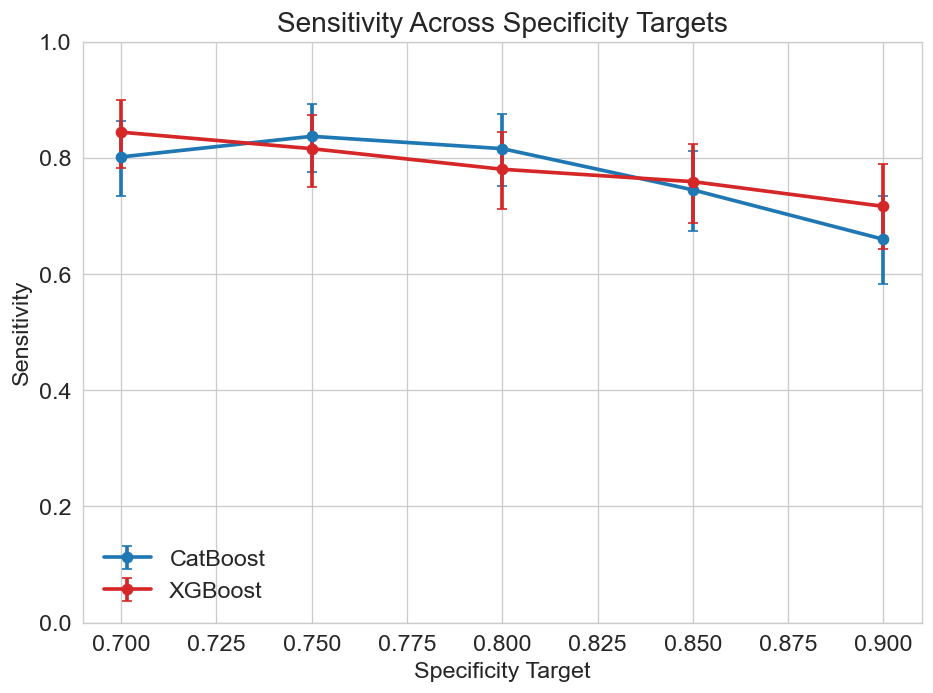

Saved figure: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_sensitivity_vs_spec_targets_cat_xgb.png


In [12]:
# =============== 11) SUPP FIG 3: SENS VS SPEC TARGETS ===============
SPEC_TARGETS = [0.70, 0.75, 0.80, 0.85, 0.90]  # [REV-1.0] 0.70 added
records = []

for spec_t in SPEC_TARGETS:
    print(f"\n=== Nested CV at target specificity {spec_t:.2f} ===")
    if spec_t == TARGET_SPEC:  # [REV-cleanup] identical to the cell-6 run (same data/seed): reuse, don't refit
        oof_cat_s, oof_xgb_s = oof_cat, oof_xgb
    else:
        oof_cat_s = build_oof_catboost_at_spec(X_for_oof, y_for_oof, CATS, spec_t, n_outer=N_OUTER, seed=RANDOM_STATE)
        oof_xgb_s = build_oof_xgb_at_spec(X_for_oof, y_for_oof, CATS, spec_t, n_outer=N_OUTER, seed=RANDOM_STATE)

    for name, pack in [("CatBoost", oof_cat_s), ("XGBoost", oof_xgb_s)]:
        y_true, probs, fids, thr_map = pack["y_true"], pack["probs"], pack["fold_ids"], pack["fold_thresholds"]
        # pooled metrics
        tn, fp, fn, tp = confusion_matrix(y_true, (probs >= np.array([thr_map[int(f)] for f in fids])).astype(int), labels=[0,1]).ravel()
        sens = tp/(tp+fn) if (tp+fn) else 0.0
        spec = (1 - fp/(fp+tn)) if (fp+tn) else 0.0
        ppv  = tp/(tp+fp) if (tp+fp) else 0.0
        npv  = tn/(tn+fn) if (tn+fn) else 0.0

        # simple bootstrap CI for sensitivity
        rng = np.random.default_rng(RANDOM_STATE)
        N = len(y_true)
        boots = []
        for _ in range(2000):
            idx = rng.integers(0, N, size=N)
            yb, pb, fb = y_true[idx], probs[idx], fids[idx]
            thrb = np.array([thr_map[int(f)] for f in fb])
            tn_b, fp_b, fn_b, tp_b = confusion_matrix(yb, (pb>=thrb).astype(int), labels=[0,1]).ravel()
            boots.append(tp_b/(tp_b+fn_b) if (tp_b+fn_b) else 0.0)
        lo, hi = np.percentile(boots, [2.5, 97.5])

        records.append(dict(
            Specificity_Target=spec_t, Model=name, Sensitivity=sens,
            Sensitivity_CI=f"({lo:.3f}, {hi:.3f})",
            Achieved_Specificity=spec, PPV=ppv, NPV=npv,
            AUROC=roc_auc_score(y_true, probs),
            PRAUC=average_precision_score(y_true, probs),
            Brier=brier_score_loss(y_true, probs)
        ))

results_df = pd.DataFrame(records).sort_values(["Specificity_Target","Model"]).reset_index(drop=True)
print(results_df[["Specificity_Target","Model","Sensitivity","Sensitivity_CI","Achieved_Specificity","PPV","NPV","AUROC","PRAUC","Brier"]])

out_csv = f"{CSV_DIR}/rev_sensitivity_vs_spec_targets_cat_xgb.csv"
results_df.to_csv(out_csv, index=False); print("Saved table:", out_csv)

# Plot
plt.figure(figsize=(8,6))
for name, color in [("CatBoost","tab:blue"), ("XGBoost","tab:red")]:
    sub = results_df[results_df["Model"] == name].sort_values("Specificity_Target")
    sens = sub["Sensitivity"].values
    lohi = np.array([tuple(map(float, s.strip("()").split(","))) for s in sub["Sensitivity_CI"].values])
    yerr = np.vstack([sens - lohi[:,0], lohi[:,1] - sens])
    plt.errorbar(sub["Specificity_Target"].values, sens, yerr=yerr, fmt="-o", capsize=3, linewidth=2.2, label=name, color=color)
plt.xlabel("Specificity Target"); plt.ylabel("Sensitivity"); plt.title("Sensitivity Across Specificity Targets")
plt.ylim(0, 1); plt.grid(True, linewidth=0.8); plt.legend(frameon=False, loc="lower left")
out_img = f"{IMG_DIR}/rev_sensitivity_vs_spec_targets_cat_xgb.png"
plt.tight_layout(); plt.savefig(out_img, dpi=220, bbox_inches="tight"); plt.show()
print("Saved figure:", out_img)


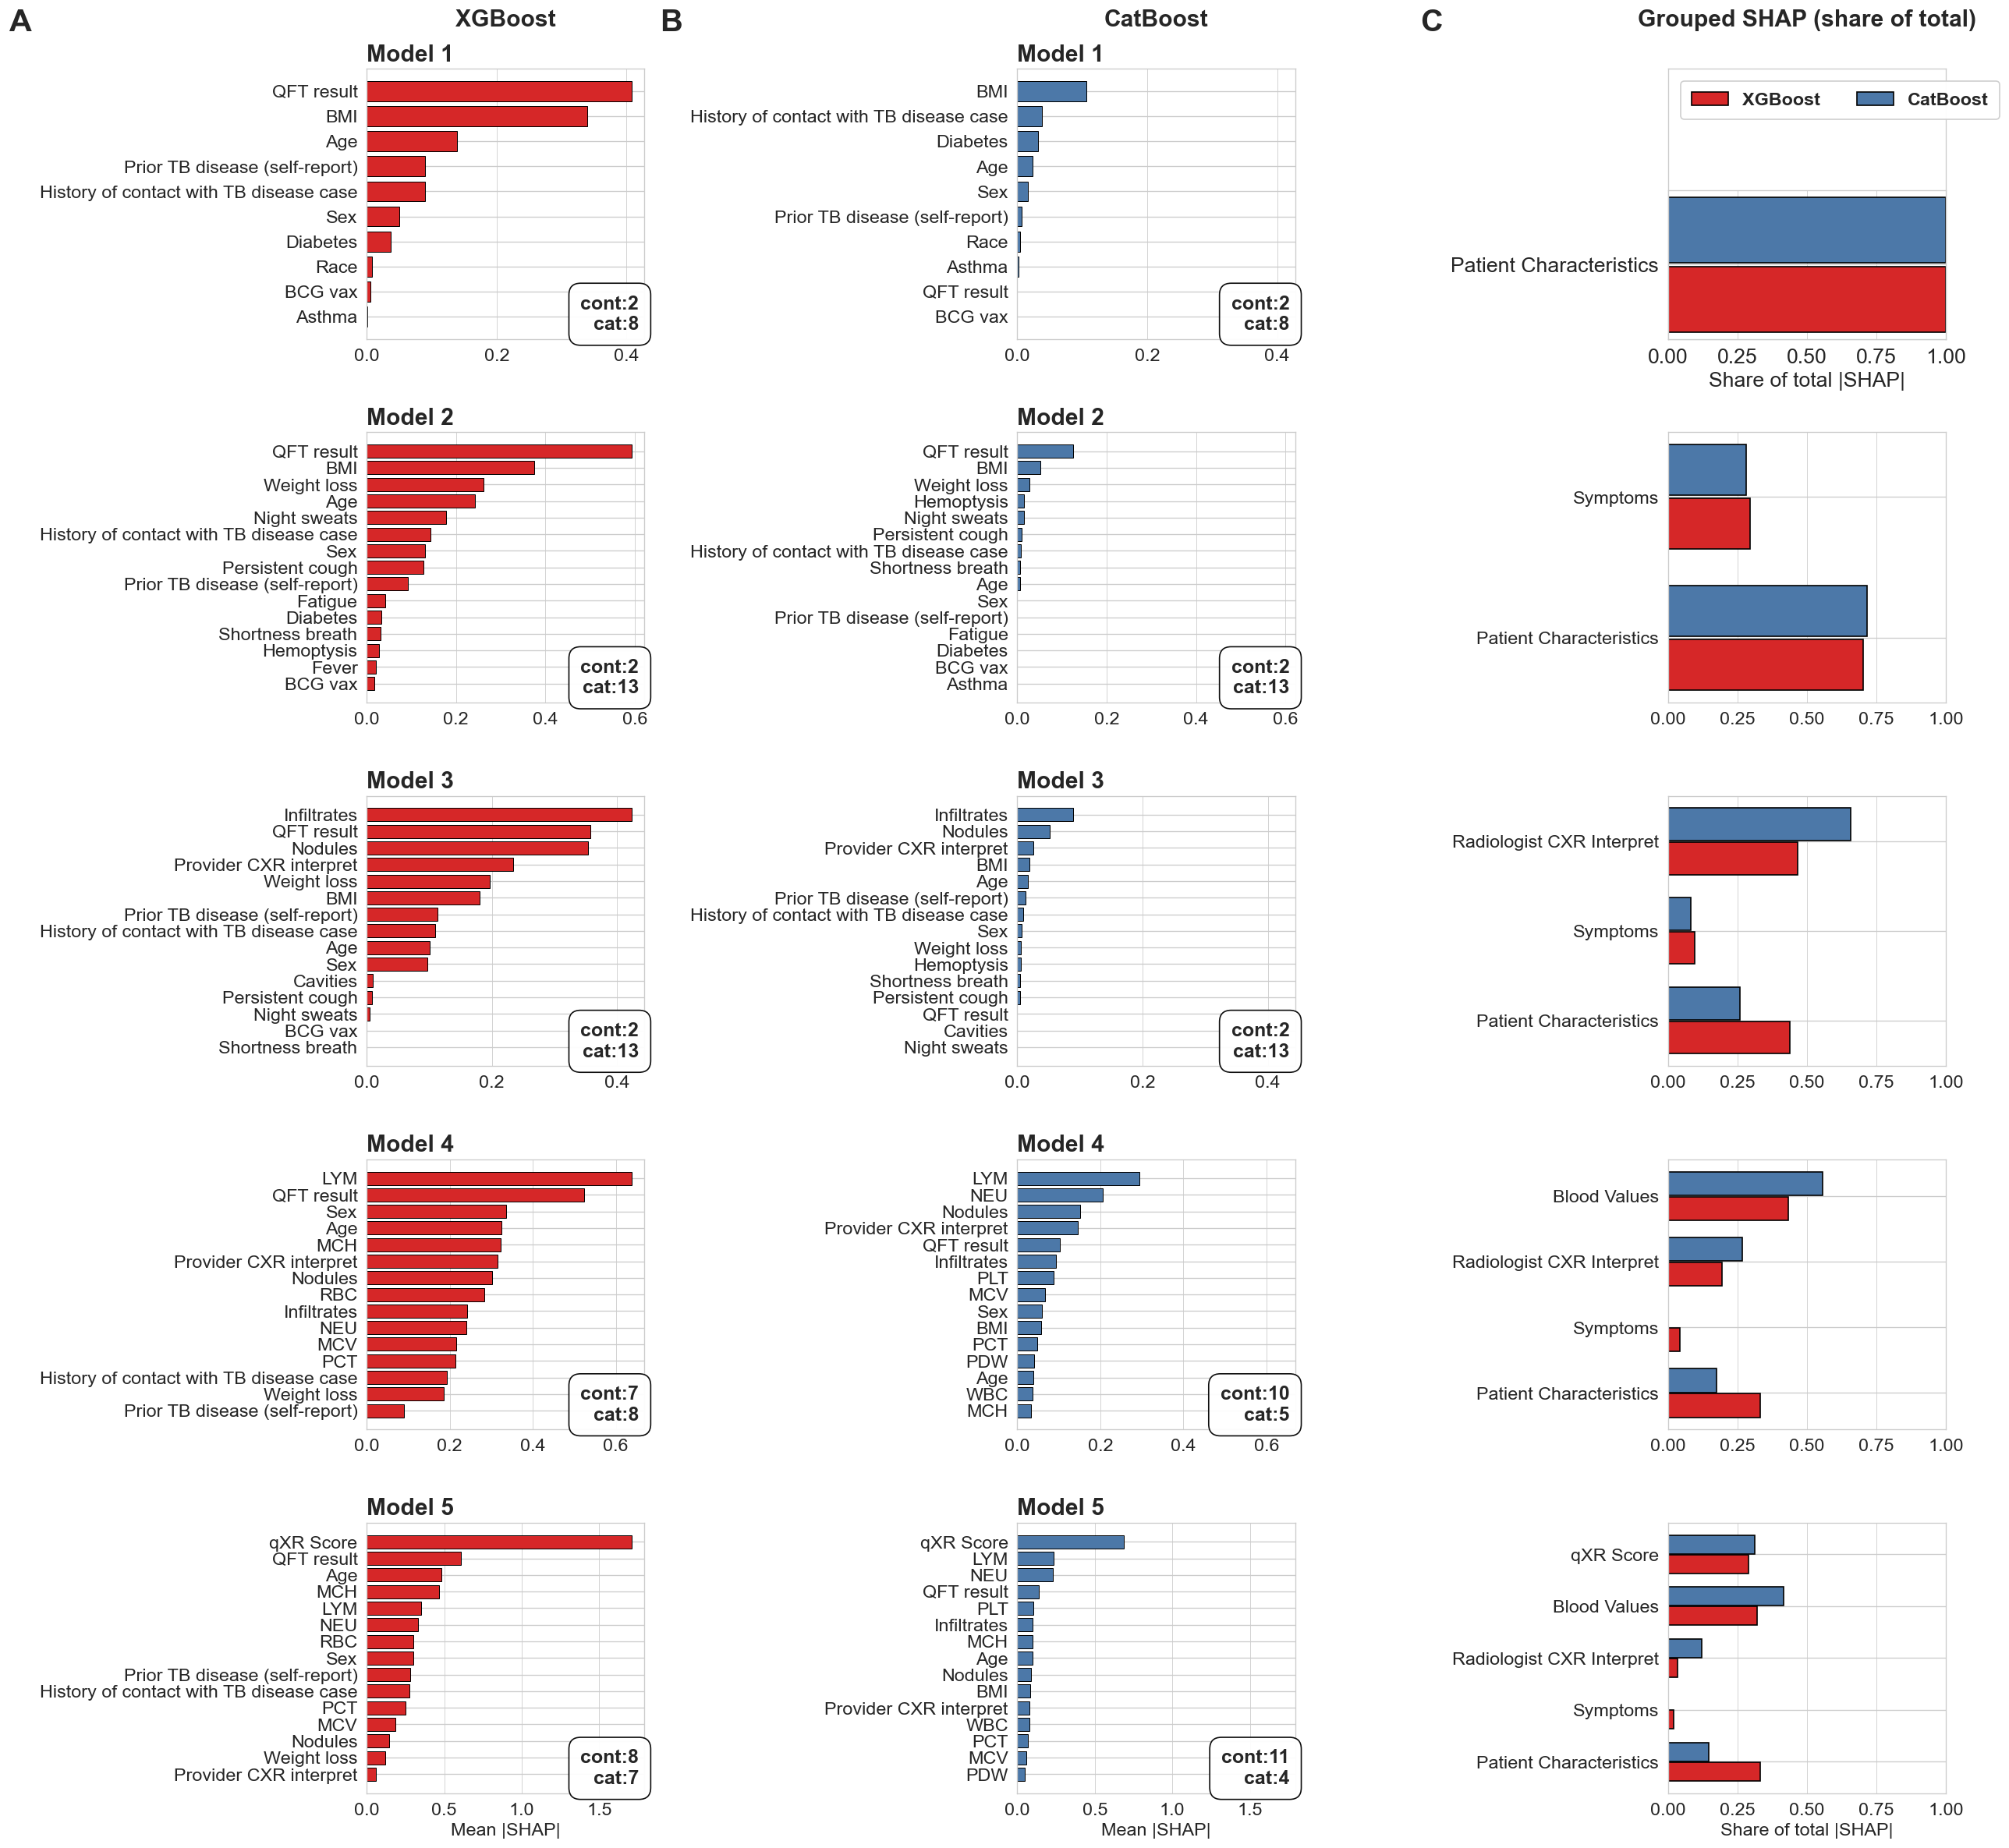

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_fig_rfe_carryforward_xgb_cat_plus_grouped.png


In [13]:
# =============== 12) FIGURE 4 (manuscript Figure 5): 5 MODELS SHAP + GROUPED ===============
from collections import OrderedDict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from sklearn.model_selection import StratifiedKFold
from xgboost import DMatrix, train as xgb_train
from catboost import CatBoostClassifier, Pool

# ---- Define stages ----
baseline_vars = ['age','gender','race_collapsed','bmi','diabetes','asthma',
                 'bcg','lived_with_another_tb','tb_history_prior','QFT_result_composite']
clinical_vars = ['persistent_cough','shortness_of_breath','fever','fatigue',
                 'cough_blood','weight_loss','night_sweats']
radiologist_interpret = ['lung_infiltrates','lung_nodules','lung_cavities',
                         'pleural_effusion','lymph_nodes','imaging_tb']
blood_vars_continuous = ["CBC_WBC","CBC_NEU_freq","CBC_LYM_freq","CBC_P_LCR",
                         "CBC_RBC","CBC_HGB","CBC_HCT","CBC_MCHC","CBC_MCH","CBC_MCV",
                         "CBC_RDW_CV","CBC_RDW_SD","CBC_PLT","CBC_MPV","CBC_PCT","CBC_PDW"]

stage_new = OrderedDict({
    "Model 1": baseline_vars,
    "Model 2": clinical_vars,
    "Model 3": radiologist_interpret,
    "Model 4": blood_vars_continuous,
    "Model 5": ["Score"],
})
stage_K = {"Model 1": 10, "Model 2": 15, "Model 3": 15, "Model 4": 15, "Model 5": 15}
GROUPS = {
    "Patient Characteristics": baseline_vars,
    "Symptoms": clinical_vars,
    "Radiologist CXR Interpret": radiologist_interpret,
    "Blood Values": blood_vars_continuous,
    "qXR Score": ["Score"],
}

# ---- Data (assumes upstream variables exist) ----
X_train_full = feature_train.copy()
X_test_full  = feature_test.copy()
y_train_full = target_train.astype(int).copy()
y_test_full  = target_test.astype(int).copy()

# Drop random control for this figure
if RAND_NAME in X_train_full: X_train_full = X_train_full.drop(columns=[RAND_NAME])
if RAND_NAME in X_test_full:  X_test_full  = X_test_full.drop(columns=[RAND_NAME])

def make_dm(df, y=None):
    return DMatrix(align_categoricals(df), label=y, enable_categorical=True)

def count_types_dynamic(feats, X_train, cat_names):
    feats = [f for f in feats if f in X_train.columns]
    cat_set = set(cat_names)
    n_cat = sum(1 for f in feats if f in cat_set)
    n_cont = len(feats) - n_cat
    n_bool = sum(1 for f in feats if str(X_train[f].dtype) == "bool")
    return n_cont, n_cat, n_bool

# ---- CatBoost verbosity scrubber (avoid conflicts) ----
def _clean_cat_verbose(params: dict) -> dict:
    p = dict(params)
    for k in ("verbose", "verbose_eval", "silent", "logging_level"):
        p.pop(k, None)
    p["logging_level"] = "Silent"   # choose exactly one
    return p

# ---- OOF mean |SHAP| per feature (re-trains per fold; quiet) ----
def oof_mean_abs_shap(algo, X, y, feats, n_outer=N_OUTER, seed=RANDOM_STATE):
    feats = [f for f in feats if f in X.columns]
    if not feats:
        return pd.Series(dtype=float)

    skf = StratifiedKFold(n_splits=n_outer, shuffle=True, random_state=seed)
    fold_means = []
    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        X_tr_full, y_tr_full = X.iloc[tr_idx], y.iloc[tr_idx]
        X_te = align_categoricals(X.iloc[te_idx][feats].copy())

        if algo == "XGB":
            (best, rounds), _ = tune_xgb_params_auc(X_tr_full, y_tr_full, feats, seed)  # [REV-0.4] single seed (was seed+fold)
            best = dict(best); best.setdefault("verbosity", 0)
            log_weighting(f"RFE |SHAP| fold {fold}", "XGB", best)  # [REV-0.1]
            dtr = make_dm(align_categoricals(X_tr_full[feats]), y_tr_full)
            booster = xgb_train(best, dtr, num_boost_round=rounds, verbose_eval=False)
            sv = np.asarray(booster.predict(make_dm(X_te), pred_contribs=True))[:, :len(feats)]
        else:  # CAT
            params_final, _ = tune_cat_params_auc(X_tr_full, y_tr_full, feats, seed)  # [REV-0.4] single seed (was seed+fold)
            params_final = _clean_cat_verbose(params_final)
            log_weighting(f"RFE |SHAP| fold {fold}", "CAT", params_final)  # [REV-0.1]
            Xt = align_categoricals(X_tr_full[feats])
            cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
            model = CatBoostClassifier(**params_final)
            # no verbose kw here; logging_level handled in params
            model.fit(Xt, y_tr_full, cat_features=cat_idx if len(cat_idx) else None)
            pool = Pool(X_te, cat_features=[X_te.columns.get_loc(c) for c in CATS if c in X_te.columns])
            sv = np.asarray(model.get_feature_importance(pool, type='ShapValues'))[:, :len(feats)]

        fold_means.append(np.abs(sv).mean(axis=0))

    return pd.Series(np.mean(fold_means, axis=0), index=feats)

# ---- Carry-forward RFE using OOF |SHAP| ----
def carry_forward_rfe(
    algo, X, y, stage_new: OrderedDict, stage_K: dict,
    *, verbose: bool = False, pretty_names: bool = True, log_path: str | None = None
):
    def _pretty(name: str) -> str:
        return rename_dict.get(name, name) if pretty_names else name

    selected_by_stage, rankings_by_stage, prev_selected = OrderedDict(), OrderedDict(), []
    events = []

    for stage, new_feats in stage_new.items():
        pool = list(dict.fromkeys(prev_selected + [f for f in new_feats if f in X.columns]))
        shap_series = oof_mean_abs_shap(algo, X, y, pool).sort_values(ascending=False)
        K = int(stage_K[stage])
        kept = list(shap_series.index[:min(K, len(shap_series))])

        retained_prev = [f for f in prev_selected if f in kept]
        dropped_prev  = [f for f in prev_selected if f not in kept]
        selected_new  = [f for f in new_feats if f in kept]
        not_selected_new = [f for f in new_feats if f not in kept]

        selected_by_stage[stage] = kept
        rankings_by_stage[stage] = shap_series
        prev_selected = kept

        if verbose:
            print(f"\n[{algo}] {stage}: K={len(kept)} from pool={len(pool)}")
            if retained_prev:
                print(f"  Retained ({len(retained_prev)}):", ", ".join(_pretty(x) for x in retained_prev))
            if selected_new:
                print(f"  Selected new ({len(selected_new)}):", ", ".join(_pretty(x) for x in selected_new))
            if dropped_prev:
                print(f"  Dropped from previous ({len(dropped_prev)}):", ", ".join(_pretty(x) for x in dropped_prev))
            if not_selected_new:
                print(f"  Not selected (new block) ({len(not_selected_new)}):", ", ".join(_pretty(x) for x in not_selected_new))

        for f in retained_prev:
            events.append({"Algo": algo, "Stage": stage, "Change": "Retained", "Feature": f, "Display": _pretty(f)})
        for f in selected_new:
            events.append({"Algo": algo, "Stage": stage, "Change": "Selected new", "Feature": f, "Display": _pretty(f)})
        for f in dropped_prev:
            events.append({"Algo": algo, "Stage": stage, "Change": "Dropped from previous", "Feature": f, "Display": _pretty(f)})
        for f in not_selected_new:
            events.append({"Algo": algo, "Stage": stage, "Change": "Not selected (new block)", "Feature": f, "Display": _pretty(f)})

    if log_path is not None:
        try:
            pd.DataFrame(events).to_csv(log_path, index=False)
            if verbose:
                print(f"\nSaved feature-change log to: {log_path}")
        except Exception as e:
            print(f"Warning: failed to save log to {log_path}: {e}")

    return selected_by_stage, rankings_by_stage

# ---- Run RFE ONCE per algorithm (with logs, quiet) ----
X_all = X_train_full.copy(); y_all = y_train_full.copy()
xgb_selected, xgb_rankings = carry_forward_rfe(
    "XGB", X_all, y_all, stage_new, stage_K, verbose=False, log_path=f"{CSV_DIR}/rev_rfe_flow_XGB.csv"
)
cat_selected, cat_rankings = carry_forward_rfe(
    "CAT", X_all, y_all, stage_new, stage_K, verbose=False, log_path=f"{CSV_DIR}/rev_rfe_flow_CatBoost.csv"
)

# ---- Final fits for plotting (once per stage; quiet) ----
def fit_final_xgb_for_fig(feats):
    Xt = align_categoricals(X_all[feats])
    (params, rounds), _ = tune_xgb_params_auc(X_all, y_all, feats, RANDOM_STATE)  # [REV-0.4] single seed (was RANDOM_STATE+123)
    params = dict(params); params.setdefault("verbosity", 0)
    booster = xgb_train(params, DMatrix(Xt, label=y_all, enable_categorical=True),
                        num_boost_round=rounds, verbose_eval=False)
    return booster, params, rounds  # [REV-0.2] keep tuned params for the OOF threshold

def fit_final_cat_for_fig(feats):
    Xt = align_categoricals(X_all[feats])
    params, _ = tune_cat_params_auc(X_all, y_all, feats, RANDOM_STATE)  # [REV-0.4] single seed (was RANDOM_STATE+123)
    params = _clean_cat_verbose(params)
    cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
    model = CatBoostClassifier(**params)
    model.fit(Pool(Xt, y_all, cat_features=cat_idx if len(cat_idx) else None))
    return model, params  # [REV-0.2] keep tuned params for the OOF threshold

# [REV-0.2] These bundles are the single M1–M5 model set (Fig 4, AP/AUC bars, stage metrics tables).
final_models_xgb, final_models_cat = OrderedDict(), OrderedDict()
for st, feats in xgb_selected.items():
    booster, params, rounds = fit_final_xgb_for_fig(feats)
    final_models_xgb[st] = {"model": booster, "feats": feats, "params": params, "rounds": rounds}
    log_weighting(f"Final M1-M5 ({st})", "XGB", params)
for st, feats in cat_selected.items():
    model, params = fit_final_cat_for_fig(feats)
    final_models_cat[st] = {"model": model, "feats": feats, "params": params}
    log_weighting(f"Final M1-M5 ({st})", "CAT", params)

# ---- SHAP helpers ----
def xgb_shap_on_test(booster, X_df):
    X_df = align_categoricals(X_df)
    return np.asarray(booster.predict(DMatrix(X_df, enable_categorical=True), pred_contribs=True))[:, :X_df.shape[1]]

def cat_shap_on_test(model, X_df):
    X_df = align_categoricals(X_df)
    pool = Pool(X_df, cat_features=[X_df.columns.get_loc(c) for c in CATS if c in X_df.columns])
    return np.asarray(model.get_feature_importance(pool, type='ShapValues'))[:, :X_df.shape[1]]

def _grouped_shap_for_stage(bundle, X, shap_func, groups: dict, normalize=True):
    feats = [f for f in bundle["feats"] if f in X.columns]
    Xs = align_categoricals(X[feats])
    sv = shap_func(bundle["model"], Xs)
    mag = np.abs(sv).mean(0)
    per_feat = pd.DataFrame({"feature": feats, "mean_abs_shap": mag})
    rows, inv = [], {}
    for g, flist in groups.items():
        for f in flist: inv.setdefault(f, []).append(g)
    for _, r in per_feat.iterrows():
        f = r["feature"]; v = float(r["mean_abs_shap"])
        for g in inv.get(f, ["(Unassigned)"]):
            rows.append((g, v))
    gdf = pd.DataFrame(rows, columns=["Group", "mean_abs_shap"])
    gsum = gdf.groupby("Group", as_index=False)["mean_abs_shap"].sum().rename(columns={"mean_abs_shap":"sum_abs_shap"})
    if normalize:
        tot = gsum["sum_abs_shap"].sum()
        gsum["frac"] = (gsum["sum_abs_shap"] / tot) if tot > 0 else 0.0
    return gsum

# ---- FIGURE LAYOUT & PLOTTING ----
fig, axes = plt.subplots(5, 3, figsize=(21, 20), sharex=False)
axes = np.atleast_2d(axes)
mpl.rcParams.update({"font.size": 16})  # global font

# Column headers
axes[0,0].annotate("XGBoost", xy=(0.5,1.14), xycoords="axes fraction",
                   ha="center", va="bottom", fontsize=18, fontweight="bold")
axes[0,1].annotate("CatBoost", xy=(0.5,1.14), xycoords="axes fraction",
                   ha="center", va="bottom", fontsize=18, fontweight="bold")
axes[0,2].annotate("Grouped SHAP (share of total)", xy=(0.5,1.14), xycoords="axes fraction",
                   ha="center", va="bottom", fontsize=18, fontweight="bold")

xgb_color, cat_color = "#d62728", "#4c78a8"
top_k_bars = 15

for ri, stage in enumerate(stage_new.keys()):
    # ---- LEFT: XGB per-feature SHAP ----
    fx = final_models_xgb[stage]
    Xtx = X_test_full[fx["feats"]]
    svx = xgb_shap_on_test(fx["model"], Xtx)
    meanx = np.abs(svx).mean(0)
    idx = np.argsort(-meanx)[:min(top_k_bars, len(meanx))]
    plot_x = pd.DataFrame({
        "Feature":[rename_dict.get(fx["feats"][i], fx["feats"][i]) for i in idx][::-1],
        "Mean|SHAP|":meanx[idx][::-1]
    })

    axL = axes[ri,0]
    axL.barh(plot_x["Feature"], plot_x["Mean|SHAP|"], color=xgb_color, edgecolor="black", linewidth=0.6)
    axL.set_title(stage, loc="left", fontsize=18, fontweight="bold")
    if ri == 4: axL.set_xlabel("Mean |SHAP|")
    axL.grid(True, axis="x", linewidth=0.5)

    x_cont, x_cat, _ = count_types_dynamic(fx["feats"], X_train_full, CATS)
    axL.text(0.98, 0.02, f"cont:{x_cont}\ncat:{x_cat}",
             transform=axL.transAxes, ha="right", va="bottom",
             fontsize=15, fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black", lw=1.0, alpha=0.95))

    # ---- MIDDLE: CAT per-feature SHAP ----
    fc = final_models_cat[stage]
    Xtc = X_test_full[fc["feats"]]
    svc = cat_shap_on_test(fc["model"], Xtc)
    meanc = np.abs(svc).mean(0)
    idc = np.argsort(-meanc)[:min(top_k_bars, len(meanc))]
    plot_c = pd.DataFrame({
        "Feature":[rename_dict.get(fc["feats"][i], fc["feats"][i]) for i in idc][::-1],
        "Mean|SHAP|":meanc[idc][::-1]
    })

    axR = axes[ri,1]
    axR.barh(plot_c["Feature"], plot_c["Mean|SHAP|"], color=cat_color, edgecolor="black", linewidth=0.6)
    axR.set_title(stage, loc="left", fontsize=18, fontweight="bold")
    if ri == 4: axR.set_xlabel("Mean |SHAP|")
    axR.grid(True, axis="x", linewidth=0.5)

    c_cont, c_cat, _ = count_types_dynamic(fc["feats"], X_train_full, CATS)
    axR.text(0.98, 0.02, f"cont:{c_cont}\ncat:{c_cat}",
             transform=axR.transAxes, ha="right", va="bottom",
             fontsize=15, fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black", lw=1.0, alpha=0.95))

    # ---- RIGHT: Grouped SHAP ----
    gx = _grouped_shap_for_stage(fx, X_test_full, lambda m, X: xgb_shap_on_test(m, X), GROUPS, normalize=True)
    gc = _grouped_shap_for_stage(fc, X_test_full, lambda m, X: cat_shap_on_test(m, X), GROUPS, normalize=True)
    canonical = list(GROUPS.keys())
    union = list(sorted(set(gx["Group"]).union(gc["Group"]),
                        key=lambda g: (0 if g in canonical else 1, canonical.index(g) if g in canonical else 999)))
    gx = gx.set_index("Group").reindex(union).fillna(0.0).reset_index()
    gc = gc.set_index("Group").reindex(union).fillna(0.0).reset_index()

    y_pos = np.arange(len(union))
    axG = axes[ri,2]

    if ri == 0:
        # Lower-half inset for bars
        axG_lower = axG.inset_axes([0.00, 0.00, 1.00, 0.55])
        bw = 0.25
        axG_lower.barh(y_pos - bw/2, gx["frac"].values, height=bw*0.95,
                       color=xgb_color, edgecolor="black", label="XGBoost")
        axG_lower.barh(y_pos + bw/2, gc["frac"].values, height=bw*0.95,
                       color=cat_color, edgecolor="black", label="CatBoost")
        axG_lower.set_yticks(y_pos); axG_lower.set_yticklabels(union)
        axG_lower.set_xlim(0, 1.0); axG_lower.grid(True, axis="x", linewidth=0.5)
        axG_lower.set_xlabel("Share of total |SHAP|")

        # Legend in upper half of parent axis (big & bold)
        handles, labels = axG_lower.get_legend_handles_labels()
        by_label = OrderedDict(zip(labels, handles))
        leg = axG.legend(by_label.values(), by_label.keys(),
                         loc="upper left", bbox_to_anchor=(0.02, 0.98),
                         frameon=True, framealpha=0.95, borderpad=0.6, borderaxespad=0.4,
                         ncol=2, fontsize=14)
        for txt in leg.get_texts():
            txt.set_fontweight("bold")
        axG.set_xticks([]); axG.set_yticks([])
    else:
        # No labels here -> no stray small legends
        bw = 0.38
        axG.barh(y_pos - bw/2, gx["frac"].values, height=bw*0.95, color=xgb_color, edgecolor="black")
        axG.barh(y_pos + bw/2, gc["frac"].values, height=bw*0.95, color=cat_color, edgecolor="black")
        axG.set_yticks(y_pos); axG.set_yticklabels(union); axG.set_xlim(0, 1.0)
        if ri == 4: axG.set_xlabel("Share of total |SHAP|")
        axG.grid(True, axis="x", linewidth=0.5)
        if axG.get_legend() is not None:
            axG.get_legend().remove()

# Harmonize x-lims in first two columns per row
for r in range(5):
    xmax = 0.0
    for c in (0,1):
        if len(axes[r,c].patches):
            xmax = max(xmax, max(p.get_width() for p in axes[r,c].patches))
    for c in (0,1):
        axes[r,c].set_xlim(0, xmax*1.05 if xmax>0 else 1.0)

fig_path = f"{IMG_DIR}/rev_fig_rfe_carryforward_xgb_cat_plus_grouped.png"
plt.tight_layout(h_pad=2.0, w_pad=2.2)
# [R1.5] Bold panel labels A–C at the top-left of the three column headers: placed just left of each top
# panel's full extent (tick labels + column header), measured after layout, so they never overlap the text.
fig.canvas.draw()
_renderer = fig.canvas.get_renderer()
for ci, letter in enumerate("ABC"):
    bb = axes[0, ci].get_tightbbox(_renderer).transformed(fig.transFigure.inverted())
    fig.text(bb.x0 - 0.004, bb.y1, letter, ha="right", va="top", fontsize=24, fontweight="bold")
plt.savefig(fig_path, dpi=300, bbox_inches="tight"); plt.show()  # [R1.5] was dpi=150
print("Saved:", fig_path)


In [14]:
# =============== 13) METRICS TABLES BY STAGE (TEST) ===============
# [REV-0.2] Single model set: the M1–M5 models are final_models_xgb / final_models_cat from the
# carry-forward cell (the same models as Fig 4 and the AP/AUC bar figure). This replaces
# eval_stage_cat / eval_stage_xgb, which re-tuned and re-fit a second set of models.
# Threshold per stage: specificity >= TARGET_SPEC on pooled 5-fold OOF predictions within TRAIN,
# refitting with the stage's tuned params and rounds; then applied unchanged to the test set.
# Test-set 95% CIs at the fixed threshold (test_ci): AUROC/AP/Brier from 2,000 bootstrap resamples of test rows;
# Sens/Spec/PPV/NPV exact Clopper–Pearson [REV-0.8]. Null Brier = no-skill reference [REV-0.7].
from scipy.stats import beta as beta_dist
N_BOOT      = 2000
BOOT_SEED   = RANDOM_STATE
METRIC_KEYS = ["Sens", "Spec", "PPV", "NPV", "AUROC", "AP", "Brier"]

def stage_test_probs(algo, bundle, X):
    Xs = align_categoricals(X[bundle["feats"]])
    if algo == "XGB":
        return as_proba(bundle["model"].predict(DMatrix(Xs, enable_categorical=True)))
    cat_idx = [Xs.columns.get_loc(c) for c in CATS if c in Xs.columns]
    return as_proba(bundle["model"].predict_proba(Pool(Xs, cat_features=cat_idx or None)))

def oof_probs_fixed_params(algo, bundle, X, y, n_splits=N_OUTER, seed=RANDOM_STATE):
    feats = bundle["feats"]
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.full(len(y), np.nan)
    for tr_idx, te_idx in skf.split(X, y):
        X_tr, X_te, y_tr = X.iloc[tr_idx][feats], X.iloc[te_idx][feats], y.iloc[tr_idx]
        dt_map = build_cat_dtypes_from_train(X_tr, CATS)
        X_tr = align_categoricals_with(dt_map, X_tr)
        X_te = align_categoricals_with(dt_map, X_te)
        X_tr, y_tr = apply_resampler(X_tr, y_tr)  # [R1.3] no-op unless R1.3 sets RESAMPLER
        if algo == "XGB":
            booster = xgb_train(bundle["params"], DMatrix(X_tr, label=y_tr, enable_categorical=True),
                                num_boost_round=bundle["rounds"], verbose_eval=False)
            oof[te_idx] = as_proba(booster.predict(DMatrix(X_te, enable_categorical=True)))
        else:
            cat_idx = [X_tr.columns.get_loc(c) for c in CATS if c in X_tr.columns]
            m = CatBoostClassifier(**bundle["params"])
            m.fit(Pool(X_tr, y_tr, cat_features=cat_idx or None))
            oof[te_idx] = as_proba(m.predict_proba(Pool(X_te, cat_features=cat_idx or None)))
    assert not np.isnan(oof).any()
    return oof

def metrics_at_thr(y, p, thr):
    sens, spec, ppv, npv = sens_spec_ppv_npv(y, p, thr)
    return dict(Sens=sens, Spec=spec, PPV=ppv, NPV=npv,
                AUROC=roc_auc_score(y, p), AP=average_precision_score(y, p),
                Brier=brier_score_loss(y, p))

def clopper_pearson(k, n, alpha=0.05):
    """Exact binomial CI; well-defined at 0/n and n/n, where percentile-bootstrap CIs collapse to a point."""
    if n == 0:
        return (np.nan, np.nan)
    lo = 0.0 if k == 0 else float(beta_dist.ppf(alpha / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(beta_dist.ppf(1 - alpha / 2, k + 1, n - k))
    return (lo, hi)

def test_ci(y, p, thr, B=N_BOOT, seed=BOOT_SEED):
    """[REV-0.8] 95% CIs for test-set metrics at a FIXED threshold: Sens/Spec/PPV/NPV exact Clopper–Pearson
    from the confusion matrix; AUROC/AP/Brier percentile bootstrap (B resamples of test rows)."""
    y = np.asarray(y).astype(int); p = as_proba(p)
    rng = np.random.default_rng(seed); n = len(y)
    draws = {k: [] for k in ["AUROC", "AP", "Brier"]}
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        if y[idx].min() == y[idx].max():
            continue  # AUROC/AP undefined without both classes
        m = metrics_at_thr(y[idx], p[idx], thr)
        for k in draws:
            draws[k].append(m[k])
    ci = {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in draws.items()}
    tn, fp, fn, tp = confusion_matrix(y, (p >= float(thr)).astype(int), labels=[0, 1]).ravel()
    ci.update(Sens=clopper_pearson(tp, tp + fn), Spec=clopper_pearson(tn, tn + fp),
              PPV=clopper_pearson(tp, tp + fp), NPV=clopper_pearson(tn, tn + fn))
    return ci

def null_brier(y_te, y_tr):
    """[REV-0.7] Brier score of predicting the training TB prevalence for everyone (no-skill reference)."""
    return float(np.mean((np.asarray(y_te, float) - float(np.mean(y_tr))) ** 2))

def recal_brier(platt, p_te, y_te, thr):
    """[REV-0.9] Brier (with bootstrap CI) of test predictions after the training-OOF recalibration."""
    p_cal = platt_apply(platt, p_te)
    return dict(p_test_cal=p_cal, brier_cal=float(brier_score_loss(y_te, p_cal)),
                brier_cal_ci=test_ci(y_te, p_cal, thr)["Brier"])

def fmt_brier_cal(ev):
    return f"{ev['brier_cal']:.3f} ({ev['brier_cal_ci'][0]:.3f}, {ev['brier_cal_ci'][1]:.3f})" if "brier_cal" in ev else ""

def n_trees(algo, bundle):
    return int(bundle["rounds"]) if algo == "XGB" else int(bundle["model"].tree_count_)

def _logit(p):
    p = np.clip(as_proba(p), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def platt_fit(y, p):
    """Logistic fit of the outcome on logit(p): logit P(y=1) = a + b*logit(p). Returns (a, b)."""
    y = np.asarray(y, dtype=float); lp = _logit(p)
    X2 = np.column_stack([np.ones_like(lp), lp]); beta = np.zeros(2)
    for _ in range(100):
        mu = 1 / (1 + np.exp(-(X2 @ beta)))
        step = np.linalg.solve(X2.T @ (X2 * (mu * (1 - mu))[:, None]), X2.T @ (y - mu))
        beta += step
        if np.abs(step).max() < 1e-10:
            break
    return float(beta[0]), float(beta[1])

def platt_apply(platt, p):
    """[REV-0.9] Apply a recalibration fitted on TRAINING OOF predictions. Used only for the 'Brier (recal.)'
    columns: AUROC/AP and sens/spec/PPV/NPV are always reported on the raw scale at the raw threshold."""
    a, b = platt
    return 1 / (1 + np.exp(-(a + b * _logit(p))))

def calibration_intercept_slope(y, p):
    """Calibration of p against y: slope b from logit P(y=1) = a + b*logit(p);
    intercept = calibration-in-the-large, a in logit P(y=1) = a + logit(p) (slope fixed at 1)."""
    y = np.asarray(y, dtype=float); lp = _logit(p)
    _, b = platt_fit(y, p)
    a = 0.0
    for _ in range(100):
        mu = 1 / (1 + np.exp(-(a + lp)))
        step = (y - mu).sum() / (mu * (1 - mu)).sum()
        a += step
        if abs(step) < 1e-10:
            break
    return float(a), float(b)

def stage_metrics_table(algo, final_models, X_tr, y_tr, X_te, y_te, target_spec=TARGET_SPEC):
    y_tr = y_tr.astype(int); y_te = np.asarray(y_te).astype(int)
    rows_fmt, rows_long, packs = [], [], OrderedDict()
    for st, bundle in final_models.items():
        oof = oof_probs_fixed_params(algo, bundle, X_tr, y_tr)
        thr, oof_sens, oof_spec = threshold_at_spec(y_tr, oof, target_spec)
        p_te  = stage_test_probs(algo, bundle, X_te)
        point = metrics_at_thr(y_te, p_te, thr)
        ci    = test_ci(y_te, p_te, thr)
        nb    = null_brier(y_te, y_tr)
        platt = platt_fit(y_tr, oof)                    # [REV-0.9] recalibration fitted on TRAINING OOF only
        cal   = recal_brier(platt, p_te, y_te, thr)
        packs[st] = dict(thr=thr, oof=oof, p_test=p_te, point=point, ci=ci, null_brier=nb,
                         trees=n_trees(algo, bundle), platt=platt, **cal)
        rows_fmt.append({"Model": st, "n_feats": len(bundle["feats"]),
                         **{k: f"{point[k]:.3f} ({ci[k][0]:.3f}, {ci[k][1]:.3f})" for k in METRIC_KEYS},
                         "Null Brier": round(nb, 3), "Brier (recal.)": fmt_brier_cal(cal), "Thr": round(thr, 4),
                         "Train OOF Sens": round(oof_sens, 3), "Train OOF Spec": round(oof_spec, 3),
                         "Trees": n_trees(algo, bundle),
                         "Test pred range": f"{p_te.min():.3f}–{p_te.max():.3f}"})
        for k in METRIC_KEYS:
            rows_long.append(dict(Algo=algo, Model=st, Metric=k, Estimate=point[k],
                                  CI_lo=ci[k][0], CI_hi=ci[k][1], Thr=thr))
    return pd.DataFrame(rows_fmt).set_index("Model"), pd.DataFrame(rows_long), packs

tbl_xgb, long_xgb, stage_eval_xgb = stage_metrics_table(
    "XGB", final_models_xgb, X_train_full, y_train_full, X_test_full, y_test_full)
tbl_cat, long_cat, stage_eval_cat = stage_metrics_table(
    "CAT", final_models_cat, X_train_full, y_train_full, X_test_full, y_test_full)

with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(f"\n=== Metrics — XGBoost (Test n={len(y_test_full)}, thr from train OOF at Spec>={TARGET_SPEC:.2f}; 95% bootstrap CI) ===")
    print(tbl_xgb)
    print(f"\n=== Metrics — CatBoost (Test n={len(y_test_full)}, thr from train OOF at Spec>={TARGET_SPEC:.2f}; 95% bootstrap CI) ===")
    print(tbl_cat)

tbl_xgb.to_csv(f"{CSV_DIR}/rev_metrics_by_stage_XGB_test_bootCI.csv")
tbl_cat.to_csv(f"{CSV_DIR}/rev_metrics_by_stage_CAT_test_bootCI.csv")
pd.concat([long_xgb, long_cat]).to_csv(f"{CSV_DIR}/rev_metrics_by_stage_test_bootCI_long.csv", index=False)
print("Saved metrics CSVs.")

# [REV-0.2] Shared helpers (also used by R2.5–2.7, R3.1, R3.2) for re-running the staged pipeline on a different sample, outcome or stage
# definition. Same recipe as above: carry_forward_rfe (OOF |SHAP|, train only) -> tune_*_params_auc + refit
# on the given training rows -> threshold from 5-fold train OOF -> test metrics with 95% CIs (test_ci).
# SCALE_POS is recomputed from the given training labels while tuning.
ALGO_NAME = {"XGB": "XGBoost", "CAT": "CatBoost"}
MAIN_RUN  = {"XGB": dict(models=final_models_xgb, evals=stage_eval_xgb),
             "CAT": dict(models=final_models_cat, evals=stage_eval_cat)}

def fit_stage_model(algo, X_tr, y_tr, feats):
    Xt = align_categoricals(X_tr[feats])
    if algo == "XGB":
        (params, rounds), _ = tune_xgb_params_auc(X_tr, y_tr, feats, RANDOM_STATE)
        params = dict(params); params.setdefault("verbosity", 0)
        booster = xgb_train(params, DMatrix(Xt, label=y_tr, enable_categorical=True),
                            num_boost_round=rounds, verbose_eval=False)
        return {"model": booster, "feats": feats, "params": params, "rounds": rounds}
    params, _ = tune_cat_params_auc(X_tr, y_tr, feats, RANDOM_STATE)
    params = _clean_cat_verbose(params)
    cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
    model = CatBoostClassifier(**params)
    model.fit(Pool(Xt, y_tr, cat_features=cat_idx or None))
    return {"model": model, "feats": feats, "params": params}

def run_staged_pipeline(label, slug, X_tr, y_tr, X_te, y_te, stages=stage_new, ks=stage_K):
    global SCALE_POS, WEIGHT_CONTEXT
    saved_scale = SCALE_POS
    SCALE_POS, WEIGHT_CONTEXT = float((y_tr == 0).sum() / (y_tr == 1).sum()), label
    print(f"[{label}] train n={len(y_tr)} (TB={int(y_tr.sum())}) | test n={len(y_te)} (TB={int(y_te.sum())}) | SCALE_POS={SCALE_POS:.3f}")
    out = {}
    try:
        for algo in ["XGB", "CAT"]:
            selected, _ = carry_forward_rfe(algo, X_tr, y_tr, stages, ks, verbose=False,
                                            log_path=f"{CSV_DIR}/rev_rfe_flow_{algo}_{slug}.csv")
            models = OrderedDict()
            for st, feats in selected.items():
                models[st] = fit_stage_model(algo, X_tr, y_tr, feats)
                log_weighting(f"Final M1-M5 ({st})", algo, models[st]["params"])
            _, _, evals = stage_metrics_table(algo, models, X_tr, y_tr, X_te, y_te)
            out[algo] = dict(models=models, evals=evals)
    finally:
        SCALE_POS, WEIGHT_CONTEXT = saved_scale, "main"
    return out

def eval_row(algo, model, analysis, ev, y_te, feats):
    return {"Algorithm": ALGO_NAME[algo], "Model": model, "Analysis": analysis,
            "n_test": len(y_te), "TB_test": int(np.sum(y_te)), "n_feats": len(feats),
            **{k: f"{ev['point'][k]:.3f} ({ev['ci'][k][0]:.3f}, {ev['ci'][k][1]:.3f})" for k in METRIC_KEYS},
            "Null Brier": round(ev["null_brier"], 3), "Brier (recal.)": fmt_brier_cal(ev),
            "Thr": round(ev["thr"], 4), "Features": "; ".join(rename_dict.get(f, f) for f in feats)}

def fixed_thr_eval(p, y, thr, y_train_ref, platt=None):
    """Score given predictions at a FIXED threshold (no re-fitting, no threshold choice on these rows).
    `platt` = the model's training-OOF recalibration, applied unchanged."""
    y = np.asarray(y).astype(int)
    ev = dict(thr=thr, p_test=p, point=metrics_at_thr(y, p, thr), ci=test_ci(y, p, thr),
              null_brier=null_brier(y, y_train_ref))
    if platt is not None:
        ev.update(platt=platt, **recal_brier(platt, p, y, thr))
    return ev

def subset_eval(main_ev, mask, y_sub):
    """Main model + its fixed threshold and recalibration, scored on a subset of the test rows."""
    return fixed_thr_eval(main_ev["p_test"][np.asarray(mask)], y_sub, main_ev["thr"], y_train_full, main_ev["platt"])



=== Metrics — XGBoost (Test n=159, thr from train OOF at Spec>=0.70; 95% bootstrap CI) ===
         n_feats                  Sens                  Spec                   PPV                   NPV                 AUROC                    AP                 Brier  Null Brier        Brier (recal.)     Thr  Train OOF Sens  Train OOF Spec  \
Model                                                                                                                                                                                                                                                  
Model 1       10  0.571 (0.394, 0.737)  0.685 (0.596, 0.766)  0.339 (0.221, 0.474)  0.850 (0.765, 0.914)  0.629 (0.519, 0.740)  0.329 (0.224, 0.494)  0.239 (0.215, 0.264)       0.172  0.169 (0.134, 0.205)  0.5532           0.667           0.701   
Model 2       15  0.600 (0.421, 0.761)  0.677 (0.588, 0.759)  0.344 (0.227, 0.477)  0.857 (0.772, 0.920)  0.663 (0.550, 0.773)  0.391 (0.258, 0.562)  0.250 (0.217, 

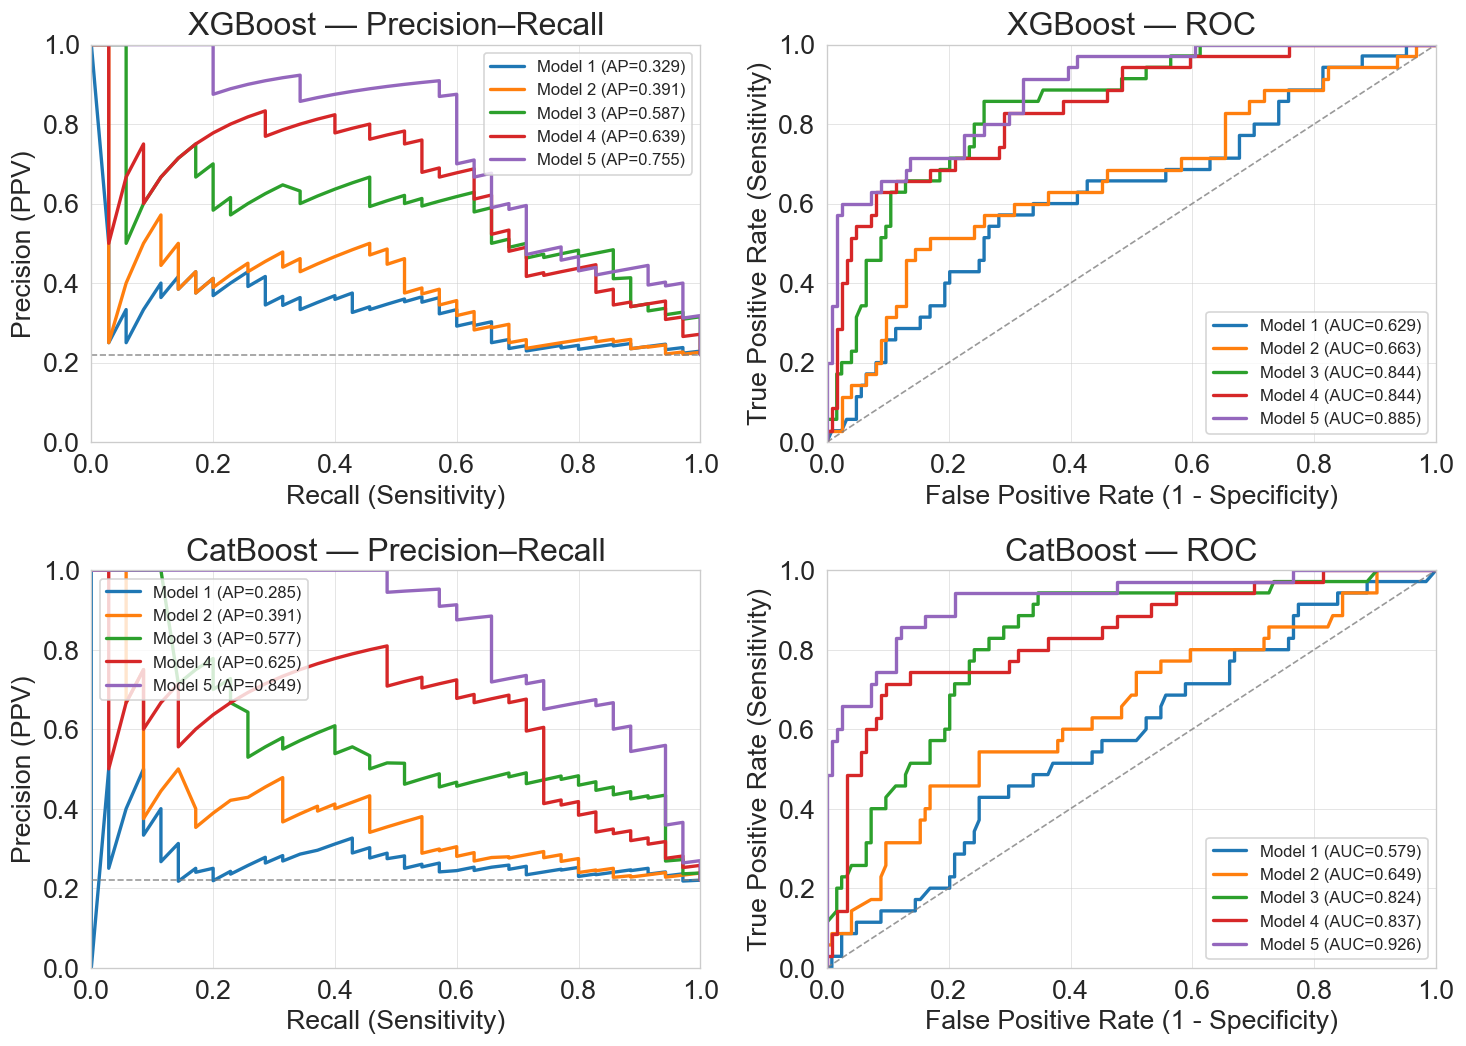

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_fig_staged_PR_left_ROC_right_xgb_cat.png


In [15]:
# =============== FIGURE: PR (left) + ROC (right) for 5 staged models, XGB (top) & CAT (bottom) ===============
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_curve, roc_auc_score

# [REV-cleanup] test-set probabilities come from stage_test_probs (cell 13), shared by all figures
def _plot_pr_roc_row(final_models, algo_label, ax_pr, ax_roc, colors=None):
    # consistent model order
    stages = list(stage_new.keys())
    if colors is None:
        colors = plt.cm.tab10.colors  # 10 distinct colors; we need first 5

    # prevalence baseline for PR
    prev = float(np.mean(y_test_full))

    for i, st in enumerate(stages):
        bundle = final_models[st]
        p = stage_test_probs("XGB" if algo_label.upper().startswith("XGB") else "CAT", bundle, X_test_full)

        # PR
        prec, rec, _ = precision_recall_curve(y_test_full, p)
        ap = average_precision_score(y_test_full, p)
        ax_pr.plot(rec, prec, lw=2, color=colors[i], label=f"{st} (AP={ap:.3f})")

        # ROC
        fpr, tpr, _ = roc_curve(y_test_full, p)
        auc = roc_auc_score(y_test_full, p)
        ax_roc.plot(fpr, tpr, lw=2, color=colors[i], label=f"{st} (AUC={auc:.3f})")

    # PR cosmetics
    ax_pr.set_title(f"{algo_label} — Precision–Recall")
    ax_pr.set_xlabel("Recall (Sensitivity)"); ax_pr.set_ylabel("Precision (PPV)")
    ax_pr.set_xlim(0, 1); ax_pr.set_ylim(0, 1)
    ax_pr.axhline(prev, ls="--", lw=1, color="gray", alpha=0.8)  # prevalence baseline
    ax_pr.grid(True, linewidth=0.5, alpha=0.6)
    ax_pr.legend(frameon=True, fontsize=10)

    # ROC cosmetics
    ax_roc.set_title(f"{algo_label} — ROC")
    ax_roc.set_xlabel("False Positive Rate (1 - Specificity)"); ax_roc.set_ylabel("True Positive Rate (Sensitivity)")
    ax_roc.set_xlim(0, 1); ax_roc.set_ylim(0, 1)
    ax_roc.plot([0,1], [0,1], ls="--", lw=1, color="gray", alpha=0.8)
    ax_roc.grid(True, linewidth=0.5, alpha=0.6)
    ax_roc.legend(frameon=True, fontsize=10)

# --- figure layout: 2 rows (XGB, CAT) x 2 cols (PR, ROC) ---
fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.0), sharex=False, sharey=False)
(ax_pr_xgb, ax_roc_xgb), (ax_pr_cat, ax_roc_cat) = axes

_plot_pr_roc_row(final_models_xgb, "XGBoost", ax_pr_xgb, ax_roc_xgb)
_plot_pr_roc_row(final_models_cat, "CatBoost", ax_pr_cat, ax_roc_cat)

plt.tight_layout()
out_path = f"{IMG_DIR}/rev_fig_staged_PR_left_ROC_right_xgb_cat.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight"); plt.show()
print("Saved:", out_path)


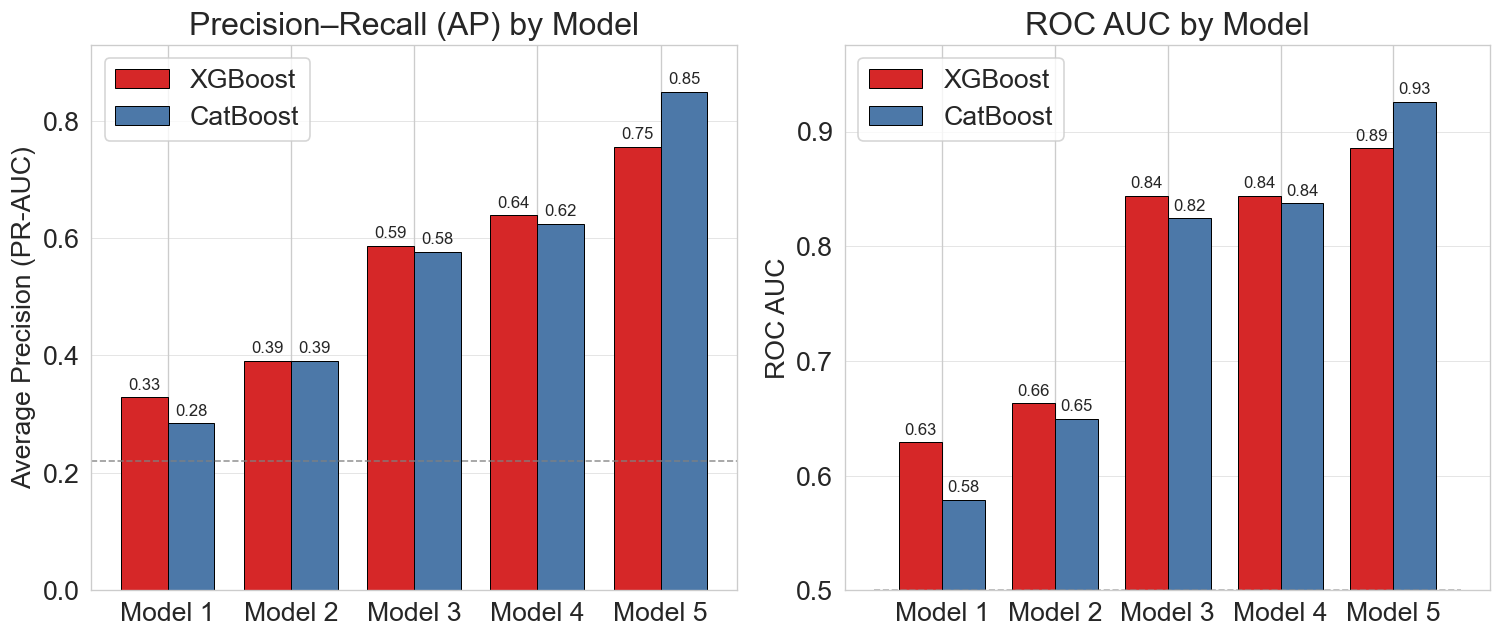

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_fig_bar_AP_left_AUC_right_stages_xgb_cat.png
              AP              AUC        
Algo    CatBoost XGBoost CatBoost XGBoost
Model                                    
Model 1    0.285   0.329    0.579   0.629
Model 2    0.391   0.391    0.649   0.663
Model 3    0.577   0.587    0.824   0.844
Model 4    0.625   0.639    0.837   0.844
Model 5    0.849   0.755    0.926   0.885


In [16]:
# =============== FIGURE: Barplots — PR-AUC (left) and ROC-AUC (right) across 5 stages ===============
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score

# [REV-cleanup] test-set probabilities come from stage_test_probs (cell 13), shared by all figures
stages = list(stage_new.keys())
metrics = []
for st in stages:
    # XGB
    p_x = stage_test_probs("XGB", final_models_xgb[st], X_test_full)
    metrics.append({"Model": st, "Algo": "XGBoost",
                    "AP": average_precision_score(y_test_full, p_x),
                    "AUC": roc_auc_score(y_test_full, p_x)})
    # CAT
    p_c = stage_test_probs("CAT", final_models_cat[st], X_test_full)
    metrics.append({"Model": st, "Algo": "CatBoost",
                    "AP": average_precision_score(y_test_full, p_c),
                    "AUC": roc_auc_score(y_test_full, p_c)})

bar_df = pd.DataFrame(metrics)  # [REV-cleanup] renamed: the generic name was reused by other cells

# Colors to match your scheme
xgb_color, cat_color = "#d62728", "#4c78a8"

# Prepare grouped bars
x = np.arange(len(stages)); w = 0.38
ap_xgb  = bar_df[bar_df.Algo=="XGBoost"].set_index("Model").loc[stages]["AP"].values
ap_cat  = bar_df[bar_df.Algo=="CatBoost"].set_index("Model").loc[stages]["AP"].values
auc_xgb = bar_df[bar_df.Algo=="XGBoost"].set_index("Model").loc[stages]["AUC"].values
auc_cat = bar_df[bar_df.Algo=="CatBoost"].set_index("Model").loc[stages]["AUC"].values
prev = float(np.mean(y_test_full))

fig, (ax_ap, ax_auc) = plt.subplots(1, 2, figsize=(12.8, 5.6))

# --- PR-AUC (AP) ---
bars_ap_x = ax_ap.bar(x - w/2, ap_xgb, width=w, label="XGBoost",
                      color=xgb_color, edgecolor="black", linewidth=0.6)
bars_ap_c = ax_ap.bar(x + w/2, ap_cat, width=w, label="CatBoost",
                      color=cat_color, edgecolor="black", linewidth=0.6)
ax_ap.set_xticks(x); ax_ap.set_xticklabels(stages)
ap_max = float(np.max([ap_xgb.max(), ap_cat.max()]))
ax_ap.set_ylim(0, min(1.0, ap_max + 0.08))  # add headroom for labels
ax_ap.set_ylabel("Average Precision (PR-AUC)")
ax_ap.set_title("Precision–Recall (AP) by Model")
ax_ap.axhline(prev, ls="--", lw=1, color="gray", alpha=0.8)  # prevalence baseline
ax_ap.grid(True, axis="y", linewidth=0.5, alpha=0.6)
ax_ap.legend(frameon=True)

# add value labels
try:
    ax_ap.bar_label(bars_ap_x, fmt="%.2f", padding=3, fontsize=10)
    ax_ap.bar_label(bars_ap_c, fmt="%.2f", padding=3, fontsize=10)
except Exception:
    # fallback if bar_label is unavailable
    for bars in (bars_ap_x, bars_ap_c):
        for b in bars:
            h = b.get_height()
            ax_ap.text(b.get_x()+b.get_width()/2, h + 0.02, f"{h:.2f}",
                       ha="center", va="bottom", fontsize=10)

# --- ROC-AUC ---
bars_auc_x = ax_auc.bar(x - w/2, auc_xgb, width=w, label="XGBoost",
                        color=xgb_color, edgecolor="black", linewidth=0.6)
bars_auc_c = ax_auc.bar(x + w/2, auc_cat, width=w, label="CatBoost",
                        color=cat_color, edgecolor="black", linewidth=0.6)
ax_auc.set_xticks(x); ax_auc.set_xticklabels(stages)
auc_max = float(np.max([auc_xgb.max(), auc_cat.max()]))
auc_min = float(np.min([auc_xgb.min(), auc_cat.min()]))
ax_auc.set_ylim(max(0.45, min(0.5, auc_min - 0.02)), min(1.0, auc_max + 0.05))
ax_auc.set_ylabel("ROC AUC")
ax_auc.set_title("ROC AUC by Model")
ax_auc.plot([x[0]-0.6, x[-1]+0.6], [0.5, 0.5], ls="--", lw=1, color="gray", alpha=0.6)
ax_auc.grid(True, axis="y", linewidth=0.5, alpha=0.6)
ax_auc.legend(frameon=True)

# add value labels
try:
    ax_auc.bar_label(bars_auc_x, fmt="%.2f", padding=3, fontsize=10)
    ax_auc.bar_label(bars_auc_c, fmt="%.2f", padding=3, fontsize=10)
except Exception:
    for bars in (bars_auc_x, bars_auc_c):
        for b in bars:
            h = b.get_height()
            ax_auc.text(b.get_x()+b.get_width()/2, h + 0.015, f"{h:.2f}",
                        ha="center", va="bottom", fontsize=10)

plt.tight_layout()
out_path = f"{IMG_DIR}/rev_fig_bar_AP_left_AUC_right_stages_xgb_cat.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight"); plt.show()
print("Saved:", out_path)
print(bar_df.pivot_table(index="Model", columns="Algo", values=["AP","AUC"]).round(3))


/Users/hbattey/Desktop/global/lib/python3.12/site-packages/shap/plots/_beeswarm.py:950: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pl.tight_layout()
/Users/hbattey/Desktop/global/lib/python3.12/site-packages/shap/plots/_beeswarm.py:950: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pl.tight_layout()


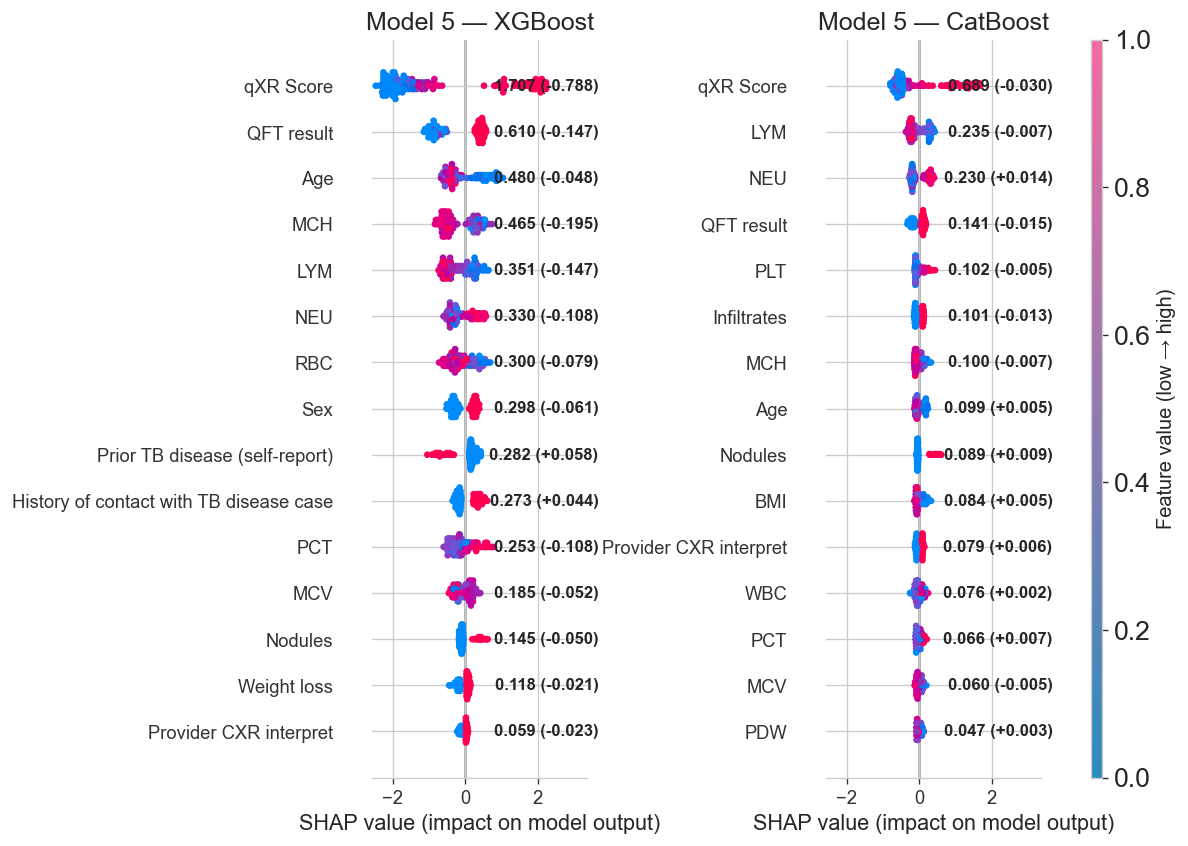

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_fig5_shap_beeswarm_model5_xgb_vs_cat_wide_annotated.png


In [17]:
# =============== 14) FIGURE 5: SHAP BEESWARMS (MODEL 5) ===============
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec
from matplotlib import transforms as mtrans
from xgboost import DMatrix
from catboost import Pool
import shap  # pip install shap
from matplotlib.colors import LinearSegmentedColormap

blue_purple_pink = LinearSegmentedColormap.from_list(
    "blue_purple_pink", ["#2b8cbe", "#9e77e5", "#f768a1"], N=256
)
# pass this to shap.summary_plot(..., color=blue_purple_pink, ...)


# ---- Grab Model 5 bundles (assumes final_models_xgb/cat exist from earlier steps) ----
bundle_xgb = final_models_xgb["Model 5"]
bundle_cat = final_models_cat["Model 5"]

# Exclude the random control feature if present
_rand = globals().get("RAND_NAME", None)
feats_xgb = [f for f in bundle_xgb["feats"] if (_rand is None or f != _rand)]
feats_cat = [f for f in bundle_cat["feats"] if (_rand is None or f != _rand)]

# Prepare test matrices (assumes feature_test and align_categoricals, CATS, rename_dict exist)
X5_raw_xgb = align_categoricals(feature_test[feats_xgb].copy())
X5_raw_cat = align_categoricals(feature_test[feats_cat].copy())

def to_numeric_for_coloring(X: pd.DataFrame) -> pd.DataFrame:
    import numpy as np, pandas as pd
    from pandas.api.types import is_object_dtype

    # optional: enforce desired orders so colors match intuition
    desired_orders = {
        "QFT_result_composite": ["Negative", "Indeterminate", "Positive"],
        "gender": ["Female", "Male"],  # Female=blue (low), Male=pink (high)
    }

    Xn = X.copy()
    for col in Xn.columns:
        s = Xn[col]

        # if categorical / object / declared CATS → treat as categorical
        is_cat = isinstance(s.dtype, pd.CategoricalDtype) or is_object_dtype(s) or (col in CATS)

        if is_cat:
            s = s.astype("category")
            # apply desired order if provided (and present)
            if col in desired_orders:
                cats = [c for c in desired_orders[col] if c in s.cat.categories]
                # keep any remaining categories (except __OTHER__) at the end (optional)
                tail = [c for c in s.cat.categories if c not in cats and c != "__OTHER__"]
                s = s.cat.set_categories(cats + tail, ordered=True)

            # drop the placeholder category from mapping if present
            cats = [c for c in s.cat.categories if c != "__OTHER__"]
            if len(cats) <= 1:
                Xn[col] = 0.0
                continue

            # map categories → 0..k-1, then → evenly spaced anchors in [0,1]
            code_map = {c: i for i, c in enumerate(cats)}
            raw_codes = s.map(code_map)
            k = len(cats)
            anchors = np.linspace(0.0, 1.0, k)
            anchor_map = {i: anchors[i] for i in range(k)}
            Xn[col] = raw_codes.map(anchor_map).astype(float)

        else:
            # continuous: keep numeric (no discrete anchors)
            Xn[col] = pd.to_numeric(s, errors="coerce")

    return Xn.rename(columns=rename_dict)

# Display frames (renamed for axis labels) + color frames (numeric)
X5_disp_xgb = X5_raw_xgb.rename(columns=rename_dict)
X5_disp_cat = X5_raw_cat.rename(columns=rename_dict)
X5_color_xgb = to_numeric_for_coloring(X5_raw_xgb)
X5_color_cat = to_numeric_for_coloring(X5_raw_cat)

# ---- Native SHAP extraction helpers ----
def xgb_shap_values_native(booster, X_df):
    d = DMatrix(align_categoricals(X_df), enable_categorical=True)
    contrib = booster.predict(d, pred_contribs=True)
    return np.asarray(contrib)[:, :X_df.shape[1]]  # drop bias term

def cat_shap_values_native(model, X_df):
    pool = Pool(align_categoricals(X_df), cat_features=[X_df.columns.get_loc(c) for c in CATS if c in X_df.columns])
    shap_vals = model.get_feature_importance(pool, type='ShapValues')
    return np.asarray(shap_vals)[:, :X_df.shape[1]]  # drop bias term

# ---- Compute SHAP values (Model 5) ----
sv5_xgb = xgb_shap_values_native(bundle_xgb["model"], X5_raw_xgb)
sv5_cat = cat_shap_values_native(bundle_cat["model"], X5_raw_cat)

# Order by mean absolute SHAP (ranking), but also compute SIGNED means for annotation
mean_abs5_xgb    = pd.Series(np.abs(sv5_xgb).mean(0), index=list(X5_disp_xgb.columns))
mean_abs5_cat    = pd.Series(np.abs(sv5_cat).mean(0), index=list(X5_disp_cat.columns))
mean_signed5_xgb = pd.Series(sv5_xgb.mean(0), index=list(X5_disp_xgb.columns))
mean_signed5_cat = pd.Series(sv5_cat.mean(0), index=list(X5_disp_cat.columns))

# ---- Shared axis limits across panels ----
blue_pink = LinearSegmentedColormap.from_list("blue_pink", ["#2b8cbe", "#f768a1"])
x_min_raw = float(min(np.nanmin(sv5_xgb), np.nanmin(sv5_cat)))
x_max_raw = float(max(np.nanmax(sv5_xgb), np.nanmax(sv5_cat)))
if not np.isfinite([x_min_raw, x_max_raw]).all():
    x_min_raw, x_max_raw = -1.0, 1.0
span = x_max_raw - x_min_raw if x_max_raw > x_min_raw else 1.0
shared_xlim = (x_min_raw - 0.02*span, x_max_raw + 0.24*span)  # room for numbers at right
blue_pink_mapper = ScalarMappable(cmap=blue_pink); blue_pink_mapper.set_array([])

# ---- Figure layout ----
fig = plt.figure(figsize=(26, 10), constrained_layout=False)
gs  = gridspec.GridSpec(1, 4, figure=fig, width_ratios=[1.15, 0.75, 1.15, 0.06], wspace=0.34)
ax1 = fig.add_subplot(gs[0, 0])   # XGB beeswarm
ax2 = fig.add_subplot(gs[0, 2])   # CAT beeswarm
cax = fig.add_subplot(gs[0, 3])   # colorbar

def beeswarm(ax, sv, X_color, title):
    plt.sca(ax)
    shap.summary_plot(
        sv, X_color,
        feature_names=list(X_color.columns),
        plot_type="dot", show=False,
        color=blue_pink, color_bar=False,
        max_display=20
    )
    ax = plt.gca()
    ax.set_title(title, fontsize=15)
    ax.set_xlim(*shared_xlim)
    ax.tick_params(axis="y", labelsize=11)
    return ax

ax1 = beeswarm(ax1, sv5_xgb, X5_color_xgb, "Model 5 — XGBoost")
ax2 = beeswarm(ax2, sv5_cat, X5_color_cat, "Model 5 — CatBoost")

# --- Replace your annotation helper + calls with this ---

from matplotlib import transforms as mtrans

def annotate_abs_then_signed(ax, abs_means, signed_means, *,
                             x_frac=1.02, dx_pts=0, fontsize=10):
    """
    Write 'abs (±signed)' to the right of each y-tick label.
    x_frac : x in axes fraction (0.1 inside; >1 outside to the right).
    dx_pts : extra rightward offset in display points.
    """
    ylabels = [t.get_text() for t in ax.get_yticklabels()]
    ylocs   = ax.get_yticks()

    # base: x in axes coords, y in data coords
    trans = mtrans.blended_transform_factory(ax.transAxes, ax.transData)
    if dx_pts:
        trans = trans + mtrans.ScaledTranslation(dx_pts/72.0, 0, ax.figure.dpi_scale_trans)

    ha = "left" if x_frac >= 1.0 else "right"

    for y, label in zip(ylocs, ylabels):
        a = abs_means.get(label, None)
        s = signed_means.get(label, None)
        if a is None and s is None:
            continue
        if (a is not None) and (s is not None):
            txt = f"{float(a):.3f} ({float(s):+.3f})"
        elif a is not None:
            txt = f"{float(a):.3f}"
        else:
            txt = f"({float(s):+.3f})"
        ax.text(x_frac, y, txt, transform=trans, ha=ha, va="center",
                fontweight="bold", fontsize=fontsize, clip_on=False)


annotate_abs_then_signed(
    ax1,
    mean_abs5_xgb.rename(index=rename_dict),
    mean_signed5_xgb.rename(index=rename_dict),
    x_frac=0.99, dx_pts=8, fontsize=10
)
annotate_abs_then_signed(
    ax2,
    mean_abs5_cat.rename(index=rename_dict),
    mean_signed5_cat.rename(index=rename_dict),
    x_frac=0.99, dx_pts=8, fontsize=10
)



# ---- Colorbar & final layout ----
cbar = fig.colorbar(blue_pink_mapper, cax=cax)
cbar.set_label("Feature value (low → high)", fontsize=12)

fig.subplots_adjust(left=0.26, right=1.02, bottom=0.10, top=0.92, wspace=0.34)

# ---- Save ----
out_path = f"{IMG_DIR}/rev_fig5_shap_beeswarm_model5_xgb_vs_cat_wide_annotated.png"  # [REV-cleanup] distinct name
plt.savefig(out_path, dpi=220, bbox_inches="tight"); plt.show()
print("Saved:", out_path)


/Users/hbattey/Desktop/global/lib/python3.12/site-packages/shap/plots/_beeswarm.py:950: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pl.tight_layout()
/Users/hbattey/Desktop/global/lib/python3.12/site-packages/shap/plots/_beeswarm.py:950: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  pl.tight_layout()


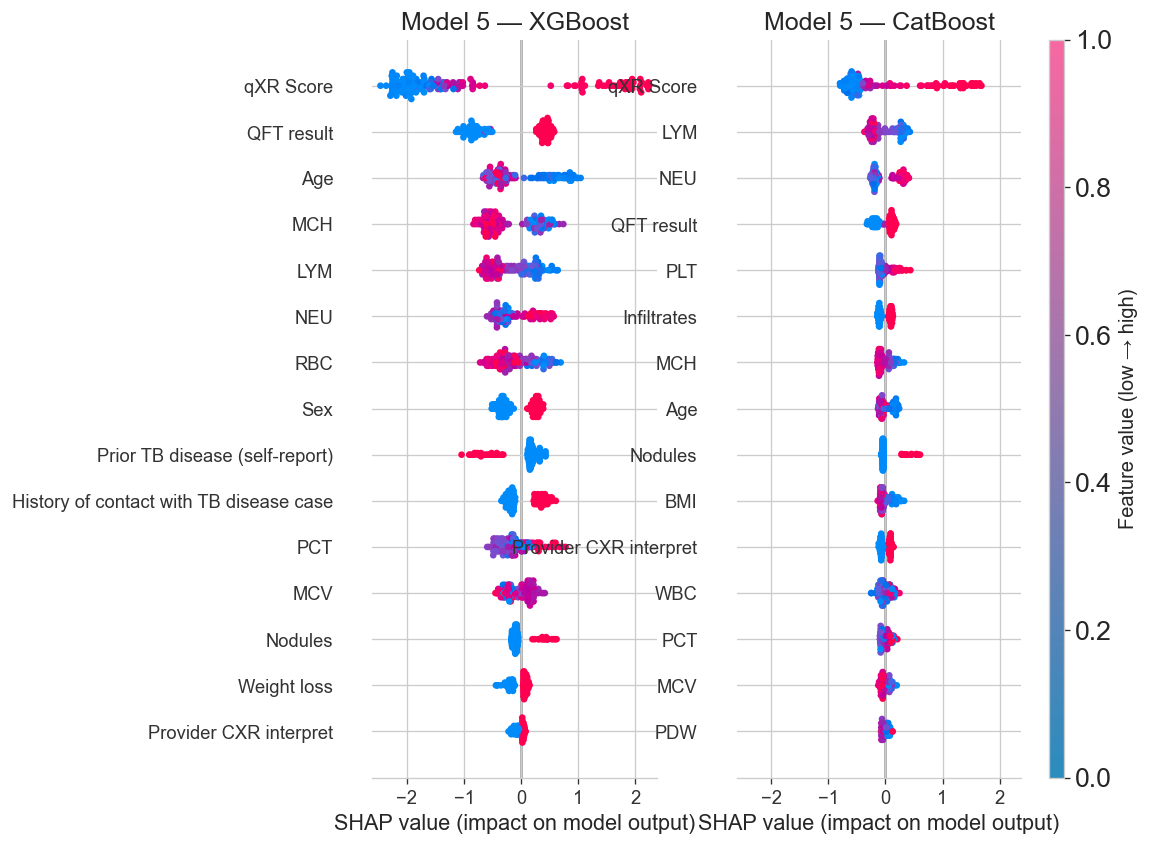

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_fig5_shap_beeswarm_model5_xgb_vs_cat_wide.png


In [18]:
# Variant without the numeric annotations (originally made for the Epi practicum)

# =============== 14) FIGURE 5: SHAP BEESWARMS (MODEL 5) ===============
# CHANGES:
#  - Removed all numeric annotations (abs and signed means)
#  - Dropped mean_abs/mean_signed computation (not needed anymore)
#  - Tightened x-limits and grid layout (no space needed for numbers)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec
from xgboost import DMatrix
from catboost import Pool
import shap  # pip install shap

# ---- Colormap ----
blue_purple_pink = LinearSegmentedColormap.from_list(
    "blue_purple_pink", ["#2b8cbe", "#9e77e5", "#f768a1"], N=256
)
blue_pink = LinearSegmentedColormap.from_list("blue_pink", ["#2b8cbe", "#f768a1"])

# ---- Grab Model 5 bundles (assumes final_models_xgb/cat exist from earlier steps) ----
bundle_xgb = final_models_xgb["Model 5"]
bundle_cat = final_models_cat["Model 5"]

# Exclude the random control feature if present
_rand = globals().get("RAND_NAME", None)
feats_xgb = [f for f in bundle_xgb["feats"] if (_rand is None or f != _rand)]
feats_cat = [f for f in bundle_cat["feats"] if (_rand is None or f != _rand)]

# Prepare test matrices (assumes feature_test and align_categoricals, CATS, rename_dict exist)
X5_raw_xgb = align_categoricals(feature_test[feats_xgb].copy())
X5_raw_cat = align_categoricals(feature_test[feats_cat].copy())

def to_numeric_for_coloring(X: pd.DataFrame) -> pd.DataFrame:
    import numpy as np, pandas as pd
    from pandas.api.types import is_object_dtype

    # optional: enforce desired orders so colors match intuition
    desired_orders = {
        "QFT_result_composite": ["Negative", "Indeterminate", "Positive"],
        "gender": ["Female", "Male"],  # Female=blue (low), Male=pink (high)
    }

    Xn = X.copy()
    for col in Xn.columns:
        s = Xn[col]
        # if categorical / object / declared CATS → treat as categorical
        is_cat = isinstance(s.dtype, pd.CategoricalDtype) or is_object_dtype(s) or (col in CATS)

        if is_cat:
            s = s.astype("category")
            # apply desired order if provided (and present)
            if col in desired_orders:
                cats = [c for c in desired_orders[col] if c in s.cat.categories]
                tail = [c for c in s.cat.categories if c not in cats and c != "__OTHER__"]
                s = s.cat.set_categories(cats + tail, ordered=True)

            cats = [c for c in s.cat.categories if c != "__OTHER__"]
            if len(cats) <= 1:
                Xn[col] = 0.0
                continue

            code_map = {c: i for i, c in enumerate(cats)}
            raw_codes = s.map(code_map)
            k = len(cats)
            anchors = np.linspace(0.0, 1.0, k)
            anchor_map = {i: anchors[i] for i in range(k)}
            Xn[col] = raw_codes.map(anchor_map).astype(float)
        else:
            Xn[col] = pd.to_numeric(s, errors="coerce")

    return Xn.rename(columns=rename_dict)

# Display frames (renamed for axis labels) + color frames (numeric)
X5_disp_xgb = X5_raw_xgb.rename(columns=rename_dict)
X5_disp_cat = X5_raw_cat.rename(columns=rename_dict)
X5_color_xgb = to_numeric_for_coloring(X5_raw_xgb)
X5_color_cat = to_numeric_for_coloring(X5_raw_cat)

# ---- Native SHAP extraction helpers ----
def xgb_shap_values_native(booster, X_df):
    d = DMatrix(align_categoricals(X_df), enable_categorical=True)
    contrib = booster.predict(d, pred_contribs=True)
    return np.asarray(contrib)[:, :X_df.shape[1]]  # drop bias term

def cat_shap_values_native(model, X_df):
    pool = Pool(align_categoricals(X_df), cat_features=[X_df.columns.get_loc(c) for c in CATS if c in X_df.columns])
    shap_vals = model.get_feature_importance(pool, type='ShapValues')
    return np.asarray(shap_vals)[:, :X_df.shape[1]]  # drop bias term

# ---- Compute SHAP values (Model 5) ----
sv5_xgb = xgb_shap_values_native(bundle_xgb["model"], X5_raw_xgb)
sv5_cat = cat_shap_values_native(bundle_cat["model"], X5_raw_cat)

# ---- Shared axis limits across panels (no extra right padding needed) ----
x_min_raw = float(min(np.nanmin(sv5_xgb), np.nanmin(sv5_cat)))
x_max_raw = float(max(np.nanmax(sv5_xgb), np.nanmax(sv5_cat)))
if not np.isfinite([x_min_raw, x_max_raw]).all():
    x_min_raw, x_max_raw = -1.0, 1.0
span = x_max_raw - x_min_raw if x_max_raw > x_min_raw else 1.0
shared_xlim = (x_min_raw - 0.03 * span, x_max_raw + 0.03 * span)  # symmetric, tighter

blue_pink_mapper = ScalarMappable(cmap=blue_pink); blue_pink_mapper.set_array([])

# ---- Figure layout (narrower right margin & colorbar) ----
fig = plt.figure(figsize=(24, 9.5), constrained_layout=False)
gs  = gridspec.GridSpec(1, 4, figure=fig, width_ratios=[1.15, 0.10, 1.15, 0.06], wspace=0.18)
ax1 = fig.add_subplot(gs[0, 0])   # XGB beeswarm
ax2 = fig.add_subplot(gs[0, 2])   # CAT beeswarm
cax = fig.add_subplot(gs[0, 3])   # colorbar

def beeswarm(ax, sv, X_color, title):
    plt.sca(ax)
    shap.summary_plot(
        sv, X_color,
        feature_names=list(X_color.columns),
        plot_type="dot", show=False,
        color=blue_pink, color_bar=False,
        max_display=20
    )
    ax = plt.gca()
    ax.set_title(title, fontsize=15)
    ax.set_xlim(*shared_xlim)
    ax.tick_params(axis="y", labelsize=11)
    return ax

ax1 = beeswarm(ax1, sv5_xgb, X5_color_xgb, "Model 5 — XGBoost")
ax2 = beeswarm(ax2, sv5_cat, X5_color_cat, "Model 5 — CatBoost")

# ---- Colorbar & final layout ----
cbar = fig.colorbar(blue_pink_mapper, cax=cax)
cbar.set_label("Feature value (low → high)", fontsize=12)

fig.subplots_adjust(left=0.26, right=0.98, bottom=0.10, top=0.92, wspace=0.18)

# ---- Save ----
out_path = f"{IMG_DIR}/rev_fig5_shap_beeswarm_model5_xgb_vs_cat_wide.png"
plt.savefig(out_path, dpi=220, bbox_inches="tight"); plt.show()
print("Saved:", out_path)


XGB splits on 'Score': n=165
CAT splits on 'Score': n=102


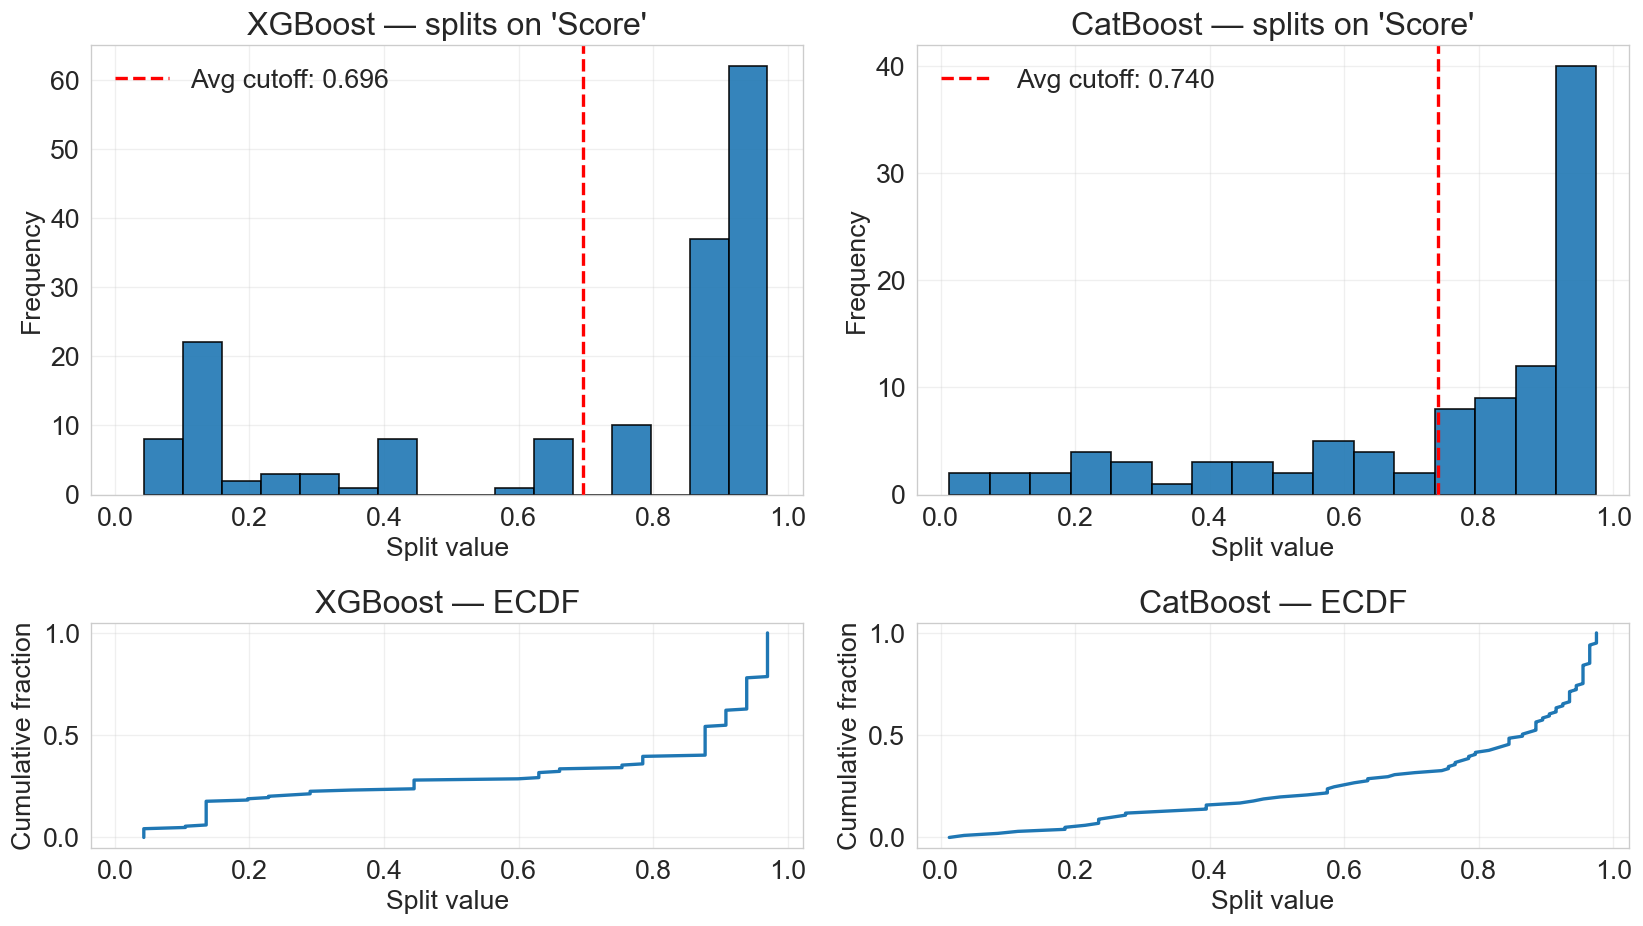

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_model5_score_split_dists_xgb_cat.png


In [19]:
# =============== 15) SPLIT THRESHOLDS FOR 'Score' (MODEL 5) ===============
xgb_model_for_m5 = final_models_xgb["Model 5"]["model"]
cat_model_for_m5 = final_models_cat["Model 5"]["model"]
xgb_feats_m5     = final_models_xgb["Model 5"]["feats"]
cat_feats_m5     = final_models_cat["Model 5"]["feats"]

feature_name = "Score"
if feature_name not in xgb_feats_m5 or feature_name not in cat_feats_m5:
    raise ValueError(f'"{feature_name}" must be in Model 5 feature lists.')

def xgb_split_values(booster, feat_name):
    try:
        hist = booster.get_split_value_histogram(feat_name, as_pandas=True)
        if isinstance(hist, pd.DataFrame) and not hist.empty:
            return np.repeat(hist["SplitValue"].to_numpy(), hist["Count"].astype(int).to_numpy()).astype(float)
    except Exception:
        pass
    try:
        df = booster.trees_to_dataframe()
        df = df[df["Feature"] == feat_name]
        return df["Split"].dropna().astype(float).to_numpy()
    except Exception:
        return np.array([])

def cat_split_values(model, feat_name, feat_list):
    if feat_name not in feat_list:
        return np.array([])
    local_idx = feat_list.index(feat_name)
    with tempfile.NamedTemporaryFile(delete=False, suffix=".json") as tmp:
        tmp_path = tmp.name
    try:
        model.save_model(tmp_path, format="json")
        with open(tmp_path, "r") as f:
            js = json.load(f)
    finally:
        try: os.remove(tmp_path)
        except Exception: pass

    float_infos = {}
    for ff in js.get("features_info", {}).get("float_features", []):
        idx = int(ff.get("index", ff.get("flat_feature_index", -1)))
        float_infos[idx] = {"feature_id": ff.get("feature_id"), "borders": ff.get("borders", [])}
    name_to_model_idx = {v.get("feature_id"): k for k, v in float_infos.items() if v.get("feature_id") is not None}
    model_float_idx = name_to_model_idx.get(feat_name, local_idx)

    splits = []
    for tree in js.get("oblivious_trees", []):
        for sp in tree.get("splits", []):
            if sp.get("split_type") == "FloatFeature" and int(sp.get("float_feature_index")) == model_float_idx:
                if "border" in sp:
                    try: splits.append(float(sp["border"]))
                    except Exception: pass
                elif "border_idx" in sp:
                    try:
                        bidx = int(sp["border_idx"])
                        borders = float_infos.get(model_float_idx, {}).get("borders", [])
                        if 0 <= bidx < len(borders):
                            splits.append(float(borders[bidx]))
                    except Exception: pass
    return np.array(splits, dtype=float)

xgb_vals = xgb_split_values(xgb_model_for_m5, feature_name)
cat_vals = cat_split_values(cat_model_for_m5, feature_name, cat_feats_m5)

print(f"XGB splits on '{feature_name}': n={len(xgb_vals)}")
print(f"CAT splits on '{feature_name}': n={len(cat_vals)}")

if len(xgb_vals)==0 and len(cat_vals)==0:
    raise RuntimeError(f"No splits on '{feature_name}' found in either model.")

def make_ecdf(x):
    x = np.sort(np.asarray(x, float)); y = np.linspace(0, 1, len(x), endpoint=True); return x, y

fig, axes = plt.subplots(2, 2, figsize=(14, 8), gridspec_kw={"height_ratios":[2,1]})
(ax_hx, ax_hc), (ax_ex, ax_ec) = axes

all_vals = np.concatenate([v for v in [xgb_vals, cat_vals] if len(v)])
lo, hi = float(np.min(all_vals)), float(np.max(all_vals)); span = max(hi - lo, 1e-9)
bins = max(10, min(50, int(np.sqrt(len(all_vals)))))

ax_hx.hist(xgb_vals, bins=bins, edgecolor="black", alpha=0.9)
if len(xgb_vals): ax_hx.axvline(np.average(xgb_vals), color="red", ls="--", lw=2, label=f"Avg cutoff: {np.average(xgb_vals):.3f}")
ax_hx.set_title(f"XGBoost — splits on '{feature_name}'"); ax_hx.set_xlabel("Split value"); ax_hx.set_ylabel("Frequency")
ax_hx.legend(loc="upper left", frameon=False)

ax_hc.hist(cat_vals, bins=bins, edgecolor="black", alpha=0.9)
if len(cat_vals): ax_hc.axvline(np.average(cat_vals), color="red", ls="--", lw=2, label=f"Avg cutoff: {np.average(cat_vals):.3f}")
ax_hc.set_title(f"CatBoost — splits on '{feature_name}'"); ax_hc.set_xlabel("Split value"); ax_hc.set_ylabel("Frequency")
ax_hc.legend(loc="upper left", frameon=False)

if len(xgb_vals): ex, ey = make_ecdf(xgb_vals); ax_ex.plot(ex, ey, lw=2)
if len(cat_vals): ec, fc = make_ecdf(cat_vals); ax_ec.plot(ec, fc, lw=2)

ax_ex.set_title("XGBoost — ECDF"); ax_ex.set_xlabel("Split value"); ax_ex.set_ylabel("Cumulative fraction")
ax_ec.set_title("CatBoost — ECDF"); ax_ec.set_xlabel("Split value"); ax_ec.set_ylabel("Cumulative fraction")

for ax in (ax_hx, ax_hc, ax_ex, ax_ec):
    ax.set_xlim(lo - 0.05*span, hi + 0.05*span); ax.grid(True, alpha=0.3)

out_png = f"{IMG_DIR}/rev_model5_score_split_dists_xgb_cat.png"
plt.tight_layout(); plt.savefig(out_png, dpi=200, bbox_inches="tight"); plt.show()
print("Saved:", out_png)


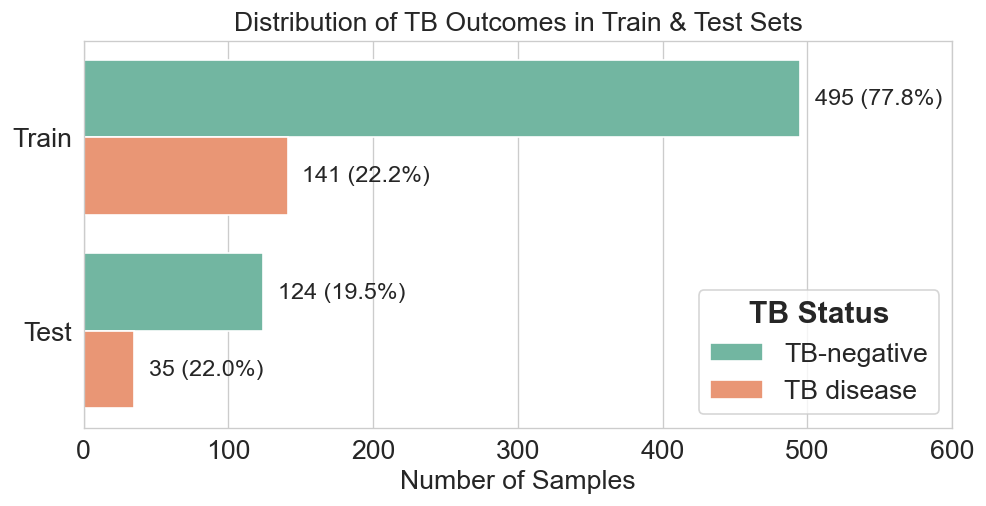

In [20]:
# =========================================
#Supplementary Figure 1
# =========================================

#Distribution of train and test sets
from matplotlib.font_manager import FontProperties

# Combine train and test sets
train_labels = pd.DataFrame({"Set": "Train", "Outcome": target_train})
test_labels = pd.DataFrame({"Set": "Test", "Outcome": target_test})
combined = pd.concat([train_labels, test_labels])

# Convert outcomes to categorical labels
label_map = {0: "TB-negative", 1: "TB disease"}  # [R1.5] was "ATB"
combined["Outcome"] = combined["Outcome"].map(label_map)

# Plot as horizontal bar chart
plt.figure(figsize=(8.5, 4.5))
ax = sns.countplot(data=combined, y="Set", hue="Outcome", palette="Set2", orient='h')

# Get counts per group
group_totals = combined.groupby("Set").size().to_dict()

# Annotate bars
for p in ax.patches:
    width = int(p.get_width())
    if width == 0:
        continue  # Skip zero-width bars

    y = p.get_y() + p.get_height() / 2
    set_label = ax.get_yticklabels()[int(y)].get_text()
    total = group_totals[set_label]
    pct = width / total * 100

    ax.annotate(f"{width} ({pct:.1f}%)", 
                (width + 10, y),  # Add more horizontal padding
                va='center',
                fontsize=14)

# Styling
plt.title("Distribution of TB Outcomes in Train & Test Sets", fontsize=16)
plt.xlabel("Number of Samples", fontsize=16)
plt.ylabel("")
plt.xlim(0, 600)  # Extend x-axis to avoid cutoff
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Bigger, clearer legend
plt.legend(
    title="TB Status", 
    title_fontproperties=FontProperties(weight='bold', size=18),
    fontsize=16)

plt.tight_layout()

# Save image
output_image_path = f"{IMG_DIR}/rev_train_test_distribution_horizontal.png"
plt.savefig(output_image_path, dpi=300, bbox_inches='tight')
plt.show()


  Set  Rows (main analysis)  Excluded: clinician-diagnosed only  Rows analysed  Bac-confirmed TB  No TB disease
Train                   636                                  11            625               130            495
 Test                   159                                   3            156                32            124
Total                   795                                  14            781               162            619
[Bac-confirmed only] train n=625 (TB=130) | test n=156 (TB=32) | SCALE_POS=3.808


Algorithm   Model                             Analysis  n_test  TB_test  n_feats                 Sens                 Spec                  PPV                  NPV                AUROC                   AP                Brier  Null Brier       Brier (recal.)    Thr
  XGBoost Model 1      Main analysis (all TB vs no TB)     159       35       10 0.571 (0.394, 0.737) 0.685 (0.596, 0.766) 0.339 (0.221, 0.474) 0.850 (0.765, 0.914) 0.629 (0.519, 0.740) 0.329 (0.224, 0.494) 0.239 (0.215, 0.264)       0.172 0.169 (0.134, 0.205) 0.5532
  XGBoost Model 1 Main models, bac-confirmed test rows     156       32       10 0.625 (0.437, 0.789) 0.685 (0.596, 0.766) 0.339 (0.221, 0.474) 0.876 (0.794, 0.934) 0.661 (0.547, 0.772) 0.334 (0.218, 0.506) 0.235 (0.211, 0.260)       0.163 0.157 (0.123, 0.191) 0.5532
  XGBoost Model 1       Re-run: bac-confirmed vs no TB     156       32       10 0.719 (0.533, 0.863) 0.629 (0.538, 0.714) 0.333 (0.224, 0.457) 0.897 (0.813, 0.952) 0.695 (0.582, 0.803) 0.380 (0.2

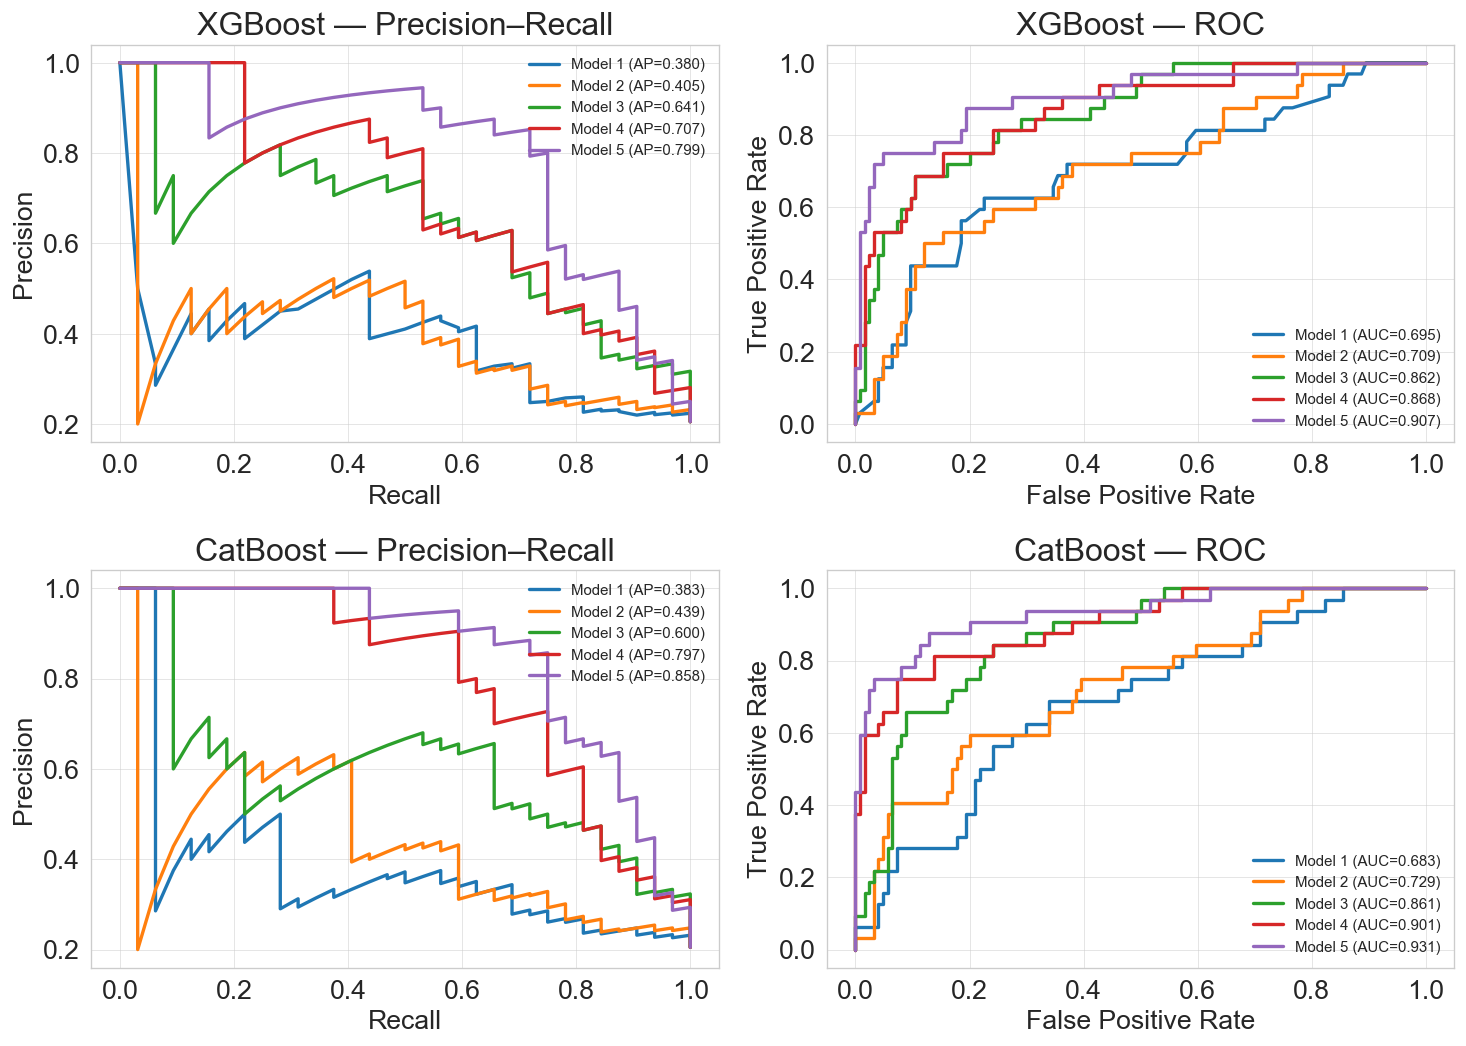

Saved bacteriologically-confirmed PR/ROC figure: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_fig_staged_PR_left_ROC_right_xgb_cat_bacteriologically_confirmed.png


In [21]:
# =============== 16) SENSITIVITY: BACTERIOLOGICALLY CONFIRMED TB ONLY ===============
# [R3.1] Outcome: bacteriologically confirmed TB (1) vs no TB disease (0). Provider-/clinician-diagnosed-only
# TB cases are EXCLUDED (not recoded as negative). The original train/test assignment is kept: excluded rows
# are dropped from whichever side they were on (no new split). Same pipeline and threshold rule as the main
# analysis: carry_forward_rfe -> M1–M5 fits -> spec>=TARGET_SPEC threshold from 5-fold train OOF -> test metrics
# with 95% CIs (test_ci). (Replaces the previous cell, which referenced undefined compute_metrics /
# THRESHOLD, mis-unpacked tune_cat_params_auc and re-split the data.)
detail      = df0["TB_status_detailed"].fillna("").astype(str)
is_bac      = detail == "ATB-bacteriologically confirmed"
is_clinonly = detail == "ATB-clinician diagnosed at baseline"
assert ((df0["TB_status"] == 1) == (is_bac | is_clinonly)).all(), "TB_status / TB_status_detailed mismatch"
keep_bac = ~is_clinonly
y_bac    = is_bac.astype(int)

tr_keep = keep_bac.loc[X_train_full.index].to_numpy()
te_keep = keep_bac.loc[X_test_full.index].to_numpy()
X_train_full_bac, y_train_full_bac = X_train_full[tr_keep], y_bac.loc[X_train_full.index][tr_keep]
X_test_full_bac,  y_test_full_bac  = X_test_full[te_keep],  y_bac.loc[X_test_full.index][te_keep]

bac_excl = pd.DataFrame([
    {"Set": name, "Rows (main analysis)": len(idx), "Excluded: clinician-diagnosed only": int((~k).sum()),
     "Rows analysed": int(k.sum()), "Bac-confirmed TB": int(y_bac.loc[idx][k].sum()),
     "No TB disease": int((y_bac.loc[idx][k] == 0).sum())}
    for name, idx, k in [("Train", X_train_full.index, tr_keep), ("Test", X_test_full.index, te_keep)]])
bac_excl.loc[len(bac_excl)] = ["Total"] + bac_excl.iloc[:, 1:].sum().tolist()
print(bac_excl.to_string(index=False))
bac_excl.to_csv(f"{CSV_DIR}/rev_bac_confirmed_exclusions.csv", index=False)

# =============== 17) RERUN STAGE-BASED MODEL SELECTION AND FITS FOR BACTERIOLOGICALLY-CONFIRMED ONLY ===============
bac_run = run_staged_pipeline("Bac-confirmed only", "bacteriologically_confirmed",
                              X_train_full_bac, y_train_full_bac, X_test_full_bac, y_test_full_bac)

# =============== 18) EVALUATE BACTERIOLOGICALLY-CONFIRMED MODELS AND SAVE TABLES/FIGURES ===============
y_te_main = y_test_full.to_numpy().astype(int)
y_te_bac  = y_test_full_bac.to_numpy().astype(int)
bac_rows = []
for algo in ["XGB", "CAT"]:
    for st in stage_new:
        main_ev, main_feats = MAIN_RUN[algo]["evals"][st], MAIN_RUN[algo]["models"][st]["feats"]
        bac_rows.append(eval_row(algo, st, "Main analysis (all TB vs no TB)", main_ev, y_te_main, main_feats))
        bac_rows.append(eval_row(algo, st, "Main models, bac-confirmed test rows", subset_eval(main_ev, te_keep, y_te_bac),
                                 y_te_bac, main_feats))
        bac_rows.append(eval_row(algo, st, "Re-run: bac-confirmed vs no TB", bac_run[algo]["evals"][st], y_te_bac,
                                 bac_run[algo]["models"][st]["feats"]))
bac_df = pd.DataFrame(bac_rows)
bac_df.to_csv(f"{CSV_DIR}/rev_bac_confirmed_sensitivity.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print(bac_df.drop(columns="Features").to_string(index=False))
print("\n=== Model 5 feature lists ===")
for _, r in bac_df[(bac_df["Model"] == "Model 5") & (bac_df["Analysis"] != "Main models, bac-confirmed test rows")].iterrows():
    print(f"{r['Algorithm']} — {r['Analysis']} ({r['n_feats']}): {r['Features']}")

# PR/ROC for bacteriologically-confirmed stage models
fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.0), sharex=False, sharey=False)
(ax_pr_xgb, ax_roc_xgb), (ax_pr_cat, ax_roc_cat) = axes
for st in stage_new.keys():
    for algo, ax_pr, ax_roc in [("XGB", ax_pr_xgb, ax_roc_xgb), ("CAT", ax_pr_cat, ax_roc_cat)]:
        p = bac_run[algo]["evals"][st]["p_test"]
        prec, rec, _ = precision_recall_curve(y_te_bac, p)
        ax_pr.plot(rec, prec, lw=2, label=f"{st} (AP={average_precision_score(y_te_bac, p):.3f})")
        fpr, tpr, _ = roc_curve(y_te_bac, p)
        ax_roc.plot(fpr, tpr, lw=2, label=f"{st} (AUC={roc_auc_score(y_te_bac, p):.3f})")
for ax, title in [(ax_pr_xgb, "XGBoost — Precision–Recall"), (ax_roc_xgb, "XGBoost — ROC"),
                  (ax_pr_cat, "CatBoost — Precision–Recall"), (ax_roc_cat, "CatBoost — ROC")]:
    ax.set_title(title)
    ax.grid(True, linewidth=0.5, alpha=0.6)
    ax.legend(frameon=False, fontsize=9)
ax_pr_xgb.set_xlabel("Recall"); ax_pr_xgb.set_ylabel("Precision")
ax_roc_xgb.set_xlabel("False Positive Rate"); ax_roc_xgb.set_ylabel("True Positive Rate")
ax_pr_cat.set_xlabel("Recall"); ax_pr_cat.set_ylabel("Precision")
ax_roc_cat.set_xlabel("False Positive Rate"); ax_roc_cat.set_ylabel("True Positive Rate")
plt.tight_layout()
out_path = f"{IMG_DIR}/rev_fig_staged_PR_left_ROC_right_xgb_cat_bacteriologically_confirmed.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight"); plt.show()
print("Saved bacteriologically-confirmed PR/ROC figure:", out_path)


## Part B — Revision analyses (new cells)
All cells reuse the Part A helpers: `stage_metrics_table` (train-OOF threshold + test-set 95% CIs: bootstrap for AUROC/AP/Brier, exact for Sens/Spec/PPV/NPV), `run_staged_pipeline` (RFE → M1–M5 → evaluation on any subset), `eval_row`, `subset_eval`.

# REV-0.3 Table 1, outcome composition and HIV prevalence
Analytic sample (n = 795): overall / TB disease / no TB disease; chi-square, or Fisher's exact when any expected count < 5 (Freeman–Halton for R × 2); t-tests for continuous variables.

In [22]:
# REV-0.3 Table 1 — analytic sample (n=795): overall, TB disease, no TB disease
from scipy.special import gammaln

T1_SECTIONS = OrderedDict([
    ("Patient characteristics", [("age", "cont"), ("gender", "cat"), ("race_collapsed", "cat"), ("bmi", "cont"),
                                 ("diabetes", "cat"), ("asthma", "cat"), ("bcg", "cat"),
                                 ("lived_with_another_tb", "cat"), ("tb_history_prior", "cat"),
                                 ("QFT_result_composite", "cat")]),
    ("Symptoms", [(v, "cat") for v in clinical_vars]),
    ("CXR findings (provider-interpreted)", [(v, "cat") for v in radiologist_interpret]),
    ("CXR (qXR)", [("Score", "cont")]),
    ("Blood values (CBC)", [(v, "cont") for v in blood_vars_continuous]),
])
t1_vars = [v for sec in T1_SECTIONS.values() for v, _ in sec]
assert sorted(t1_vars) == sorted(feature_train.columns), set(feature_train.columns) ^ set(t1_vars)

LEVEL_LABELS = {"idk": "Unknown", "no_diabetes": "No diabetes", "no_asthma": "No asthma"}
def _lvl(v):
    v = str(v)
    return LEVEL_LABELS.get(v, v[:1].upper() + v[1:].replace("_", " "))

def fisher_exact_rx2(ct):
    """Fisher–Freeman–Halton exact test for an R x 2 table (full enumeration over fixed margins)."""
    ct = np.asarray(ct, dtype=int)
    r = ct.sum(1); c0 = int(ct[:, 0].sum()); N = int(r.sum())
    def logp(x):
        return ((gammaln(r + 1) - gammaln(x + 1) - gammaln(r - x + 1)).sum(-1)
                - (gammaln(N + 1) - gammaln(c0 + 1) - gammaln(N - c0 + 1)))
    grids = np.meshgrid(*[np.arange(ri + 1) for ri in r[:-1]], indexing="ij")
    Xg = np.stack([g.ravel() for g in grids], 1)
    last = c0 - Xg.sum(1)
    ok = (last >= 0) & (last <= r[-1])
    Xg = np.column_stack([Xg[ok], last[ok]])
    lp, lp_obs = logp(Xg), logp(ct[:, 0][None, :])[0]
    return float(min(1.0, np.exp(lp[lp <= lp_obs + 1e-7]).sum()))

def cat_test(ct):
    _, p_chi, _, expected = chi2_contingency(ct, correction=False)
    if (expected >= 5).all():
        return p_chi, "Chi-square"
    if ct.shape == (2, 2):
        return fisher_exact(ct)[1], "Fisher's exact"
    return fisher_exact_rx2(ct), "Fisher's exact (Freeman–Halton)"

def fmt_p(p): return "<0.001" if p < 0.001 else f"{p:.3f}"

t1 = df0.copy()
grp = t1["TB_status"].astype(int)
N, n1, n0 = len(t1), int((grp == 1).sum()), int((grp == 0).sum())
col_all, col_tb, col_no = f"Overall (N={N})", f"TB disease (N={n1})", f"No TB disease (N={n0})"

rows = []
for section, vars_ in T1_SECTIONS.items():
    rows.append({"Variable": section})
    for v, kind in vars_:
        label = rename_dict.get(v, v)
        if kind == "cont":
            s = pd.to_numeric(t1[v]); a, b = s[grp == 1], s[grp == 0]
            _, p = ttest_ind(a, b, equal_var=True)
            d = 2 if abs(s.mean()) < 10 else 1  # [REV-0.8] 2 decimals for small-valued variables (PCT, qXR, RBC...)
            rows.append({"Variable": f"{label}, mean (SD)", "Level": "",
                         col_all: f"{s.mean():.{d}f} ({s.std(ddof=1):.{d}f})",
                         col_tb:  f"{a.mean():.{d}f} ({a.std(ddof=1):.{d}f})",
                         col_no:  f"{b.mean():.{d}f} ({b.std(ddof=1):.{d}f})",
                         "p-value": fmt_p(p), "Test": "t-test", "p_raw": p})
        else:
            ct = pd.crosstab(t1[v], grp).reindex(columns=[1, 0], fill_value=0)
            assert ct.to_numpy().sum() == N and ct[1].sum() == n1 and ct[0].sum() == n0
            p, test = cat_test(ct.to_numpy())
            for j, (lvl, cnt) in enumerate(ct.iterrows()):
                tot = int(cnt.sum())
                rows.append({"Variable": f"{label}, n (%)" if j == 0 else "", "Level": _lvl(lvl),
                             col_all: f"{tot} ({100*tot/N:.1f})",
                             col_tb:  f"{int(cnt[1])} ({100*cnt[1]/n1:.1f})",
                             col_no:  f"{int(cnt[0])} ({100*cnt[0]/n0:.1f})",
                             "p-value": fmt_p(p) if j == 0 else "", "Test": test if j == 0 else "",
                             "p_raw": p if j == 0 else np.nan})

table1 = pd.DataFrame(rows).fillna("")
table1.drop(columns="p_raw").to_csv(f"{CSV_DIR}/rev_table1_analytic_sample.csv", index=False)
with pd.option_context("display.width", 250, "display.max_rows", 200, "display.max_colwidth", 45):
    print(table1.drop(columns="p_raw").to_string(index=False))
print("Fisher's exact used for:", [r["Variable"] for r in rows if str(r.get("Test", "")).startswith("Fisher")])

# ---- Outcome composition within the analytic sample ----
outcome_detail = pd.crosstab(t1["TB_status_detailed"], grp.map({1: "TB disease", 0: "No TB disease"}),
                             margins=True, margins_name="Total")
print("\n=== TB_status_detailed within the analytic sample ===")
print(outcome_detail)
n_bac  = int((t1["TB_status_detailed"] == "ATB-bacteriologically confirmed").sum())
n_clin = int((t1["TB_status_detailed"] == "ATB-clinician diagnosed at baseline").sum())
print(f"TB disease: {n1} = {n_bac} bacteriologically confirmed ({100*n_bac/n1:.1f}%) "
      f"+ {n_clin} clinician-diagnosed only ({100*n_clin/n1:.1f}%)")
outcome_detail.to_csv(f"{CSV_DIR}/rev_outcome_detail_counts.csv")

# ---- HIV prevalence: numerator and denominator ----
hiv = pd.read_excel(master_tb_file, sheet_name="Dataset", usecols=["record_id", "hiv", "hiv_result"])
hiv = t1[["record_id", "TB_status"]].merge(hiv, on="record_id", how="left", validate="one_to_one")
print("\nhiv (test done) values:", hiv["hiv"].value_counts(dropna=False).to_dict())
print("hiv_result values:", hiv["hiv_result"].value_counts(dropna=False).to_dict())
tested = hiv["hiv_result"].isin(["Reactive", "Non-Reactive"])
n_tested, n_hiv = int(tested.sum()), int((hiv["hiv_result"] == "Reactive").sum())
print(f"HIV prevalence: {n_hiv}/{n_tested} = {100*n_hiv/n_tested:.2f}% "
      f"(denominator = analytic-sample participants with a Reactive/Non-Reactive result; analytic n={len(hiv)})")
hiv_by_tb = pd.crosstab(hiv["hiv_result"], hiv["TB_status"].map({1: "TB disease", 0: "No TB disease"}),
                        margins=True, margins_name="Total")
print(hiv_by_tb)
hiv_by_tb.to_csv(f"{CSV_DIR}/rev_hiv_counts.csv")


                                      Variable         Level Overall (N=795) TB disease (N=176) No TB disease (N=619) p-value                            Test
                       Patient characteristics                                                                                                               
                                Age, mean (SD)                   37.0 (17.3)        36.3 (17.4)           37.3 (17.3)   0.498                          t-test
                                    Sex, n (%)        Female      416 (52.3)          77 (43.8)            339 (54.8)   0.010                      Chi-square
                                                        Male      379 (47.7)          99 (56.2)            280 (45.2)                                        
                                   Race, n (%)         Asian      785 (98.7)         172 (97.7)            613 (99.0)   0.241                  Fisher's exact
                                                    


hiv (test done) values: {'Yes': 795}
hiv_result values: {'Non-Reactive': 788, 'Reactive': 7}
HIV prevalence: 7/795 = 0.88% (denominator = analytic-sample participants with a Reactive/Non-Reactive result; analytic n=795)
TB_status     No TB disease  TB disease  Total
hiv_result                                    
Non-Reactive            616         172    788
Reactive                  3           4      7
Total                   619         176    795


# REV-0.6 TB history: leakage check and original-composite sensitivity
The original `tb_history_composite` includes the chart-review item 'recently diagnosed with TB?', which encodes the outcome. Main models now use interview-only prior TB; this cell documents the leakage and re-runs M1–M5 with the original variable as a supplementary comparison.

In [23]:
# REV-0.6 TB history: leakage check and supplementary re-run with the original composite variable
# (1) Components of the ORIGINAL tb_history composite by TB status in the analytic sample (n=795).
master_hx = pd.read_excel(master_tb_file, sheet_name="Dataset",
                          usecols=["record_id", "tb_history_foreign_interview", "personal_history_tb_foreign_chart"])
hx = df0[["record_id", "TB_status"]].merge(master_hx, on="record_id", how="left", validate="one_to_one")
hx["original_composite"] = TB_HISTORY_ORIGINAL.to_numpy()
hx_grp = hx["TB_status"].map({1: "TB disease", 0: "No TB disease"})
tbh_leak = pd.concat({
    "Original composite (model input before revision)": pd.crosstab(hx["original_composite"], hx_grp),
    "Interview: ever had TB in the past? (model input now; Don't know -> No)": pd.crosstab(hx["tb_history_foreign_interview"], hx_grp),
    "Chart review: recently diagnosed with TB?": pd.crosstab(hx["personal_history_tb_foreign_chart"].fillna("Missing"), hx_grp),
}, names=["Item", "Response"])
print(tbh_leak)
tbh_leak.to_csv(f"{CSV_DIR}/rev_tbhistory_leakage_check.csv")

# (2) Supplementary: re-run RFE + M1–M5 with the original composite in place of interview-only prior TB.
# Same column name and levels (Yes/No), so the pipeline and category maps are unchanged; only the values differ.
X_tr_orig, X_te_orig = X_train_full.copy(), X_test_full.copy()
X_tr_orig["tb_history_prior"] = TB_HISTORY_ORIGINAL.loc[X_tr_orig.index].astype(str)
X_te_orig["tb_history_prior"] = TB_HISTORY_ORIGINAL.loc[X_te_orig.index].astype(str)
orig_run = run_staged_pipeline("TB history: original composite", "tbhistory_original_composite",
                               X_tr_orig, y_train_full, X_te_orig, y_test_full)

lbl_now, lbl_orig = rename_dict["tb_history_prior"], "TB history (original composite, incl. chart review)"
tbh_rows = []
for algo in ["XGB", "CAT"]:
    for st in stage_new:
        tbh_rows.append(eval_row(algo, st, "Main: interview-only prior TB", MAIN_RUN[algo]["evals"][st], y_te_main,
                                 MAIN_RUN[algo]["models"][st]["feats"]))
        r = eval_row(algo, st, "Supplementary: original composite", orig_run[algo]["evals"][st], y_te_main,
                     orig_run[algo]["models"][st]["feats"])
        r["Features"] = r["Features"].replace(lbl_now, lbl_orig)
        tbh_rows.append(r)
tbh_df = pd.DataFrame(tbh_rows)
tbh_df.to_csv(f"{CSV_DIR}/rev_tbhistory_original_composite_sensitivity.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print(tbh_df.drop(columns="Features").to_string(index=False))


TB_status                                                      No TB disease  \
Item                                               Response                    
Original composite (model input before revision)   No                    480   
                                                   Yes                   139   
Interview: ever had TB in the past? (model inpu... Don't know              1   
                                                   No                    479   
                                                   Yes                   139   
Chart review: recently diagnosed with TB?          Don't know             19   
                                                   Missing                 4   
                                                   No                    596   
                                                   Yes                     0   

TB_status                                                      TB disease  
Item                                       

Algorithm   Model                          Analysis  n_test  TB_test  n_feats                 Sens                 Spec                  PPV                  NPV                AUROC                   AP                Brier  Null Brier       Brier (recal.)    Thr
  XGBoost Model 1     Main: interview-only prior TB     159       35       10 0.571 (0.394, 0.737) 0.685 (0.596, 0.766) 0.339 (0.221, 0.474) 0.850 (0.765, 0.914) 0.629 (0.519, 0.740) 0.329 (0.224, 0.494) 0.239 (0.215, 0.264)       0.172 0.169 (0.134, 0.205) 0.5532
  XGBoost Model 1 Supplementary: original composite     159       35       10 0.686 (0.507, 0.831) 0.839 (0.762, 0.899) 0.545 (0.388, 0.696) 0.904 (0.835, 0.951) 0.806 (0.720, 0.882) 0.530 (0.370, 0.695) 0.142 (0.111, 0.173)       0.172 0.135 (0.100, 0.173) 0.2028
  XGBoost Model 2     Main: interview-only prior TB     159       35       15 0.600 (0.421, 0.761) 0.677 (0.588, 0.759) 0.344 (0.227, 0.477) 0.857 (0.772, 0.920) 0.663 (0.550, 0.773) 0.391 (0.258, 0.562) 0

# R1.4 Apparent vs cross-validated vs held-out test performance
Full-feature model (no noise column) and M1–M5 per algorithm; paired bootstrap tests of test-set ROC-AUC (full-feature vs M5; XGBoost vs CatBoost at M5).

In [24]:
# R1.4 Apparent vs cross-validated vs held-out test performance (full-feature model + M1–M5)
# Full-feature model: same recipe as M1–M5 — AUC-tuned on all 636 training rows (the cell 6 tuning,
# seed 42), refit WITHOUT the noise column, threshold from 5-fold train OOF with fixed params.
# Settings: Apparent = refit on all 636 train rows, scored on the same rows;
#           CV       = 5-fold OOF within train with the model's tuned params (all models), plus the
#                      existing nested-CV OOF for the full-feature model (per-fold thresholds, as Table 2);
#           Test     = 159 held-out rows, 2,000-bootstrap 95% CI. One threshold per model throughout.
full_feats = list(X_train_full.columns)
assert RAND_NAME not in full_feats

xgb_full_params = dict(xgb_params_final); xgb_full_params.setdefault("verbosity", 0)
booster_full = xgb_train(xgb_full_params,
                         DMatrix(align_categoricals(X_train_full[full_feats]), label=y_train_full, enable_categorical=True),
                         num_boost_round=xgb_rounds, verbose_eval=False)
cat_full_params = _clean_cat_verbose(cat_params_final)
Xt_full = align_categoricals(X_train_full[full_feats])
cat_full = CatBoostClassifier(**cat_full_params)
cat_full.fit(Pool(Xt_full, y_train_full, cat_features=[Xt_full.columns.get_loc(c) for c in CATS if c in Xt_full.columns] or None))

full_bundles = {
    "XGB": {"model": booster_full, "feats": full_feats, "params": xgb_full_params, "rounds": xgb_rounds},
    "CAT": {"model": cat_full, "feats": full_feats, "params": cat_full_params},
}
log_weighting("Full-feature refit (no noise)", "XGB", xgb_full_params)
log_weighting("Full-feature refit (no noise)", "CAT", cat_full_params)

_, _, full_eval_xgb = stage_metrics_table("XGB", OrderedDict([("Full-feature", full_bundles["XGB"])]),
                                          X_train_full, y_train_full, X_test_full, y_test_full)
_, _, full_eval_cat = stage_metrics_table("CAT", OrderedDict([("Full-feature", full_bundles["CAT"])]),
                                          X_train_full, y_train_full, X_test_full, y_test_full)

y_tr_arr, y_te_arr = y_train_full.to_numpy().astype(int), y_test_full.to_numpy().astype(int)
r14_rows = []
for algo, models, evals, full_eval, oof_nested in [
        ("XGB", final_models_xgb, stage_eval_xgb, full_eval_xgb, oof_xgb),
        ("CAT", final_models_cat, stage_eval_cat, full_eval_cat, oof_cat)]:
    bundles = OrderedDict([("Full-feature", full_bundles[algo])] + list(models.items()))
    evals = OrderedDict([("Full-feature", full_eval["Full-feature"])] + list(evals.items()))
    for st, bundle in bundles.items():
        ev, thr = evals[st], evals[st]["thr"]
        base = dict(Algorithm=ALGO_NAME[algo], Model=st, n_feats=len(bundle["feats"]))
        app = metrics_at_thr(y_tr_arr, stage_test_probs(algo, bundle, X_train_full), thr)
        r14_rows.append({**base, "Setting": "Apparent (train, n=636)", "Thr": thr, **app})
        r14_rows.append({**base, "Setting": "CV: 5-fold OOF, fixed params (train)", "Thr": thr,
                         **metrics_at_thr(y_tr_arr, ev["oof"], thr)})
        if st == "Full-feature":
            yn, pn, fn, tm = oof_nested["y_true"], oof_nested["probs"], oof_nested["fold_ids"], oof_nested["fold_thresholds"]
            sens, spec, ppv, npv = pooled_metrics(yn, pn, fn, tm)
            r14_rows.append({**base, "Setting": "CV: nested-CV OOF (train; per-fold thr)", "Thr": np.nan,
                             "Sens": sens, "Spec": spec, "PPV": ppv, "NPV": npv,
                             "AUROC": roc_auc_score(yn, pn), "AP": average_precision_score(yn, pn),
                             "Brier": brier_score_loss(yn, pn)})
        r14_rows.append({**base, "Setting": "Held-out test (n=159)", "Thr": thr, **ev["point"],
                         "Null Brier": ev["null_brier"], "Brier (recal.)": fmt_brier_cal(ev),
                         **{f"{k}_lo": ev["ci"][k][0] for k in METRIC_KEYS},
                         **{f"{k}_hi": ev["ci"][k][1] for k in METRIC_KEYS}})

r14 = pd.DataFrame(r14_rows)
r14.to_csv(f"{CSV_DIR}/rev_train_cv_test_metrics_numeric.csv", index=False)

def _fmt_cell(row, k):
    if pd.notna(row.get(f"{k}_lo", np.nan)):
        return f"{row[k]:.3f} ({row[f'{k}_lo']:.3f}, {row[f'{k}_hi']:.3f})"
    return f"{row[k]:.3f}"
r14_fmt = r14[["Algorithm", "Model", "n_feats", "Setting"]].copy()
for k in METRIC_KEYS:
    r14_fmt[k] = r14.apply(lambda row: _fmt_cell(row, k), axis=1)
r14_fmt["Null Brier"] = r14["Null Brier"].map(lambda v: "" if pd.isna(v) else f"{v:.3f}")
r14_fmt["Brier (recal.)"] = r14["Brier (recal.)"].fillna("")
r14_fmt["Thr"] = r14["Thr"].map(lambda t: "per fold" if pd.isna(t) else f"{t:.4f}")
r14_fmt.to_csv(f"{CSV_DIR}/rev_train_cv_test_metrics.csv", index=False)

# ---- Paired bootstrap tests of test-set ROC-AUC differences (same resampled rows for both models) ----
def paired_bootstrap_auc(y, p1, p2, B=N_BOOT, seed=BOOT_SEED):
    y = np.asarray(y).astype(int); p1 = as_proba(p1); p2 = as_proba(p2)
    rng = np.random.default_rng(seed); n = len(y); d = []
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        if y[idx].min() == y[idx].max():
            continue
        d.append(roc_auc_score(y[idx], p1[idx]) - roc_auc_score(y[idx], p2[idx]))
    d = np.asarray(d)
    p = max(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean())), 1.0 / len(d))  # two-sided percentile p
    return roc_auc_score(y, p1) - roc_auc_score(y, p2), np.percentile(d, 2.5), np.percentile(d, 97.5), p, len(d)

comparisons = [
    ("XGBoost: Full-feature vs Model 5", full_eval_xgb["Full-feature"]["p_test"], stage_eval_xgb["Model 5"]["p_test"]),
    ("CatBoost: Full-feature vs Model 5", full_eval_cat["Full-feature"]["p_test"], stage_eval_cat["Model 5"]["p_test"]),
    ("Model 5: XGBoost vs CatBoost", stage_eval_xgb["Model 5"]["p_test"], stage_eval_cat["Model 5"]["p_test"]),
]
auc_tests = []
for label, pa, pb in comparisons:
    diff, lo, hi, p, n_ok = paired_bootstrap_auc(y_te_arr, pa, pb)
    auc_tests.append({"Comparison (A vs B)": label,
                      "AUC A": round(roc_auc_score(y_te_arr, pa), 3), "AUC B": round(roc_auc_score(y_te_arr, pb), 3),
                      "ΔAUC (A−B)": f"{diff:+.3f} ({lo:+.3f}, {hi:+.3f})",
                      "p (paired bootstrap)": "<0.001" if p < 0.001 else f"{p:.3f}", "B used": n_ok})
auc_tests = pd.DataFrame(auc_tests)
auc_tests.to_csv(f"{CSV_DIR}/rev_paired_bootstrap_auc_tests.csv", index=False)

with pd.option_context("display.width", 260, "display.max_columns", 20, "display.max_rows", 100):
    print(f"=== R1.4 Apparent vs CV vs held-out test (spec>={TARGET_SPEC:.2f} threshold from train OOF) ===")
    print(r14_fmt.to_string(index=False))
    print("\n=== Paired bootstrap ROC-AUC tests (test set, B=2,000) ===")
    print(auc_tests.to_string(index=False))


=== R1.4 Apparent vs CV vs held-out test (spec>=0.70 threshold from train OOF) ===
Algorithm        Model  n_feats                                 Setting                 Sens                 Spec                  PPV                  NPV                AUROC                   AP                Brier Null Brier       Brier (recal.)      Thr
  XGBoost Full-feature       40                 Apparent (train, n=636)                0.972                0.747                0.523                0.989                0.967                0.912                0.061                                   0.1098
  XGBoost Full-feature       40    CV: 5-fold OOF, fixed params (train)                0.901                0.715                0.474                0.962                0.905                0.783                0.092                                   0.1098
  XGBoost Full-feature       40 CV: nested-CV OOF (train; per-fold thr)                0.844                0.760                0.500   

# REV-0.7 Probability diagnostics
Trees used, spread of predicted probabilities, Brier vs the no-skill Brier, calibration intercept/slope for the full-feature model and M1–M5. Diagnostic only.

In [25]:
# REV-0.7 Probability diagnostics: why some Brier scores are no better than the no-skill reference
# For every main model (full-feature + M1–M5): number of trees actually used, spread of test-set predicted
# probabilities, Brier vs the no-skill Brier (training prevalence for everyone), calibration intercept/slope.
# Diagnostic only — no model is changed here.
diag_rows = []
for algo, full_eval, st_eval, models in [("XGB", full_eval_xgb, stage_eval_xgb, final_models_xgb),
                                         ("CAT", full_eval_cat, stage_eval_cat, final_models_cat)]:
    entries = [("Full-feature", full_bundles[algo], full_eval["Full-feature"])] + \
              [(st, models[st], st_eval[st]) for st in models]
    for name, bundle, ev in entries:
        p = as_proba(ev["p_test"])
        a, b = calibration_intercept_slope(y_test_full, p)
        params = bundle["params"]
        weight = (params.get("scale_pos_weight", 1.0) if algo == "XGB"
                  else (params.get("class_weights") or [1.0, 1.0])[1])
        diag_rows.append({"Algorithm": ALGO_NAME[algo], "Model": name, "Trees": n_trees(algo, bundle),
                          "Learning rate": round(float(params.get("learning_rate", np.nan)), 3),
                          "Positive-class weight": round(float(weight), 3),
                          "Pred min": round(float(p.min()), 3), "Pred median": round(float(np.median(p)), 3),
                          "Pred max": round(float(p.max()), 3), "Pred SD": round(float(p.std()), 3),
                          "Brier": round(ev["point"]["Brier"], 3), "Null Brier": round(ev["null_brier"], 3),
                          "Brier skill": round(1 - ev["point"]["Brier"] / ev["null_brier"], 3),
                          "Calib intercept": round(a, 3), "Calib slope": round(b, 3),
                          # [REV-0.9] after the training-OOF recalibration
                          "Recal. slope (train OOF)": round(ev["platt"][1], 3),
                          "Brier (recal.)": round(ev["brier_cal"], 3),
                          "Brier skill (recal.)": round(1 - ev["brier_cal"] / ev["null_brier"], 3),
                          "Calib slope (recal.)": round(calibration_intercept_slope(y_test_full, ev["p_test_cal"])[1], 3)})
diag_df = pd.DataFrame(diag_rows)
diag_df.to_csv(f"{CSV_DIR}/rev_probability_diagnostics.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print("=== Probability diagnostics (test n=159). Brier skill = 1 - Brier/Null Brier; <= 0 means no better than "
          "predicting the training prevalence ===")
    print(diag_df.to_string(index=False))
for col, label in [("Brier skill", "raw probabilities"), ("Brier skill (recal.)", "after training-OOF recalibration")]:
    no_skill = diag_df[diag_df[col] <= 0]
    print(f"\nModels with Brier no better than the no-skill reference ({label}):",
          "none" if no_skill.empty else ", ".join(f"{r.Algorithm} {r.Model}" for r in no_skill.itertuples()))
bad_slope = diag_df[diag_df["Recal. slope (train OOF)"] <= 0]
if not bad_slope.empty:
    print("WARNING: non-positive recalibration slope (ranking reversed by recalibration) for:",
          ", ".join(f"{r.Algorithm} {r.Model}" for r in bad_slope.itertuples()))


=== Probability diagnostics (test n=159). Brier skill = 1 - Brier/Null Brier; <= 0 means no better than predicting the training prevalence ===
Algorithm        Model  Trees  Learning rate  Positive-class weight  Pred min  Pred median  Pred max  Pred SD  Brier  Null Brier  Brier skill  Calib intercept  Calib slope  Recal. slope (train OOF)  Brier (recal.)  Brier skill (recal.)  Calib slope (recal.)
  XGBoost Full-feature     62          0.093                  1.000     0.017        0.070     0.881    0.269  0.086       0.172        0.498            0.102        1.155                     1.130           0.086                 0.498                 1.022
  XGBoost      Model 1     32          0.053                  4.012     0.176        0.502     0.759    0.170  0.239       0.172       -0.394           -1.272        0.581                     1.213           0.169                 0.013                 0.479
  XGBoost      Model 2    138          0.063                  5.053     0.086      

# REV-1.1 Operating points across specificity targets; WHO triage TPP check
Test-set sensitivity/specificity (exact CIs) at each specificity target for the full-feature and M5 models (fixed fitted models, thresholds from training OOF); whether M5 meets sensitivity ≥ 0.90 with specificity ≥ 0.70.

In [26]:
# REV-1.1 Test-set operating points across specificity targets (full-feature + M5) and WHO triage TPP check
# Fixed fitted models (no refit). For each target t in SPEC_TARGETS: threshold = maximum sensitivity subject to
# specificity >= t on the pooled 5-fold OOF TRAINING predictions (threshold_at_spec; highest-specificity point if
# none qualifies), applied unchanged to the 159 test rows. Sens/Spec with exact Clopper–Pearson 95% CIs.
y_tr_arr, y_te_arr = y_train_full.to_numpy().astype(int), y_test_full.to_numpy().astype(int)
op_models = OrderedDict()
for algo, full_eval, st_eval in [("XGB", full_eval_xgb, stage_eval_xgb), ("CAT", full_eval_cat, stage_eval_cat)]:
    op_models[(algo, "Full-feature")] = full_eval["Full-feature"]
    op_models[(algo, "Model 5")] = st_eval["Model 5"]

sweep_rows = []
for (algo, name), ev in op_models.items():
    for t in SPEC_TARGETS:
        thr, oof_sens, oof_spec = threshold_at_spec(y_tr_arr, ev["oof"], t)
        if np.isclose(t, TARGET_SPEC):
            assert np.isclose(thr, ev["thr"]), "primary-target threshold differs from the main tables"
        tn, fp, fn, tp = confusion_matrix(y_te_arr, (ev["p_test"] >= thr).astype(int), labels=[0, 1]).ravel()
        (se_lo, se_hi), (sp_lo, sp_hi) = clopper_pearson(tp, tp + fn), clopper_pearson(tn, tn + fp)
        sweep_rows.append({"Algorithm": ALGO_NAME[algo], "Model": name, "Specificity target": t,
                           "Threshold": round(thr, 4), "Train OOF Sens": round(oof_sens, 3), "Train OOF Spec": round(oof_spec, 3),
                           "Test Sens": round(tp / (tp + fn), 3), "Sens CI lo": round(se_lo, 3), "Sens CI hi": round(se_hi, 3),
                           "Test Spec": round(tn / (tn + fp), 3), "Spec CI lo": round(sp_lo, 3), "Spec CI hi": round(sp_hi, 3),
                           "TP": int(tp), "FN": int(fn), "TN": int(tn), "FP": int(fp)})
sweep_df = pd.DataFrame(sweep_rows)
sweep_df.to_csv(f"{CSV_DIR}/rev_test_sens_spec_by_spec_target_fullfeature_M5.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print("=== Test-set sensitivity / specificity by specificity target (threshold from training OOF) ===")
    print(sweep_df.to_string(index=False))

# ---- WHO triage target product profile: sensitivity >= 0.90 and specificity >= 0.70 (M5, primary threshold) ----
TPP_SENS, TPP_SPEC = 0.90, 0.70
tpp_rows = []
for algo in ["XGB", "CAT"]:
    ev = op_models[(algo, "Model 5")]
    pt, ci = ev["point"], ev["ci"]
    tpp_rows.append({"Algorithm": ALGO_NAME[algo], "Model": "Model 5", "Threshold": round(ev["thr"], 4),
                     "Sens (95% CI)": f"{pt['Sens']:.3f} ({ci['Sens'][0]:.3f}, {ci['Sens'][1]:.3f})",
                     "Spec (95% CI)": f"{pt['Spec']:.3f} ({ci['Spec'][0]:.3f}, {ci['Spec'][1]:.3f})",
                     "Meets TPP (point estimates)": bool(pt["Sens"] >= TPP_SENS and pt["Spec"] >= TPP_SPEC),
                     "Meets TPP (lower 95% bounds)": bool(ci["Sens"][0] >= TPP_SENS and ci["Spec"][0] >= TPP_SPEC),
                     "TPP within 95% CIs": bool(ci["Sens"][1] >= TPP_SENS and ci["Spec"][1] >= TPP_SPEC)})
tpp_df = pd.DataFrame(tpp_rows)
tpp_df.to_csv(f"{CSV_DIR}/rev_who_tpp_check_M5.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print(f"\n=== WHO triage TPP (sens >= {TPP_SENS:.2f}, spec >= {TPP_SPEC:.2f}) — M5, test n={len(y_te_arr)} ===")
    print(tpp_df.to_string(index=False))


=== Test-set sensitivity / specificity by specificity target (threshold from training OOF) ===
Algorithm        Model  Specificity target  Threshold  Train OOF Sens  Train OOF Spec  Test Sens  Sens CI lo  Sens CI hi  Test Spec  Spec CI lo  Spec CI hi  TP  FN  TN  FP
  XGBoost Full-feature                0.70     0.1098           0.901           0.715      0.914       0.769       0.982      0.734       0.647       0.809  32   3  91  33
  XGBoost Full-feature                0.75     0.1354           0.887           0.762      0.914       0.769       0.982      0.798       0.717       0.865  32   3  99  25
  XGBoost Full-feature                0.80     0.1710           0.844           0.800      0.829       0.664       0.934      0.847       0.771       0.905  29   6 105  19
  XGBoost Full-feature                0.85     0.2229           0.809           0.853      0.743       0.567       0.875      0.871       0.799       0.924  26   9 108  16
  XGBoost Full-feature                0.90   

# R1.2a Top-10 / top-15 models
One-step ranking of all 40 candidate features by training-set OOF mean |SHAP| (not the test-set permutation importance).

In [27]:
# R1.2a Top-10 / top-15 models from a one-step SHAP ranking (training set only)
# All 40 candidate features (no noise column) ranked in ONE step by OOF mean |SHAP| within train
# (oof_mean_abs_shap, the function carry_forward_rfe uses), separately per algorithm. The test-set
# permutation-importance ranking is NOT used. Top-k models: tune_*_params_auc on train, refit on all
# 636 rows, threshold from 5-fold train OOF at spec >= TARGET_SPEC, test metrics with 95% CIs (test_ci).
TOPK = [15, 10]
topk_rankings, topk_models = {}, {}
for algo in ["XGB", "CAT"]:
    ranking = oof_mean_abs_shap(algo, X_train_full, y_train_full, full_feats).sort_values(ascending=False)
    topk_rankings[algo] = ranking
    pd.DataFrame({"Rank": np.arange(1, len(ranking) + 1), "Feature": ranking.index,
                  "Display": [rename_dict.get(f, f) for f in ranking.index], "OOF_mean_abs_SHAP": ranking.values}
                 ).to_csv(f"{CSV_DIR}/rev_topk_shap_ranking_{algo}.csv", index=False)
    bundles = OrderedDict()
    for k in TOPK:
        feats = list(ranking.index[:k])
        if algo == "XGB":
            booster, params, rounds = fit_final_xgb_for_fig(feats)
            bundles[f"Top-{k}"] = {"model": booster, "feats": feats, "params": params, "rounds": rounds}
        else:
            model, params = fit_final_cat_for_fig(feats)
            bundles[f"Top-{k}"] = {"model": model, "feats": feats, "params": params}
        log_weighting(f"Top-{k} model", algo, params)
    topk_models[algo] = bundles

_, _, topk_eval_xgb = stage_metrics_table("XGB", topk_models["XGB"], X_train_full, y_train_full, X_test_full, y_test_full)
_, _, topk_eval_cat = stage_metrics_table("CAT", topk_models["CAT"], X_train_full, y_train_full, X_test_full, y_test_full)

def _feat_list(feats):
    return "; ".join(rename_dict.get(f, f) for f in feats)

topk_rows = []
for algo, full_eval, topk_eval, st_eval, st_models in [
        ("XGB", full_eval_xgb, topk_eval_xgb, stage_eval_xgb, final_models_xgb),
        ("CAT", full_eval_cat, topk_eval_cat, stage_eval_cat, final_models_cat)]:
    entries = [("Full-feature", full_eval["Full-feature"], full_feats, "All 40 candidate features"),
               ("Top-15", topk_eval["Top-15"], topk_models[algo]["Top-15"]["feats"], None),
               ("Top-10", topk_eval["Top-10"], topk_models[algo]["Top-10"]["feats"], None),
               ("Model 5", st_eval["Model 5"], st_models["Model 5"]["feats"], None)]
    for name, ev, feats, feat_text in entries:
        topk_rows.append({"Algorithm": ALGO_NAME[algo], "Model": name, "n_feats": len(feats),
                          **{k: f"{ev['point'][k]:.3f} ({ev['ci'][k][0]:.3f}, {ev['ci'][k][1]:.3f})" for k in METRIC_KEYS},
                          "Null Brier": round(ev["null_brier"], 3), "Brier (recal.)": fmt_brier_cal(ev),
                          "Thr": round(ev["thr"], 4), "Selected features": feat_text or _feat_list(feats)})
topk_df = pd.DataFrame(topk_rows)
topk_df.to_csv(f"{CSV_DIR}/rev_topk_models.csv", index=False)

with pd.option_context("display.width", 260, "display.max_columns", 20, "display.max_colwidth", 60):
    print(f"=== R1.2a Full-feature vs top-15 vs top-10 vs M5 (test n={len(y_test_full)}, 95% bootstrap CI) ===")
    print(topk_df.drop(columns="Selected features").to_string(index=False))
    print("\n=== Selected features ===")
    for _, r in topk_df[topk_df["Model"] != "Full-feature"].iterrows():
        print(f"{r['Algorithm']} {r['Model']}: {r['Selected features']}")
    for algo in ["XGB", "CAT"]:
        m5 = set(final_models_xgb["Model 5"]["feats"] if algo == "XGB" else final_models_cat["Model 5"]["feats"])
        t15 = set(topk_models[algo]["Top-15"]["feats"])
        print(f"{ALGO_NAME[algo]}: Top-15 ∩ M5 = {len(t15 & m5)}/15 features")


=== R1.2a Full-feature vs top-15 vs top-10 vs M5 (test n=159, 95% bootstrap CI) ===
Algorithm        Model  n_feats                 Sens                 Spec                  PPV                  NPV                AUROC                   AP                Brier  Null Brier       Brier (recal.)    Thr
  XGBoost Full-feature       40 0.914 (0.769, 0.982) 0.734 (0.647, 0.809) 0.492 (0.366, 0.619) 0.968 (0.910, 0.993) 0.917 (0.856, 0.964) 0.817 (0.681, 0.911) 0.086 (0.057, 0.120)       0.172 0.086 (0.056, 0.122) 0.1098
  XGBoost       Top-15       15 0.886 (0.733, 0.968) 0.718 (0.630, 0.795) 0.470 (0.346, 0.597) 0.957 (0.894, 0.988) 0.901 (0.839, 0.951) 0.776 (0.626, 0.889) 0.113 (0.081, 0.149)       0.172 0.095 (0.065, 0.132) 0.2232
  XGBoost       Top-10       10 0.886 (0.733, 0.968) 0.750 (0.664, 0.823) 0.500 (0.370, 0.630) 0.959 (0.898, 0.989) 0.903 (0.839, 0.954) 0.798 (0.665, 0.897) 0.102 (0.071, 0.137)       0.172 0.093 (0.061, 0.129) 0.1614
  XGBoost      Model 5       15 0.800 (0

# R1.2b QFT result and TB history
Training-set association; M5 XGBoost refit without TB history; household-contact variable in M5.

In [28]:
# R1.2b QFT result vs TB history: association (train) and effect of dropping TB history from M5 XGBoost
from scipy.stats import spearmanr

qft_pos = (feature_train["QFT_result_composite"].astype(str) == "Positive").astype(int)
tbh_yes = (feature_train["tb_history_prior"].astype(str) == "Yes").astype(int)
rho, rho_p = spearmanr(qft_pos, tbh_yes)
qft_tbh_ct = pd.crosstab(qft_pos.map({1: "QFT Positive", 0: "QFT not positive"}),
                         tbh_yes.map({1: "TB history Yes", 0: "TB history No"}),
                         margins=True, margins_name="Total")
print(f"Training set (n={len(feature_train)}): Spearman rho (QFT Positive vs TB history Yes) = {rho:.3f}, p = {rho_p:.2g}")
print(qft_tbh_ct)
qft_tbh_ct.to_csv(f"{CSV_DIR}/rev_qft_tbhistory_crosstab_train.csv")

# ---- M5 XGBoost refit without tb_history_prior (same tuned params and rounds) ----
def mean_abs_shap_of(booster, feats, X, feat):
    sv = xgb_shap_on_test(booster, X[feats])
    return float(np.abs(sv[:, feats.index(feat)]).mean())

m5x = final_models_xgb["Model 5"]
feats_m5 = list(m5x["feats"])
qft_rows = []
if "QFT_result_composite" not in feats_m5:
    print("QFT_result_composite is not in the M5 XGBoost feature set; SHAP comparison not applicable.")
elif "tb_history_prior" not in feats_m5:
    print("tb_history_prior is not in the M5 XGBoost feature set; nothing to drop.")
else:
    feats_drop = [f for f in feats_m5 if f != "tb_history_prior"]
    booster_drop = xgb_train(m5x["params"], DMatrix(align_categoricals(X_train_full[feats_drop]), label=y_train_full,
                                                    enable_categorical=True),
                             num_boost_round=m5x["rounds"], verbose_eval=False)
    for split_name, Xs in [("Test (n=159)", X_test_full), ("Train (n=636)", X_train_full)]:
        with_h = mean_abs_shap_of(m5x["model"], feats_m5, Xs, "QFT_result_composite")
        without_h = mean_abs_shap_of(booster_drop, feats_drop, Xs, "QFT_result_composite")
        qft_rows.append({"Set": split_name, "QFT mean|SHAP| (M5)": round(with_h, 4),
                         "QFT mean|SHAP| (M5 − TB history)": round(without_h, 4),
                         "Change": round(without_h - with_h, 4),
                         "Change (%)": round(100 * (without_h - with_h) / with_h, 1) if with_h > 0 else np.nan})
    qft_shap_df = pd.DataFrame(qft_rows)
    p_drop = as_proba(booster_drop.predict(DMatrix(align_categoricals(X_test_full[feats_drop]), enable_categorical=True)))
    auc_m5, auc_drop = roc_auc_score(y_test_full, stage_eval_xgb["Model 5"]["p_test"]), roc_auc_score(y_test_full, p_drop)
    print("\n=== M5 XGBoost: QFT mean |SHAP| with vs without TB history ===")
    print(qft_shap_df.to_string(index=False))
    print(f"Test AUROC: M5 {auc_m5:.3f} | M5 without TB history {auc_drop:.3f}")
    qft_shap_df.to_csv(f"{CSV_DIR}/rev_qft_shap_drop_tbhistory_xgb_m5.csv", index=False)

contact_in = {ALGO_NAME[a]: "lived_with_another_tb" in m["Model 5"]["feats"]
              for a, m in [("XGB", final_models_xgb), ("CAT", final_models_cat)]}
print("\nlived_with_another_tb in M5 feature set:", contact_in)

# ---- One-paragraph summary ----
n_both = int(((qft_pos == 1) & (tbh_yes == 1)).sum())
para = (f"In the training set (n={len(feature_train)}), a positive QFT result and a history of TB were "
        + (f"{'positively' if rho > 0 else 'negatively'} correlated" if rho_p < 0.05 else "not significantly correlated")
        + f" (Spearman ρ = {rho:.2f}, p = {rho_p:.2g}); "
        f"{n_both} participants ({100*n_both/len(feature_train):.1f}%) had both, "
        f"{int(((qft_pos == 1) & (tbh_yes == 0)).sum())} were QFT-positive without TB history and "
        f"{int(((qft_pos == 0) & (tbh_yes == 1)).sum())} had TB history without a positive QFT. ")
if qft_rows:
    t = qft_rows[0]
    para += (f"Refitting the Model 5 XGBoost model without TB history (same hyperparameters) changed the mean "
             f"|SHAP| of QFT on the test set from {t['QFT mean|SHAP| (M5)']:.3f} to "
             f"{t['QFT mean|SHAP| (M5 − TB history)']:.3f} ({t['Change (%)']:+.1f}%), with test AUROC "
             f"{auc_m5:.3f} vs {auc_drop:.3f}. ")
else:
    para += "The TB-history refit was not applicable because QFT or TB history is not in the M5 XGBoost feature set. "
para += ("Household contact with a TB case (lived_with_another_tb) "
         + " and ".join(f"{'was' if v else 'was not'} retained in the {k} Model 5 feature set" for k, v in contact_in.items())
         + ".")
print("\n" + para)
with open(f"{CSV_DIR}/rev_qft_tbhistory_summary.txt", "w") as fh:
    fh.write(para + "\n")


Training set (n=636): Spearman rho (QFT Positive vs TB history Yes) = 0.041, p = 0.3
tb_history_prior      TB history No  TB history Yes  Total
QFT_result_composite                                      
QFT Positive                    284              87    371
QFT not positive                212              53    265
Total                           496             140    636



=== M5 XGBoost: QFT mean |SHAP| with vs without TB history ===
          Set  QFT mean|SHAP| (M5)  QFT mean|SHAP| (M5 − TB history)  Change  Change (%)
 Test (n=159)               0.6101                            0.6233  0.0133         2.2
Train (n=636)               0.5991                            0.6216  0.0225         3.7
Test AUROC: M5 0.885 | M5 without TB history 0.879

lived_with_another_tb in M5 feature set: {'XGBoost': True, 'CatBoost': False}

In the training set (n=636), a positive QFT result and a history of TB were not significantly correlated (Spearman ρ = 0.04, p = 0.3); 87 participants (13.7%) had both, 284 were QFT-positive without TB history and 53 had TB history without a positive QFT. Refitting the Model 5 XGBoost model without TB history (same hyperparameters) changed the mean |SHAP| of QFT on the test set from 0.610 to 0.623 (+2.2%), with test AUROC 0.885 vs 0.879. Household contact with a TB case (lived_with_another_tb) was retained in the XGBoost Model 5 fea

# R1.3 Resampling sensitivity
Random oversampling of TB cases / undersampling of non-cases to 1:1, applied only to training data inside each fold; calibration intercept and slope.

=== R1.3 Resampling sensitivity (test n=159, 95% bootstrap CI; thr from train OOF at Spec>=0.70) ===
Algorithm        Model       Resampling                AUROC                   AP                Brier  Null Brier       Brier (recal.)  Trees         Calib intercept          Calib slope                 Sens                 Spec    Thr
  XGBoost Full-feature      Unresampled 0.917 (0.856, 0.964) 0.817 (0.681, 0.911) 0.086 (0.057, 0.120)       0.172 0.086 (0.056, 0.122)     62   0.102 (-0.409, 0.583) 1.155 (0.885, 1.571) 0.914 (0.769, 0.982) 0.734 (0.647, 0.809) 0.1098
  XGBoost Full-feature  Oversampled 1:1 0.914 (0.849, 0.964) 0.809 (0.664, 0.908) 0.112 (0.083, 0.146)       0.172 0.086 (0.057, 0.121)     55 -1.156 (-1.657, -0.688) 1.148 (0.858, 1.648) 0.886 (0.733, 0.968) 0.734 (0.647, 0.809) 0.3196
  XGBoost Full-feature Undersampled 1:1 0.919 (0.854, 0.970) 0.800 (0.654, 0.914) 0.122 (0.089, 0.158)       0.172 0.085 (0.056, 0.118)    105 -1.516 (-2.075, -1.019) 1.025 (0.743, 1.548) 

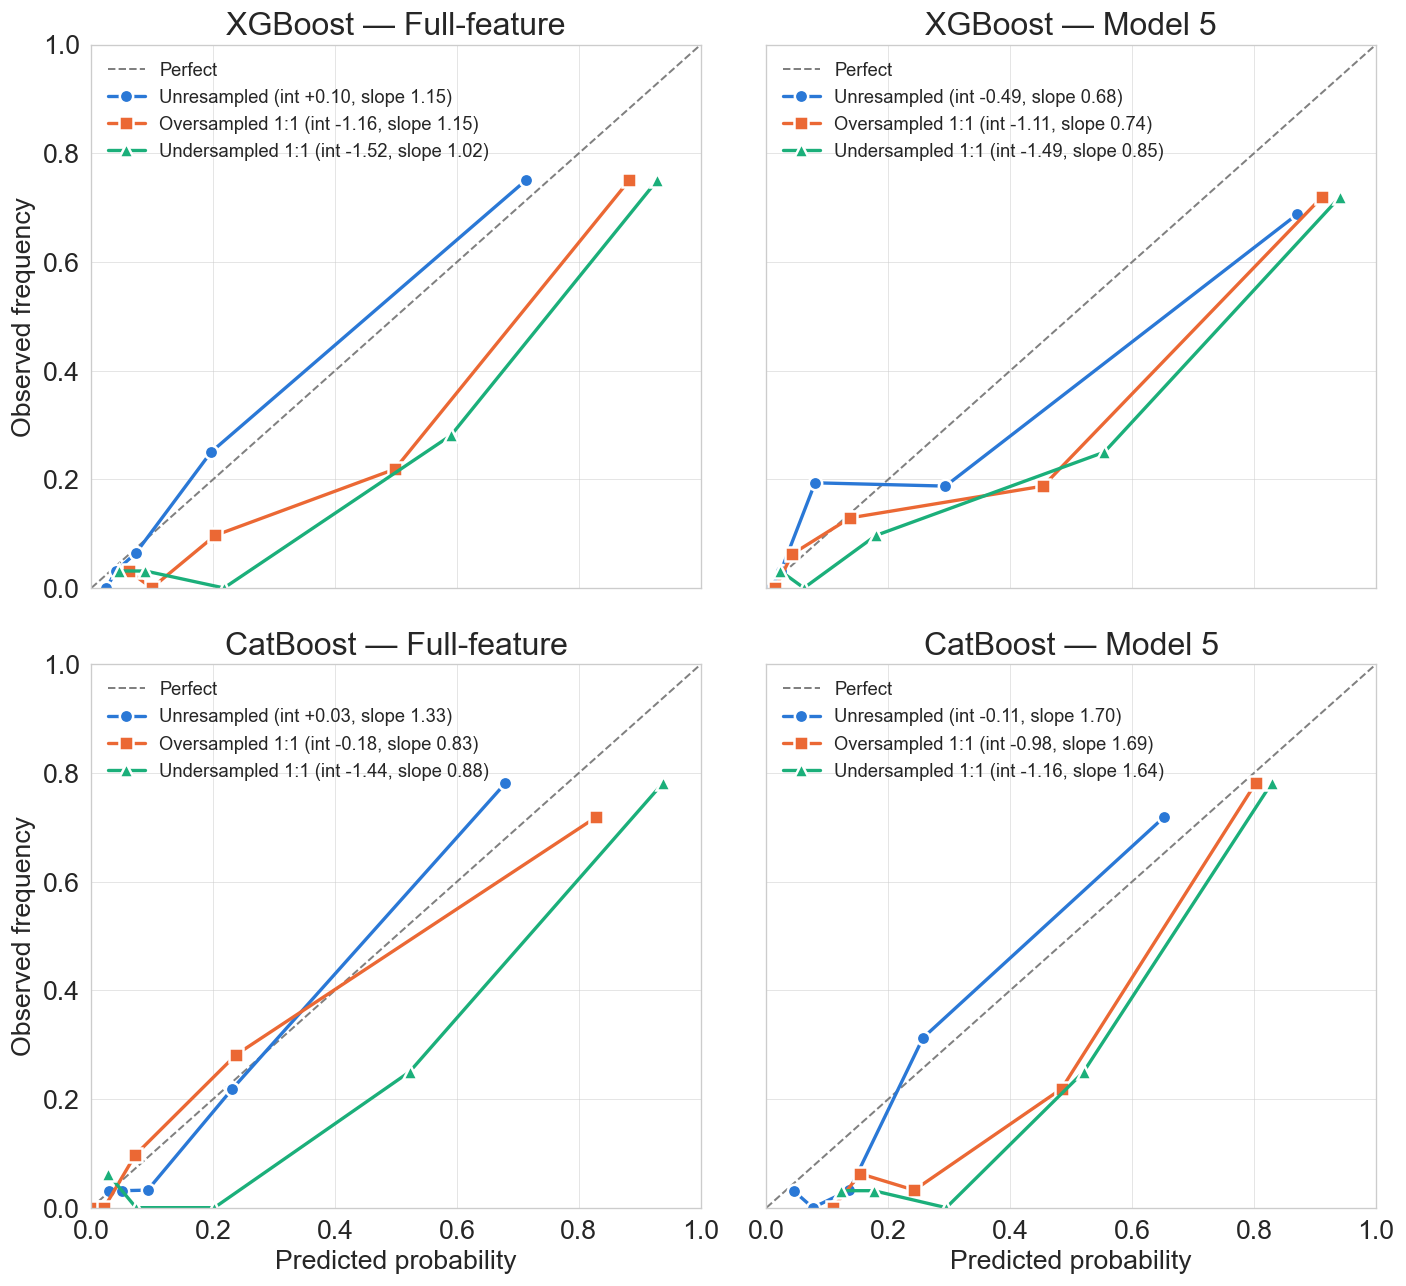

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/rev_calibration_resampling_sensitivity.png


In [29]:
# R1.3 Resampling sensitivity: random oversampling of TB cases / undersampling of non-cases to 1:1
# Applied ONLY to training data inside each fold: inner-train folds during tuning (inner validation and
# early-stopping sets untouched), training folds of the 5-fold OOF used for the threshold, and the final
# refit on the 636 training rows. OOF predictions, thresholds and the test set use unresampled data.
# Everything else is identical: same features (full-feature; M5 set from the main RFE), search spaces,
# seeds, spec>=TARGET_SPEC threshold rule. SCALE_POS is the class ratio of the resampled training data (1.0).
def make_resampler(kind, seed=RANDOM_STATE):
    def _resample(X_tr, y_tr):
        rng = np.random.default_rng(seed)
        y_arr = np.asarray(y_tr).astype(int)
        pos, neg = np.flatnonzero(y_arr == 1), np.flatnonzero(y_arr == 0)
        assert len(neg) > len(pos)
        if kind == "oversample":
            idx = np.concatenate([neg, pos, rng.choice(pos, size=len(neg) - len(pos), replace=True)])
        else:
            idx = np.concatenate([pos, rng.choice(neg, size=len(pos), replace=False)])
        idx = rng.permutation(idx)
        return X_tr.iloc[idx], y_tr.iloc[idx]
    return _resample

def fit_resampled(algo, feats):
    Xr, yr = apply_resampler(align_categoricals(X_train_full[feats]), y_train_full)
    if algo == "XGB":
        (params, rounds), _ = tune_xgb_params_auc(X_train_full, y_train_full, feats, RANDOM_STATE)
        params = dict(params); params.setdefault("verbosity", 0)
        booster = xgb_train(params, DMatrix(Xr, label=yr, enable_categorical=True),
                            num_boost_round=rounds, verbose_eval=False)
        return {"model": booster, "feats": feats, "params": params, "rounds": rounds}
    params, _ = tune_cat_params_auc(X_train_full, y_train_full, feats, RANDOM_STATE)
    params = _clean_cat_verbose(params)
    cat_idx = [Xr.columns.get_loc(c) for c in CATS if c in Xr.columns]
    model = CatBoostClassifier(**params)
    model.fit(Pool(Xr, yr, cat_features=cat_idx or None))
    return {"model": model, "feats": feats, "params": params}

# calibration_intercept_slope is defined with the shared helpers in cell 13
def bootstrap_calib_ci(y, p, B=N_BOOT, seed=BOOT_SEED):
    y = np.asarray(y).astype(int); p = as_proba(p)
    rng = np.random.default_rng(seed); n = len(y); ints, slopes = [], []
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        if y[idx].min() == y[idx].max():
            continue
        a, b = calibration_intercept_slope(y[idx], p[idx])
        ints.append(a); slopes.append(b)
    return tuple(np.percentile(ints, [2.5, 97.5])), tuple(np.percentile(slopes, [2.5, 97.5]))

RESAMPLING = OrderedDict([("Unresampled", None), ("Oversampled 1:1", "oversample"), ("Undersampled 1:1", "undersample")])
rs_evals = {}
for algo, full_eval, st_eval in [("XGB", full_eval_xgb, stage_eval_xgb), ("CAT", full_eval_cat, stage_eval_cat)]:
    rs_evals[(algo, "Full-feature", "Unresampled")] = full_eval["Full-feature"]
    rs_evals[(algo, "Model 5", "Unresampled")] = st_eval["Model 5"]

_SCALE_POS_MAIN = SCALE_POS
for scheme, kind in RESAMPLING.items():
    if kind is None:
        continue
    RESAMPLER, SCALE_POS, WEIGHT_CONTEXT = make_resampler(kind), 1.0, f"R1.3 {scheme}"
    try:
        for algo, models in [("XGB", final_models_xgb), ("CAT", final_models_cat)]:
            bundles = OrderedDict()
            for name, feats in [("Full-feature", full_feats), ("Model 5", list(models["Model 5"]["feats"]))]:
                bundles[name] = fit_resampled(algo, feats)
                log_weighting(f"{name} ({scheme})", algo, bundles[name]["params"])
            _, _, ev = stage_metrics_table(algo, bundles, X_train_full, y_train_full, X_test_full, y_test_full)
            for name in bundles:
                rs_evals[(algo, name, scheme)] = ev[name]
    finally:
        RESAMPLER, SCALE_POS, WEIGHT_CONTEXT = None, _SCALE_POS_MAIN, "main"

y_te_arr = y_test_full.to_numpy().astype(int)
rs_rows = []
for algo in ["XGB", "CAT"]:
    for name in ["Full-feature", "Model 5"]:
        for scheme in RESAMPLING:
            ev = rs_evals[(algo, name, scheme)]
            a, b = calibration_intercept_slope(y_te_arr, ev["p_test"])
            (a_lo, a_hi), (b_lo, b_hi) = bootstrap_calib_ci(y_te_arr, ev["p_test"])
            fmt = lambda k: f"{ev['point'][k]:.3f} ({ev['ci'][k][0]:.3f}, {ev['ci'][k][1]:.3f})"
            rs_rows.append({"Algorithm": ALGO_NAME[algo], "Model": name, "Resampling": scheme,
                            "AUROC": fmt("AUROC"), "AP": fmt("AP"), "Brier": fmt("Brier"),
                            "Null Brier": round(ev["null_brier"], 3), "Brier (recal.)": fmt_brier_cal(ev),
                            "Trees": ev["trees"],
                            "Calib intercept": f"{a:.3f} ({a_lo:.3f}, {a_hi:.3f})",
                            "Calib slope": f"{b:.3f} ({b_lo:.3f}, {b_hi:.3f})",
                            "Sens": fmt("Sens"), "Spec": fmt("Spec"), "Thr": round(ev["thr"], 4)})
rs_df = pd.DataFrame(rs_rows)
rs_df.to_csv(f"{CSV_DIR}/rev_resampling_sensitivity.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print(f"=== R1.3 Resampling sensitivity (test n={len(y_te_arr)}, 95% bootstrap CI; thr from train OOF at Spec>={TARGET_SPEC:.2f}) ===")
    print(rs_df.to_string(index=False))

# ---- Calibration curves: unresampled vs oversampled vs undersampled (test set) ----
RS_STYLE = {"Unresampled": ("#2a78d6", "o"), "Oversampled 1:1": ("#eb6834", "s"), "Undersampled 1:1": ("#1baf7a", "^")}
CALIB_BINS = 5  # quantile bins; test set has ~35 cases
fig, axes = plt.subplots(2, 2, figsize=(12, 11), sharex=True, sharey=True)
for r, algo in enumerate(["XGB", "CAT"]):
    for c, name in enumerate(["Full-feature", "Model 5"]):
        ax = axes[r, c]
        ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color="gray", label="Perfect")
        for scheme in RESAMPLING:
            p = rs_evals[(algo, name, scheme)]["p_test"]
            pt, pp = calibration_curve(y_te_arr, p, n_bins=CALIB_BINS, strategy="quantile")
            a, b = calibration_intercept_slope(y_te_arr, p)
            color, marker = RS_STYLE[scheme]
            ax.plot(pp, pt, lw=2, color=color, marker=marker, markersize=8,
                    markeredgecolor="white", markeredgewidth=1.5,
                    label=f"{scheme} (int {a:+.2f}, slope {b:.2f})")
        ax.set_title(f"{ALGO_NAME[algo]} — {name}")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, linewidth=0.5, alpha=0.6)
        ax.legend(frameon=False, loc="upper left", fontsize=11)
        if r == 1: ax.set_xlabel("Predicted probability")
        if c == 0: ax.set_ylabel("Observed frequency")
plt.tight_layout()
out_img = f"{IMG_DIR}/rev_calibration_resampling_sensitivity.png"
plt.savefig(out_img, dpi=300, bbox_inches="tight"); plt.show()
print("Saved:", out_img)


# R2.5–2.7 Part 1: age-group counts
n and TB cases, ages 5–14 vs ≥ 15.

In [30]:
# R2.5–2.7 Part 1: n and TB cases by age group (5–14 vs >=15) in train, test and total
def _age_band(age):
    return np.where(pd.to_numeric(age) < 15, "5–14", "≥15")

age_rows = []
# uses df0 for the total: the global names X / y are reused as loop variables in earlier figure cells
for set_name, X_, y_ in [("Train", feature_train, target_train), ("Test", feature_test, target_test),
                         ("Total", df0, df0["TB_status"])]:
    band = _age_band(X_["age"]); y_arr = np.asarray(y_).astype(int)
    row = {"Set": set_name}
    for b in ["5–14", "≥15"]:
        row[f"Age {b}: n"] = int((band == b).sum())
        row[f"Age {b}: TB cases"] = int(y_arr[band == b].sum())
    row["All ages: n"], row["All ages: TB cases"] = len(y_arr), int(y_arr.sum())
    age_rows.append(row)
age_counts = pd.DataFrame(age_rows)
age_counts.to_csv(f"{CSV_DIR}/rev_age_group_counts.csv", index=False)
print(age_counts.to_string(index=False))


  Set  Age 5–14: n  Age 5–14: TB cases  Age ≥15: n  Age ≥15: TB cases  All ages: n  All ages: TB cases
Train           43                   6         593                135          636                 141
 Test            8                   1         151                 34          159                  35
Total           51                   7         744                169          795                 176


# R2.5–2.7 Part 2: age ≥ 15 sensitivity analysis
Train and test restricted to age ≥ 15 (same split); RFE and M1–M5 re-run.

In [31]:
# R2.5–2.7 Part 2: Age >= 15 sensitivity analysis (train and test restricted to age >= 15; same split)
adult_tr = pd.to_numeric(X_train_full["age"]) >= 15
adult_te = pd.to_numeric(X_test_full["age"]) >= 15
X_tr_adult, y_tr_adult = X_train_full[adult_tr], y_train_full[adult_tr]
X_te_adult, y_te_adult = X_test_full[adult_te], y_test_full[adult_te]

adult_run = run_staged_pipeline("Age>=15", "age15plus", X_tr_adult, y_tr_adult, X_te_adult, y_te_adult)

y_te_main = y_test_full.to_numpy().astype(int)
y_te_ad   = y_te_adult.to_numpy().astype(int)
adult_rows = []
for algo in ["XGB", "CAT"]:
    for st in stage_new:
        main_ev = MAIN_RUN[algo]["evals"][st]
        main_feats = MAIN_RUN[algo]["models"][st]["feats"]
        adult_rows.append(eval_row(algo, st, "Main analysis (all ages)", main_ev, y_te_main, main_feats))
        # main models and thresholds, scored on the same age>=15 test rows (same patients as the rerun)
        adult_rows.append(eval_row(algo, st, "Main models, age>=15 test rows",
                                   subset_eval(main_ev, adult_te.to_numpy(), y_te_ad), y_te_ad, main_feats))
        adult_rows.append(eval_row(algo, st, "Re-run on age>=15", adult_run[algo]["evals"][st], y_te_ad,
                                   adult_run[algo]["models"][st]["feats"]))
adult_df = pd.DataFrame(adult_rows)
adult_df.to_csv(f"{CSV_DIR}/rev_age15plus_sensitivity.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print(adult_df.drop(columns="Features").to_string(index=False))


[Age>=15] train n=593 (TB=135) | test n=151 (TB=34) | SCALE_POS=3.393


Algorithm   Model                       Analysis  n_test  TB_test  n_feats                 Sens                 Spec                  PPV                  NPV                AUROC                   AP                Brier  Null Brier       Brier (recal.)    Thr
  XGBoost Model 1       Main analysis (all ages)     159       35       10 0.571 (0.394, 0.737) 0.685 (0.596, 0.766) 0.339 (0.221, 0.474) 0.850 (0.765, 0.914) 0.629 (0.519, 0.740) 0.329 (0.224, 0.494) 0.239 (0.215, 0.264)       0.172 0.169 (0.134, 0.205) 0.5532
  XGBoost Model 1 Main models, age>=15 test rows     151       34       10 0.559 (0.379, 0.728) 0.675 (0.582, 0.759) 0.333 (0.214, 0.471) 0.840 (0.750, 0.908) 0.624 (0.514, 0.727) 0.330 (0.219, 0.495) 0.242 (0.216, 0.268)       0.174 0.174 (0.138, 0.212) 0.5532
  XGBoost Model 1              Re-run on age>=15     151       34       10 0.529 (0.351, 0.702) 0.650 (0.556, 0.735) 0.305 (0.192, 0.439) 0.826 (0.733, 0.897) 0.603 (0.489, 0.712) 0.312 (0.199, 0.461) 0.172 (0.136,

# R2.5–2.7 Part 3: QFT-excluded sensitivity analysis
QFT dropped from every stage; RFE and M1–M5 re-run.

In [32]:
# R2.5–2.7 Part 3: QFT-excluded sensitivity analysis (QFT_result_composite dropped from all stages)
stage_new_noqft = OrderedDict((st, [f for f in feats if f != "QFT_result_composite"]) for st, feats in stage_new.items())
assert all("QFT_result_composite" not in f for f in stage_new_noqft.values())
X_tr_noqft = X_train_full.drop(columns=["QFT_result_composite"])
X_te_noqft = X_test_full.drop(columns=["QFT_result_composite"])

noqft_run = run_staged_pipeline("QFT excluded", "noQFT", X_tr_noqft, y_train_full, X_te_noqft, y_test_full,
                                stages=stage_new_noqft)

noqft_rows = []
for algo in ["XGB", "CAT"]:
    for st in stage_new:
        noqft_rows.append(eval_row(algo, st, "Main analysis", MAIN_RUN[algo]["evals"][st], y_te_main,
                                   MAIN_RUN[algo]["models"][st]["feats"]))
        noqft_rows.append(eval_row(algo, st, "QFT excluded", noqft_run[algo]["evals"][st], y_te_main,
                                   noqft_run[algo]["models"][st]["feats"]))
noqft_df = pd.DataFrame(noqft_rows)
noqft_df.to_csv(f"{CSV_DIR}/rev_qft_excluded_sensitivity.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print(noqft_df.drop(columns="Features").to_string(index=False))
print("\n=== Model 5 feature lists ===")
for _, r in noqft_df[noqft_df["Model"] == "Model 5"].iterrows():
    print(f"{r['Algorithm']} — {r['Analysis']} ({r['n_feats']}): {r['Features']}")


[QFT excluded] train n=636 (TB=141) | test n=159 (TB=35) | SCALE_POS=3.511


Algorithm   Model      Analysis  n_test  TB_test  n_feats                 Sens                 Spec                  PPV                  NPV                AUROC                   AP                Brier  Null Brier       Brier (recal.)    Thr
  XGBoost Model 1 Main analysis     159       35       10 0.571 (0.394, 0.737) 0.685 (0.596, 0.766) 0.339 (0.221, 0.474) 0.850 (0.765, 0.914) 0.629 (0.519, 0.740) 0.329 (0.224, 0.494) 0.239 (0.215, 0.264)       0.172 0.169 (0.134, 0.205) 0.5532
  XGBoost Model 1  QFT excluded     159       35        9 0.514 (0.340, 0.686) 0.694 (0.604, 0.773) 0.321 (0.203, 0.460) 0.835 (0.749, 0.901) 0.642 (0.532, 0.748) 0.319 (0.218, 0.483) 0.231 (0.209, 0.254)       0.172 0.166 (0.133, 0.200) 0.5229
  XGBoost Model 2 Main analysis     159       35       15 0.600 (0.421, 0.761) 0.677 (0.588, 0.759) 0.344 (0.227, 0.477) 0.857 (0.772, 0.920) 0.663 (0.550, 0.773) 0.391 (0.258, 0.562) 0.250 (0.217, 0.286)       0.172 0.163 (0.127, 0.200) 0.5771
  XGBoost Model 2  Q

# R2.5–2.7 Part 4: subgroup performance (exploratory)
5-fold OOF over all 795 participants with each algorithm's fixed M5 features and hyperparameters.

In [33]:
# R2.5–2.7 Part 4: Subgroup performance (exploratory) — 5-fold OOF over all 795 participants
# Each algorithm's fixed M5 feature set and tuned hyperparameters (tuned on the 636 training rows) are refit
# within 5 stratified folds of all 795 participants. Sens/spec use the fixed M5 threshold from R1.2
# (training OOF), so no threshold is chosen on test rows. CIs: 2,000 bootstrap resamples within subgroup.
# Exploratory: the 636 training rows also informed feature selection and tuning, so estimates are optimistic.
X_795 = pd.concat([X_train_full, X_test_full]).sort_index()
y_795 = pd.concat([y_train_full, y_test_full]).loc[X_795.index].astype(int)
assert len(X_795) == len(df0) == 795 and X_795.index.is_unique

age795 = pd.to_numeric(X_795["age"]).to_numpy()
diab795 = X_795["diabetes"].astype(str).to_numpy()
SUBGROUPS = OrderedDict([
    ("All participants", np.ones(len(X_795), bool)),
    ("Age 5–14", age795 < 15), ("Age 15–34", (age795 >= 15) & (age795 <= 34)),
    ("Age 35–54", (age795 >= 35) & (age795 <= 54)), ("Age ≥55", age795 >= 55),
    ("Diabetes: yes", diab795 == "diabetes"), ("Diabetes: no", diab795 == "no_diabetes"),
])
assert sum(SUBGROUPS[g].sum() for g in ["Age 5–14", "Age 15–34", "Age 35–54", "Age ≥55"]) == 795
assert SUBGROUPS["Diabetes: yes"].sum() + SUBGROUPS["Diabetes: no"].sum() == 795

y795 = y_795.to_numpy()
sub_rows, oof795 = [], {}
for algo in ["XGB", "CAT"]:
    bundle, thr = MAIN_RUN[algo]["models"]["Model 5"], MAIN_RUN[algo]["evals"]["Model 5"]["thr"]
    oof795[algo] = oof_probs_fixed_params(algo, bundle, X_795, y_795)
    for g, mask in SUBGROUPS.items():
        yg, pg = y795[mask], oof795[algo][mask]
        ci = test_ci(yg, pg, thr)
        pt = metrics_at_thr(yg, pg, thr)
        fmt = lambda k: f"{pt[k]:.3f} ({ci[k][0]:.3f}, {ci[k][1]:.3f})"
        sub_rows.append({"Algorithm": ALGO_NAME[algo], "Subgroup": g, "n": int(mask.sum()), "TB cases": int(yg.sum()),
                         "AUROC": fmt("AUROC"), "AP": fmt("AP"), "Sens": fmt("Sens"), "Spec": fmt("Spec"),
                         "Brier": fmt("Brier"), "Null Brier": round(null_brier(yg, y_train_full), 3),
                         "Thr (fixed M5)": round(thr, 4),
                         "Flag": "<10 TB cases — interpret with caution" if yg.sum() < 10 else ""})
sub_df = pd.DataFrame(sub_rows)
sub_df.to_csv(f"{CSV_DIR}/rev_subgroup_performance_oof795.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print("=== Subgroup performance, M5, 5-fold OOF over all 795 (exploratory) ===")
    print(sub_df.to_string(index=False))


=== Subgroup performance, M5, 5-fold OOF over all 795 (exploratory) ===
Algorithm         Subgroup   n  TB cases                AUROC                   AP                 Sens                 Spec                Brier  Null Brier  Thr (fixed M5)                                  Flag
  XGBoost All participants 795       176 0.905 (0.879, 0.930) 0.765 (0.702, 0.832) 0.898 (0.843, 0.938) 0.722 (0.685, 0.757) 0.096 (0.082, 0.111)       0.172          0.1303                                      
  XGBoost         Age 5–14  51         7 0.886 (0.612, 1.000) 0.838 (0.501, 1.000) 0.857 (0.421, 0.996) 0.727 (0.572, 0.850) 0.053 (0.012, 0.112)       0.126          0.1303 <10 TB cases — interpret with caution
  XGBoost        Age 15–34 339        85 0.904 (0.862, 0.940) 0.776 (0.676, 0.875) 0.871 (0.780, 0.934) 0.748 (0.690, 0.800) 0.097 (0.073, 0.122)       0.189          0.1303                                      
  XGBoost        Age 35–54 246        47 0.915 (0.872, 0.952) 0.786 (0.681, 0.87

# R3.2 Participants without a chest X-ray
Included vs excluded comparison; M1/M2 on all eligible participants (new split); main M1/M2 models scored on the participants without CXR.

In [34]:
# R3.2 Participants without a chest X-ray
# Eligible = all enrolled Pakistan participants (n=1,129, master v3.0-08.30.24, sheet "Dataset") with a valid
# outcome: the 18 culture-"Contaminated" participants (labelled only in the 3.17.25 master, the file that
# defined the modeling cohort) are excluded -> n=1,111. CXR available = numeric qXR Score (the 795 modeling
# rows); no CXR = "No scan" or "Not in Qure dataset" (316). Recoding replicates R scripts/Practicum data
# prep.Rmd; it is checked below to reproduce the modeling file exactly for the 795.
MASTER_317 = "/Users/hbattey/Desktop/Rodwell/Datasets/master/TB_Antigen_Clinical_Data_Master_3.17.25.xlsx"
raw = pd.read_excel(master_tb_file, sheet_name="Dataset")
raw = raw[raw["Country"] == "Pakistan"].copy()
q317 = pd.read_excel(MASTER_317, sheet_name="Dataset", usecols=["record_id", "Score", "TB_status"])
raw = raw.merge(q317.rename(columns={"Score": "Score_317", "TB_status": "TB_status_317"}),
                on="record_id", how="left", validate="one_to_one").set_index("record_id")
assert len(raw) == 1129 and raw["TB_status_317"].notna().all()

M12_VARS = baseline_vars + clinical_vars
elig = pd.DataFrame(index=raw.index)
elig["age"]    = pd.to_numeric(raw["age"])
elig["gender"] = raw["gender"]
elig["race_collapsed"] = np.where(raw["race___2"] == "Checked", "asian", "other")
elig["bmi"]      = pd.to_numeric(raw["weight"]) / pd.to_numeric(raw["height"]) ** 2
elig["diabetes"] = raw["comorbitity___2"].map({"Checked": "diabetes", "Unchecked": "no_diabetes"})
elig["asthma"]   = raw["comorbitity___7"].map({"Checked": "asthma", "Unchecked": "no_asthma"})
elig["bcg"]      = raw["bcg"].map({"Yes": "yes", "No": "no", "Don't know": "idk"}).fillna("idk")
elig["lived_with_another_tb"] = raw["lived_with_another_tb"].map({"Yes": "yes", "No": "no", "Don't know": "no"})
elig["tb_history_prior"]  = raw["tb_history_foreign_interview"].map({"Yes": "Yes", "No": "No", "Don't know": "No"})  # [REV-0.6]
elig["QFT_result_composite"]  = raw["QFT_result_composite"].replace({"Positive*": "Positive"})
for i, v in enumerate(clinical_vars, 1):
    elig[v] = np.where(raw[f"symptoms___{i}"] == "Checked", "yes", "no")
elig["TB_status"] = raw["TB_status"].map({"ATB": 1, "Not Active TB": 0})
score_txt = raw["Score_317"].astype(str)
elig["CXR group"] = np.where(score_txt.isin(["No scan", "Not in Qure dataset"]), score_txt, "CXR available")
assert elig[M12_VARS + ["TB_status"]].notna().all().all()

valid = raw["TB_status_317"] != "Contaminated"
print(f"Enrolled Pakistan participants: {len(elig)} | excluded, contaminated culture: {int((~valid).sum())} | eligible: {int(valid.sum())}")
print(pd.crosstab(elig.loc[valid, "CXR group"], elig.loc[valid, "TB_status"].map({1: "TB disease", 0: "No TB disease"}),
                  margins=True, margins_name="Total"))
elig = elig[valid]

# Check: the CXR-available participants are exactly the modeling cohort, with identical M1/M2 variables
cxr_ids = elig.index[elig["CXR group"] == "CXR available"]
main_m = df0.set_index("record_id")
assert set(cxr_ids) == set(main_m.index), "CXR-available set differs from the modeling cohort"
for v in M12_VARS + ["TB_status"]:
    a_, b_ = elig.loc[cxr_ids, v], main_m.loc[cxr_ids, v]
    same = np.isclose(a_, b_).all() if v in ("age", "bmi") else (a_.astype(str) == b_.astype(str)).all()
    assert same, f"recoding mismatch for {v}"
print("Recoding check passed: CXR-available rows reproduce the modeling file for all M1/M2 variables.")

# ---- (1) Included (CXR available) vs excluded (no CXR): same tests as Table 1 ----
R32_VARS = [("age", "cont"), ("gender", "cat"), ("bmi", "cont")] + [(v, "cat") for v in clinical_vars] + \
           [("tb_history_prior", "cat"), ("QFT_result_composite", "cat"), ("TB_status", "cat")]
inc = (elig["CXR group"] == "CXR available").astype(int)
grp_cols = OrderedDict([
    (f"Included: CXR available (N={int(inc.sum())})", elig["CXR group"] == "CXR available"),
    (f"Excluded: no CXR (N={int((inc == 0).sum())})", inc == 0),
    (f"  of which No scan (N={int((elig['CXR group'] == 'No scan').sum())})", elig["CXR group"] == "No scan"),
    (f"  of which Not in Qure (N={int((elig['CXR group'] == 'Not in Qure dataset').sum())})", elig["CXR group"] == "Not in Qure dataset"),
])
cxr_rows = []
for v, kind in R32_VARS:
    label = "TB disease" if v == "TB_status" else rename_dict.get(v, v)
    if kind == "cont":
        s = elig[v]
        _, p = ttest_ind(s[inc == 1], s[inc == 0], equal_var=True)
        row = {"Variable": f"{label}, mean (SD)", "Level": ""}
        for col, mask in grp_cols.items():
            row[col] = f"{s[mask].mean():.1f} ({s[mask].std(ddof=1):.1f})"
        cxr_rows.append({**row, "p-value (included vs excluded)": fmt_p(p), "Test": "t-test"})
    else:
        s = elig[v].map({1: "Yes", 0: "No"}) if v == "TB_status" else elig[v]
        ct = pd.crosstab(s, inc).reindex(columns=[1, 0], fill_value=0)
        p, test = cat_test(ct.to_numpy())
        for j, lvl in enumerate(ct.index):
            row = {"Variable": f"{label}, n (%)" if j == 0 else "", "Level": _lvl(lvl)}
            for col, mask in grp_cols.items():
                n_lvl, n_col = int((s[mask] == lvl).sum()), int(mask.sum())
                row[col] = f"{n_lvl} ({100 * n_lvl / n_col:.1f})"
            cxr_rows.append({**row, "p-value (included vs excluded)": fmt_p(p) if j == 0 else "",
                             "Test": test if j == 0 else ""})
cxr_cmp = pd.DataFrame(cxr_rows)
cxr_cmp.to_csv(f"{CSV_DIR}/rev_cxr_included_vs_excluded.csv", index=False)
with pd.option_context("display.width", 260, "display.max_rows", 200, "display.max_colwidth", 45):
    print(cxr_cmp.to_string(index=False))

# ---- (2) M1 and M2 on all eligible participants: new stratified 80/20 split (seed 42) ----
X_elig = elig[M12_VARS].copy()
for c in X_elig.columns:
    if X_elig[c].dtype == object:
        X_elig[c] = X_elig[c].astype("category")
y_elig = elig["TB_status"].astype(int)
X_tr_el, X_te_el, y_tr_el, y_te_el = train_test_split(X_elig, y_elig, test_size=0.20,
                                                      random_state=split_seed, stratify=y_elig)
print(f"All-eligible split: train n={len(y_tr_el)} (TB={int(y_tr_el.sum())}) | test n={len(y_te_el)} (TB={int(y_te_el.sum())})")
print("Test rows with CXR available:", int((elig.loc[X_te_el.index, "CXR group"] == "CXR available").sum()))

stages_12 = OrderedDict((st, stage_new[st]) for st in ["Model 1", "Model 2"])
_CAT_DTYPES_MAIN = _CAT_DTYPES
_CAT_DTYPES = build_cat_dtypes_from_train(X_tr_el, CATS)  # category levels from the NEW training set only
try:
    X_tr_el, X_te_el = align_categoricals(X_tr_el), align_categoricals(X_te_el)
    elig_run = run_staged_pipeline("All eligible (M1-M2)", "all_eligible_M1M2",
                                   X_tr_el, y_tr_el, X_te_el, y_te_el, stages=stages_12)
finally:
    _CAT_DTYPES = _CAT_DTYPES_MAIN

y_te_el_arr = y_te_el.to_numpy().astype(int)
el_rows = []
for algo in ["XGB", "CAT"]:
    for st in stages_12:
        el_rows.append(eval_row(algo, st, "CXR-restricted (main, n=795)", MAIN_RUN[algo]["evals"][st], y_te_main,
                                MAIN_RUN[algo]["models"][st]["feats"]))
        el_rows.append(eval_row(algo, st, f"All eligible (n={len(elig)})", elig_run[algo]["evals"][st], y_te_el_arr,
                                elig_run[algo]["models"][st]["feats"]))
el_df = pd.DataFrame(el_rows)
el_df.to_csv(f"{CSV_DIR}/rev_all_eligible_M1M2_vs_cxr_restricted.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20, "display.max_colwidth", 80):
    print(el_df.drop(columns="Features").to_string(index=False))
    print("\n=== Feature sets ===")
    for _, r in el_df.iterrows():
        print(f"{r['Algorithm']} {r['Model']} — {r['Analysis']}: {r['Features']}")

# ---- (3) Main CXR-trained M1/M2 models (fixed thresholds) scored on the participants without a CXR ----
# None of these participants were used for training, feature selection, tuning or thresholds; M1/M2 inputs
# are complete for them (checked above). Category levels use the main training map (restored above).
nocxr = elig[elig["CXR group"] != "CXR available"]
X_nocxr = align_categoricals(nocxr[M12_VARS])
y_nocxr = nocxr["TB_status"].to_numpy().astype(int)
print(f"\nNo-CXR participants: n={len(y_nocxr)} (TB={int(y_nocxr.sum())})")
hold_rows = []
for algo in ["XGB", "CAT"]:
    for st in stages_12:
        bundle, main_ev = MAIN_RUN[algo]["models"][st], MAIN_RUN[algo]["evals"][st]
        p_no = stage_test_probs(algo, bundle, X_nocxr)
        ev_no = fixed_thr_eval(p_no, y_nocxr, main_ev["thr"], y_train_full, main_ev["platt"])
        hold_rows.append(eval_row(algo, st, f"Main model, CXR test set (n={len(y_te_main)})", main_ev, y_te_main, bundle["feats"]))
        hold_rows.append(eval_row(algo, st, f"Main model, no-CXR participants (n={len(y_nocxr)})", ev_no, y_nocxr, bundle["feats"]))
hold_df = pd.DataFrame(hold_rows)
hold_df.to_csv(f"{CSV_DIR}/rev_noCXR_holdout_M1M2.csv", index=False)
with pd.option_context("display.width", 260, "display.max_columns", 20):
    print(hold_df.drop(columns="Features").to_string(index=False))


Enrolled Pakistan participants: 1129 | excluded, contaminated culture: 18 | eligible: 1111
TB_status            No TB disease  TB disease  Total
CXR group                                            
CXR available                  619         176    795
No scan                        205          84    289
Not in Qure dataset             23           4     27
Total                          847         264   1111
Recoding check passed: CXR-available rows reproduce the modeling file for all M1/M2 variables.
                             Variable         Level Included: CXR available (N=795) Excluded: no CXR (N=316)   of which No scan (N=289)   of which Not in Qure (N=27) p-value (included vs excluded)       Test
                       Age, mean (SD)                                   37.0 (17.3)              39.0 (16.9)                39.1 (17.2)                   37.7 (13.6)                          0.091     t-test
                           Sex, n (%)        Female                      4

Algorithm   Model                     Analysis  n_test  TB_test  n_feats                 Sens                 Spec                  PPV                  NPV                AUROC                   AP                Brier  Null Brier       Brier (recal.)    Thr
  XGBoost Model 1 CXR-restricted (main, n=795)     159       35       10 0.571 (0.394, 0.737) 0.685 (0.596, 0.766) 0.339 (0.221, 0.474) 0.850 (0.765, 0.914) 0.629 (0.519, 0.740) 0.329 (0.224, 0.494) 0.239 (0.215, 0.264)       0.172 0.169 (0.134, 0.205) 0.5532
  XGBoost Model 1        All eligible (n=1111)     223       53       10 0.679 (0.537, 0.801) 0.653 (0.576, 0.724) 0.379 (0.281, 0.484) 0.867 (0.796, 0.921) 0.700 (0.626, 0.775) 0.369 (0.281, 0.503) 0.206 (0.184, 0.229)       0.181 0.168 (0.144, 0.194) 0.4754
  XGBoost Model 2 CXR-restricted (main, n=795)     159       35       15 0.600 (0.421, 0.761) 0.677 (0.588, 0.759) 0.344 (0.227, 0.477) 0.857 (0.772, 0.920) 0.663 (0.550, 0.773) 0.391 (0.258, 0.562) 0.250 (0.217, 0.286) 

Algorithm   Model                                Analysis  n_test  TB_test  n_feats                 Sens                 Spec                  PPV                  NPV                AUROC                   AP                Brier  Null Brier       Brier (recal.)    Thr
  XGBoost Model 1        Main model, CXR test set (n=159)     159       35       10 0.571 (0.394, 0.737) 0.685 (0.596, 0.766) 0.339 (0.221, 0.474) 0.850 (0.765, 0.914) 0.629 (0.519, 0.740) 0.329 (0.224, 0.494) 0.239 (0.215, 0.264)       0.172 0.169 (0.134, 0.205) 0.5532
  XGBoost Model 1 Main model, no-CXR participants (n=316)     316       88       10 0.580 (0.470, 0.684) 0.737 (0.675, 0.793) 0.459 (0.364, 0.557) 0.820 (0.760, 0.870) 0.706 (0.637, 0.769) 0.482 (0.387, 0.590) 0.206 (0.188, 0.224)       0.204 0.185 (0.157, 0.212) 0.5532
  XGBoost Model 2        Main model, CXR test set (n=159)     159       35       15 0.600 (0.421, 0.761) 0.677 (0.588, 0.759) 0.344 (0.227, 0.477) 0.857 (0.772, 0.920) 0.663 (0.550, 0.773

# REV-0.1 Class-weighting audit
Runs last so it covers every model fitted in this notebook.

In [35]:
# REV-0.1 Class-weighting audit (XGBoost scale_pos_weight fix)
audit = pd.DataFrame(WEIGHT_LOG)
audit["Group"] = audit["Source"].str.replace(r" fold \d+$", "", regex=True).str.replace(r" \(Model \d\)$", "", regex=True)
audit.to_csv(f"{CSV_DIR}/rev_class_weighting_audit.csv", index=False)

audit_summary = (audit.groupby(["Outcome", "Group", "Algo"], sort=False)
                      .agg(n_models=("Weighted", "size"), n_weighted=("Weighted", "sum"))
                      .reset_index())
with pd.option_context("display.width", 250, "display.max_colwidth", 80):
    print("=== Class weighting actually applied (all fitted models) ===")
    print(audit_summary.to_string(index=False))
    print("\n=== Final models: per-model weighting ===")
    final_rows = audit[audit["Group"].isin(["PI refit (full train)", "Final M1-M5", f"Nested-CV OOF spec={TARGET_SPEC:.2f}"])]
    print(final_rows.drop_duplicates(["Outcome", "Source", "Algo"])[["Outcome", "Source", "Algo", "Weighted", "Detail"]].to_string(index=False))

main_final = final_rows[final_rows["Outcome"] == "main"]
for algo in ["XGB", "CAT"]:
    sub = main_final[main_final["Algo"] == algo]
    print(f"\n{algo}: {int(sub['Weighted'].sum())}/{len(sub)} main-analysis final models weighted")
claim_true = not main_final["Weighted"].any()
print(f'\n"Neither model used class weighting" is {"TRUE" if claim_true else "FALSE"} for the main-analysis final models.')
audit_summary.to_csv(f"{CSV_DIR}/rev_class_weighting_audit_summary.csv", index=False)


=== Class weighting actually applied (all fitted models) ===
                       Outcome                           Group Algo  n_models  n_weighted
                          main           PI refit (full train)  XGB         1           0
                          main           PI refit (full train)  CAT         1           0
                          main         Nested-CV OOF spec=0.70  CAT         5           4
                          main         Nested-CV OOF spec=0.70  XGB         5           3
                          main         Nested-CV OOF spec=0.75  CAT         5           5
                          main         Nested-CV OOF spec=0.75  XGB         5           4
                          main         Nested-CV OOF spec=0.80  CAT         5           1
                          main         Nested-CV OOF spec=0.80  XGB         5           2
                          main         Nested-CV OOF spec=0.85  CAT         5           2
                          main         